## Imports

In [1]:
import os

from alphagenome.data import genome
from alphagenome.visualization import plot_components
from alphagenome_research.model import dna_model
from alphagenome.models.v1 import variant_scorers
from alphagenome.models.v1 import dna_client
import matplotlib.pyplot as plt
import pandas as pd

## Local Model Alpha Genome

In [2]:
# Load model using persistent HF auth and local FASTA override
import dataclasses
import os
from pathlib import Path
from getpass import getpass
from huggingface_hub import whoami, login
import jax
from alphagenome_research.model import dna_model
from alphagenome.models.v1 import dna_model as public_dna_model
import fsspec


gpu_devices = [device for device in jax.local_devices() if device.platform == "gpu"]
if not gpu_devices:
    raise RuntimeError(
        "JAX cannot see a GPU in this notebook kernel. Restart the kernel and "
        "rerun this cell using this project's .venv interpreter on a GPU node."
    )


def ensure_hf_auth(allow_prompt=True):
    try:
        info = whoami()
        print(f"HF already authenticated as: {info.get('name', 'unknown')}")
        return
    except Exception:
        pass

    token = os.getenv("HF_TOKEN") or os.getenv("HUGGINGFACEHUB_API_TOKEN")
    if token:
        login(token=token, add_to_git_credential=False, skip_if_logged_in=True)
        info = whoami()
        print(f"HF authenticated via environment token as: {info.get('name', 'unknown')}")
        return

    if allow_prompt:
        try:
            token = getpass("Enter Hugging Face token (input hidden): ").strip()
        except Exception:
            token = ""

        if token:
            login(token=token, add_to_git_credential=False, skip_if_logged_in=True)
            info = whoami()
            print(f"HF authenticated via interactive prompt as: {info.get('name', 'unknown')}")
            return

    raise RuntimeError(
        "No Hugging Face credentials found. Use one of:\n"
        "1) Run `hf auth login` in a terminal\n"
        "2) Set HF_TOKEN (or HUGGINGFACEHUB_API_TOKEN)\n"
        "3) Re-run this cell and paste a token when prompted"
    )


def resolve_local_human_fasta_path():
    candidates = [
        os.getenv("ALPHAGENOME_FASTA"),
        "/data/Dcode/gaetano/repos/fasta_files/hg38.fa",
    ]
    for candidate in candidates:
        if candidate and Path(candidate).exists():
            return candidate
    return None


def resolve_local_mouse_fasta_path():
    candidates = [
        os.getenv("ALPHAGENOME_MOUSE_FASTA"),
        "/data/Dcode/gaetano/repos/fasta_files/mm10.fa",
        "/data/Dcode/gaetano/repos/fasta_files/mm39.fa",
    ]
    for candidate in candidates:
        if candidate and Path(candidate).exists():
            return candidate
    return None


ensure_hf_auth(allow_prompt=True)

human_fasta = resolve_local_human_fasta_path()
if not human_fasta:
    raise FileNotFoundError(
        "No local human FASTA found. Set ALPHAGENOME_FASTA to a local GRCh38 FASTA path, e.g.\n"
        "export ALPHAGENOME_FASTA=/path/to/GRCh38.p13.genome.fa"
    )

mouse_fasta = resolve_local_mouse_fasta_path()
if mouse_fasta:
    print(f"Using local mouse FASTA: {mouse_fasta}")
else:
    print(
        "No local mouse FASTA found; configuring mouse organism without local FASTA. "
        "Predictions on human intervals still work."
    )

print(f"Using local human FASTA: {human_fasta}")
# Default GENCODE GTF/PAS/splice-site annotations are required by gene-based scorers (e.g. RNA_SEQ).
human_defaults = dna_model.default_organism_settings()[public_dna_model.Organism.HOMO_SAPIENS]
calibration_path = fsspec.open_local(
    "simplecache::https://storage.googleapis.com/alphagenome/data/hg38/calibration_scores.pb",
    mode="rb",
    simplecache={"cache_storage": str(Path.home() / ".cache" / "alphagenome" / "calibration")},
    https={"client_kwargs": {"trust_env": True}},
)
print(f"Using cached human calibration: {calibration_path}")
organism_settings = {
    public_dna_model.Organism.HOMO_SAPIENS: dataclasses.replace(
        human_defaults, fasta_path=human_fasta, calibration_path=calibration_path
    ),
    public_dna_model.Organism.MUS_MUSCULUS: dna_model.OrganismSettings(
        fasta_path=mouse_fasta,
    ) if mouse_fasta else dna_model.OrganismSettings(),
}

model_device = gpu_devices[0]
print(f"Loading AlphaGenome on {model_device}")
model = dna_model.create_from_huggingface(
    "fold-1", organism_settings=organism_settings, device=model_device
)
print("Model loaded successfully.")

HF already authenticated as: tanoManzo
No local mouse FASTA found; configuring mouse organism without local FASTA. Predictions on human intervals still work.
Using local human FASTA: /data/Dcode/gaetano/repos/fasta_files/hg38.fa
Using cached human calibration: /home/manzog2/.cache/alphagenome/calibration/0585d986c32d2d3cffad0a580809f4fefbaa4a6750e26425bf76e6a959cf95ee
Loading AlphaGenome on cuda:0


Fetching 12 files:   0%|          | 0/12 [00:00<?, ?it/s]

Model loaded successfully.


In [3]:
output_metadata = model.output_metadata(dna_client.Organism.HOMO_SAPIENS).concatenate()
output_metadata

,name,strand,Assay title,ontology_curie,biosample_name,biosample_type,biosample_life_stage,data_source,endedness,genetically_modified,nonzero_mean,output_type,gtex_tissue,histone_mark,transcription_factor
0,CL:0000084 ATAC-seq,.,ATAC-seq,CL:0000084,T-cell,primary_cell,adult,encode,paired,False,0.739741,OutputType.ATAC,NaN,NaN,NaN
1,CL:0000100 ATAC-seq,.,ATAC-seq,CL:0000100,motor neuron,in_vitro_differentiated_cells,adult,encode,paired,False,0.273136,OutputType.ATAC,NaN,NaN,NaN
2,CL:0000236 ATAC-seq,.,ATAC-seq,CL:0000236,B cell,primary_cell,adult,encode,paired,False,4.700081,OutputType.ATAC,NaN,NaN,NaN
3,CL:0000623 ATAC-seq,.,ATAC-seq,CL:0000623,natural killer cell,primary_cell,adult,encode,paired,False,0.938715,OutputType.ATAC,NaN,NaN,NaN
4,CL:0000624 ATAC-seq,.,ATAC-seq,CL:0000624,"CD4-positive, alpha-beta T cell",primary_cell,adult,encode,paired,False,4.365206,OutputType.ATAC,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7,ENCSR182QNJ,-,PRO-cap,EFO:0001099,Caco-2,cell_line,NaN,encode,NaN,False,14.002803,OutputType.PROCAP,NaN,NaN,NaN
8,ENCSR740IPL,-,PRO-cap,EFO:0002067,K562,cell_line,NaN,encode,NaN,False,15.765458,OutputType.PROCAP,NaN,NaN,NaN
9,ENCSR797DEF,-,PRO-cap,EFO:0002819,Calu3,cell_line,NaN,encode,NaN,False,12.281321,OutputType.PROCAP,NaN,NaN,NaN
10,ENCSR801ECP,-,PRO-cap,CL:0002618,endothelial cell of umbilical vein,primary_cell,NaN,encode,NaN,False,13.973692,OutputType.PROCAP,NaN,NaN,NaN


## Predictions 

In [4]:
import pyfaidx

# Top 10 GM12878 silencers (Hansen & Hodges 2022), hg38.
silencers = pd.DataFrame(
    [
        (1, "chr12:111,598,679-111,598,729", -4.97, "chr12:111,597,329-111,600,184"),
        (2, "chr12:131,894,291-131,894,341", -4.87, "chr12:131,894,201-131,895,163"),
        (3, "chr16:2,538,167-2,538,297", -4.78, "chr16:2,537,367-2,538,384"),
        (4, "chr17:81,960,043-81,960,123", -4.69, "chr17:81,959,383-81,960,325"),
        (5, "chr14:101,705,882-101,706,002", -4.24, "chr14:101,705,642-101,706,597"),
        (6, "chr11:130,002,078-130,002,128", -4.23, "chr11:130,001,448-130,004,767"),
        (7, "chr6:1,604,719-1,604,789", -4.19, "chr6:1,604,219-1,604,988"),
        (8, "chr8:124,371,723-124,371,773", -4.05, "chr8:124,371,383-124,373,391"),
        (9, "chr19:1,446,230-1,446,280", -4.04, "chr19:1,446,120-1,446,493"),
        (10, "chr2:85,437,892-85,438,002", -3.94, "chr2:85,437,232-85,438,711"),
    ],
    columns=["rank", "silencer", "silencer_score", "dhs_peak"],
).set_index("rank")

fasta = pyfaidx.Fasta(human_fasta)
variants = {}
for rank, row in silencers.iterrows():
    chrom, coords = row.silencer.replace(",", "").split(":")
    start, end = map(int, coords.split("-"))
    position = (start + end) // 2
    variants[rank] = genome.Variant(
        chromosome=chrom,
        position=position,
        reference_bases=fasta[chrom][position - 1].seq.upper(),
        alternate_bases="N" * 400,
    )

silencers["variant_position"] = [variants[r].position for r in silencers.index]
silencers["ref"] = [variants[r].reference_bases for r in silencers.index]
silencers

,silencer,silencer_score,dhs_peak,variant_position,ref
rank,,,,,
1,"chr12:111,598,679-111,598,729",-4.97,"chr12:111,597,329-111,600,184",111598704,C
2,"chr12:131,894,291-131,894,341",-4.87,"chr12:131,894,201-131,895,163",131894316,G
3,"chr16:2,538,167-2,538,297",-4.78,"chr16:2,537,367-2,538,384",2538232,G
4,"chr17:81,960,043-81,960,123",-4.69,"chr17:81,959,383-81,960,325",81960083,C
5,"chr14:101,705,882-101,706,002",-4.24,"chr14:101,705,642-101,706,597",101705942,C
6,"chr11:130,002,078-130,002,128",-4.23,"chr11:130,001,448-130,004,767",130002103,A
7,"chr6:1,604,719-1,604,789",-4.19,"chr6:1,604,219-1,604,988",1604754,C
8,"chr8:124,371,723-124,371,773",-4.05,"chr8:124,371,383-124,373,391",124371748,C
9,"chr19:1,446,230-1,446,280",-4.04,"chr19:1,446,120-1,446,493",1446255,G


In [5]:
# Hansen & Hodges 2022 (Genome Res, ATAC-STARR-seq) profiled GM12878 lymphoblastoid cells.
biosample_of_interest = ["GM12878"]

# Find matching ontology terms for each biosample
matching_terms = {}
for term in biosample_of_interest:
    matches = output_metadata[output_metadata['biosample_name'] == term]['ontology_curie'].unique()
    if len(matches) > 0:
        matching_terms[term] = matches[0]  # Take first match
        print(f"✓ {term:45} → {matches[0]}")
    else:
        print(f"✗ {term:45} → NOT FOUND")


print(f"\nFound {len(matching_terms)} / {len(biosample_of_interest)} biosamples")
print(f"\nOntology terms for prediction: {list(matching_terms.values())}")

gm_tracks = output_metadata[output_metadata['ontology_curie'].isin(matching_terms.values())]
print(gm_tracks.groupby('output_type').size())

✓ GM12878                                       → EFO:0002784

Found 1 / 1 biosamples

Ontology terms for prediction: ['EFO:0002784']
output_type
OutputType.ATAC                   1
OutputType.CAGE                   2
OutputType.DNASE                  1
OutputType.RNA_SEQ                5
OutputType.CHIP_HISTONE           8
OutputType.CHIP_TF              101
OutputType.SPLICE_SITE_USAGE      4
OutputType.SPLICE_JUNCTIONS       2
OutputType.CONTACT_MAPS           1
dtype: int64


In [6]:
intervals = {}
variant_outputs = {}
for rank, variant in variants.items():
    intervals[rank] = variant.reference_interval.resize(dna_client.SEQUENCE_LENGTH_100KB)
    variant_outputs[rank] = model.predict_variant(
        interval=intervals[rank],
        variant=variant,
        requested_outputs=[
            dna_client.OutputType.RNA_SEQ,
            dna_client.OutputType.CONTACT_MAPS,
            dna_client.OutputType.CHIP_HISTONE,
            dna_client.OutputType.DNASE,
            dna_client.OutputType.ATAC,
            dna_client.OutputType.CAGE
        ],
        ontology_terms=list(matching_terms.values()),
    )
    print(f"Silencer {rank} ({silencers.loc[rank, 'silencer']}): prediction complete")

Silencer 1 (chr12:111,598,679-111,598,729): prediction complete
Silencer 2 (chr12:131,894,291-131,894,341): prediction complete
Silencer 3 (chr16:2,538,167-2,538,297): prediction complete
Silencer 4 (chr17:81,960,043-81,960,123): prediction complete
Silencer 5 (chr14:101,705,882-101,706,002): prediction complete
Silencer 6 (chr11:130,002,078-130,002,128): prediction complete
Silencer 7 (chr6:1,604,719-1,604,789): prediction complete
Silencer 8 (chr8:124,371,723-124,371,773): prediction complete
Silencer 9 (chr19:1,446,230-1,446,280): prediction complete
Silencer 10 (chr2:85,437,892-85,438,002): prediction complete


In [7]:
import pyranges
from alphagenome.data import gene_annotation
from alphagenome.data import transcript as transcript_utils

GTF_PATH = '/data/Dcode/gaetano/projects/Writing_Scientific_Manuscript_Codex/data/gencode/gencode.v50.basic.annotation.gtf.gz'

# Parsing the full GENCODE GTF takes ~2 min.
gtf = pyranges.read_gtf(GTF_PATH).df
gtf = gtf[gtf.Chromosome.isin({v.chromosome for v in variants.values()})]
gtf = gene_annotation.filter_protein_coding(gtf)
gtf = gene_annotation.filter_to_longest_transcript(gtf)

transcript_extractor = transcript_utils.TranscriptExtractor(gtf)
transcripts_by_rank = {rank: transcript_extractor.extract(intervals[rank]) for rank in variants}
for rank, transcripts in transcripts_by_rank.items():
    print(f"Silencer {rank}: {[t.info.get('gene_name') for t in transcripts]}")

/data/Dcode/gaetano/projects/AlphaGenome_IvanT/.venv/lib/python3.11/site-packages/alphagenome/data/transcript.py:655: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for chromosome, dfc in df.groupby('Chromosome')


Silencer 1: ['ATXN2', 'BRAP']
Silencer 2: ['PUS1', 'ULK1', 'MMP17', 'EP400']
Silencer 3: ['AMDHD2', 'PDPK1', 'ENSG00000260272', 'TBC1D24', 'CEMP1', 'ENSG00000259784', 'ATP6V0C', 'NTN3']
Silencer 4: ['ASPSCR1', 'PYCR1', 'MYADML2', 'PCYT2', 'ANAPC11', 'NPB', 'CENPX', 'NOTUM', 'LRRC45', 'MAFG', 'SIRT7']
Silencer 5: ['PPP2R5C']
Silencer 6: ['PRDM10']
Silencer 7: ['FOXC1', 'GMDS']
Silencer 8: ['TMEM65']
Silencer 9: ['C19orf25', 'RPS15', 'APC2', 'DAZAP1', 'PLK5', 'REEP6', 'NDUFS7', 'PCSK4', 'GAMT', 'ADAMTSL5']
Silencer 10: ['ELMOD3', 'SH2D6', 'CAPG']


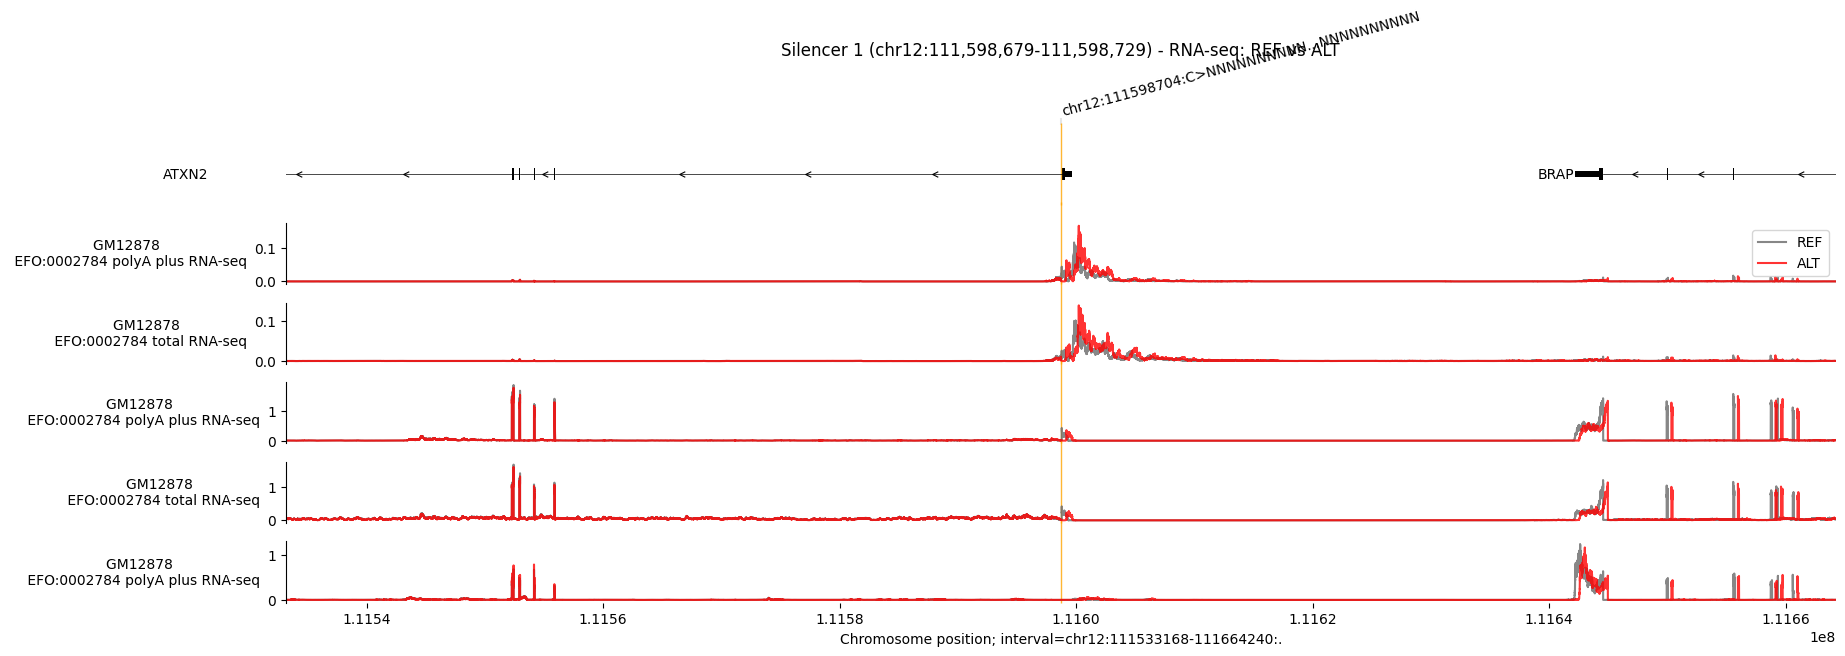

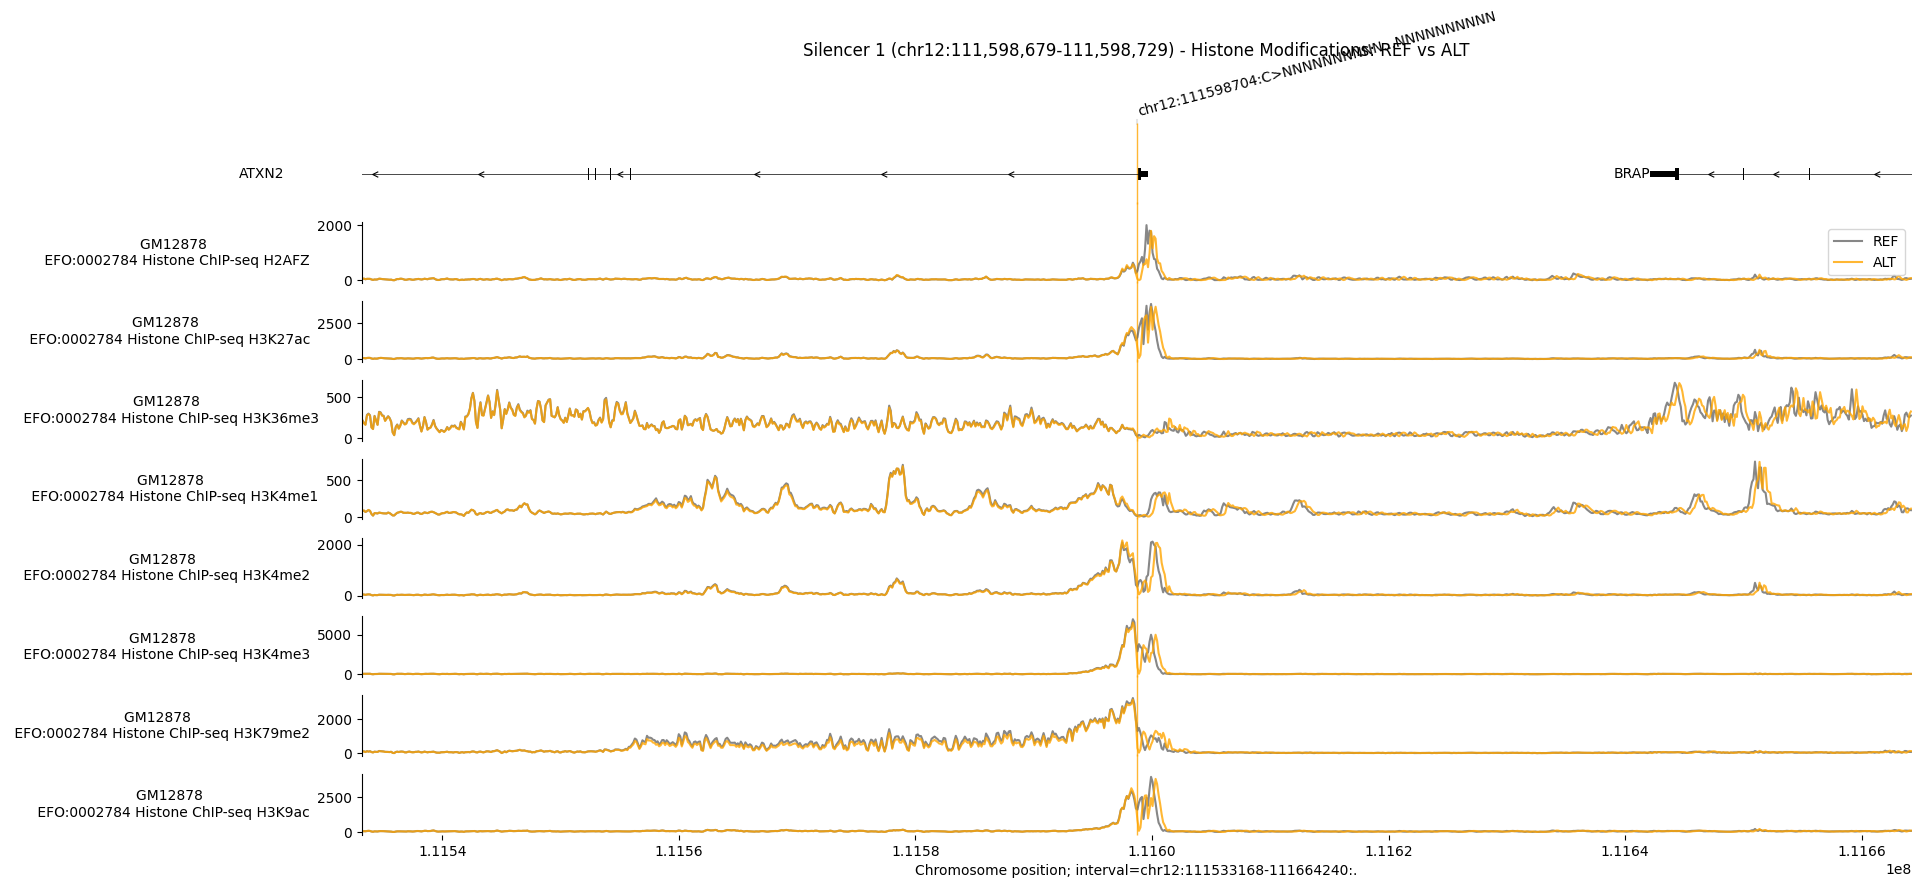

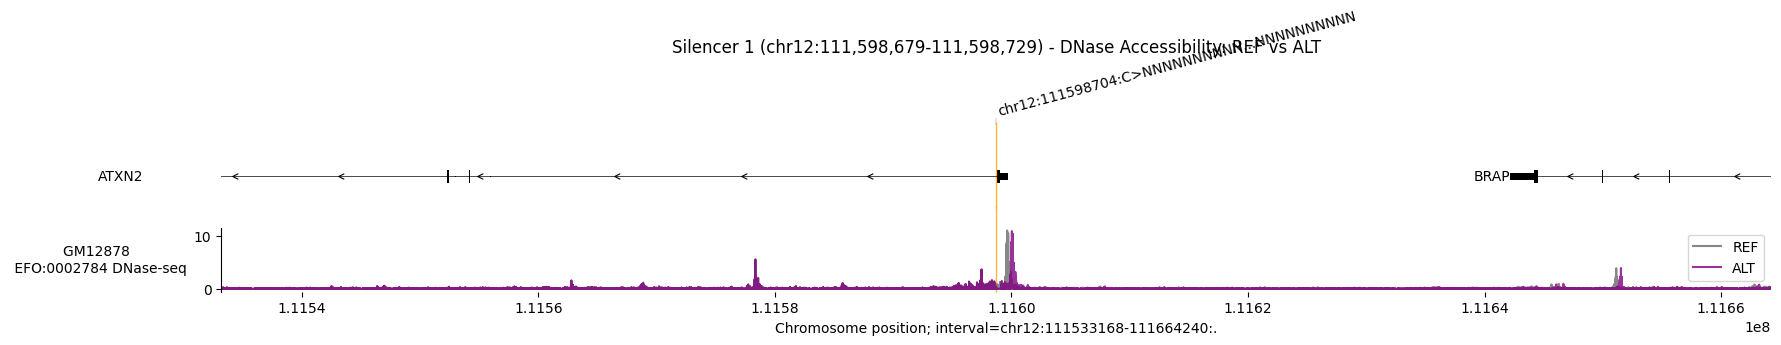

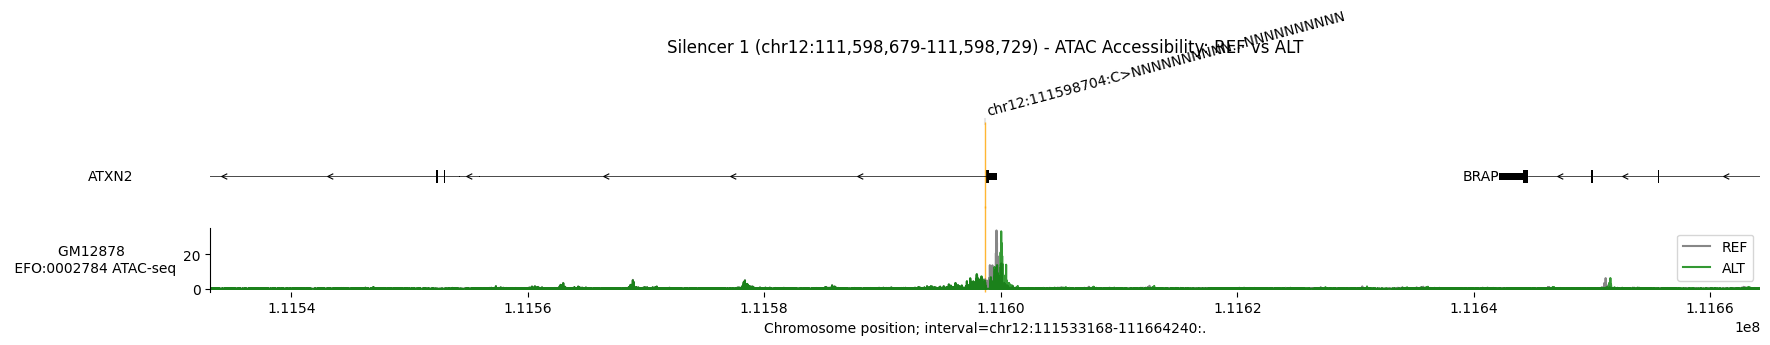

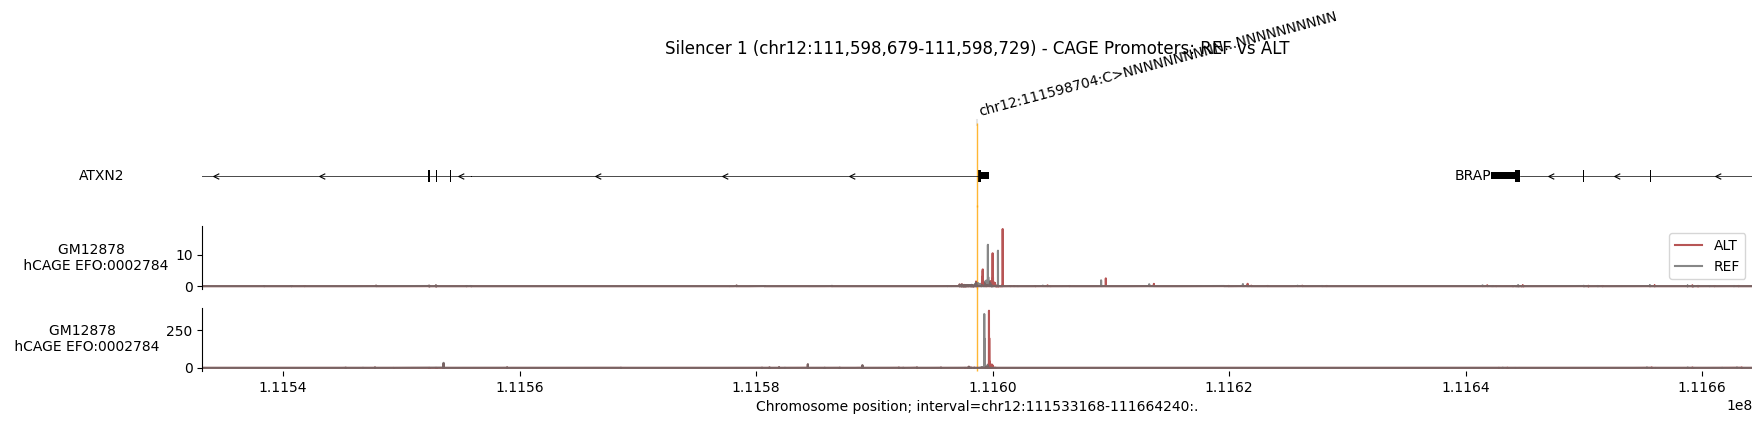

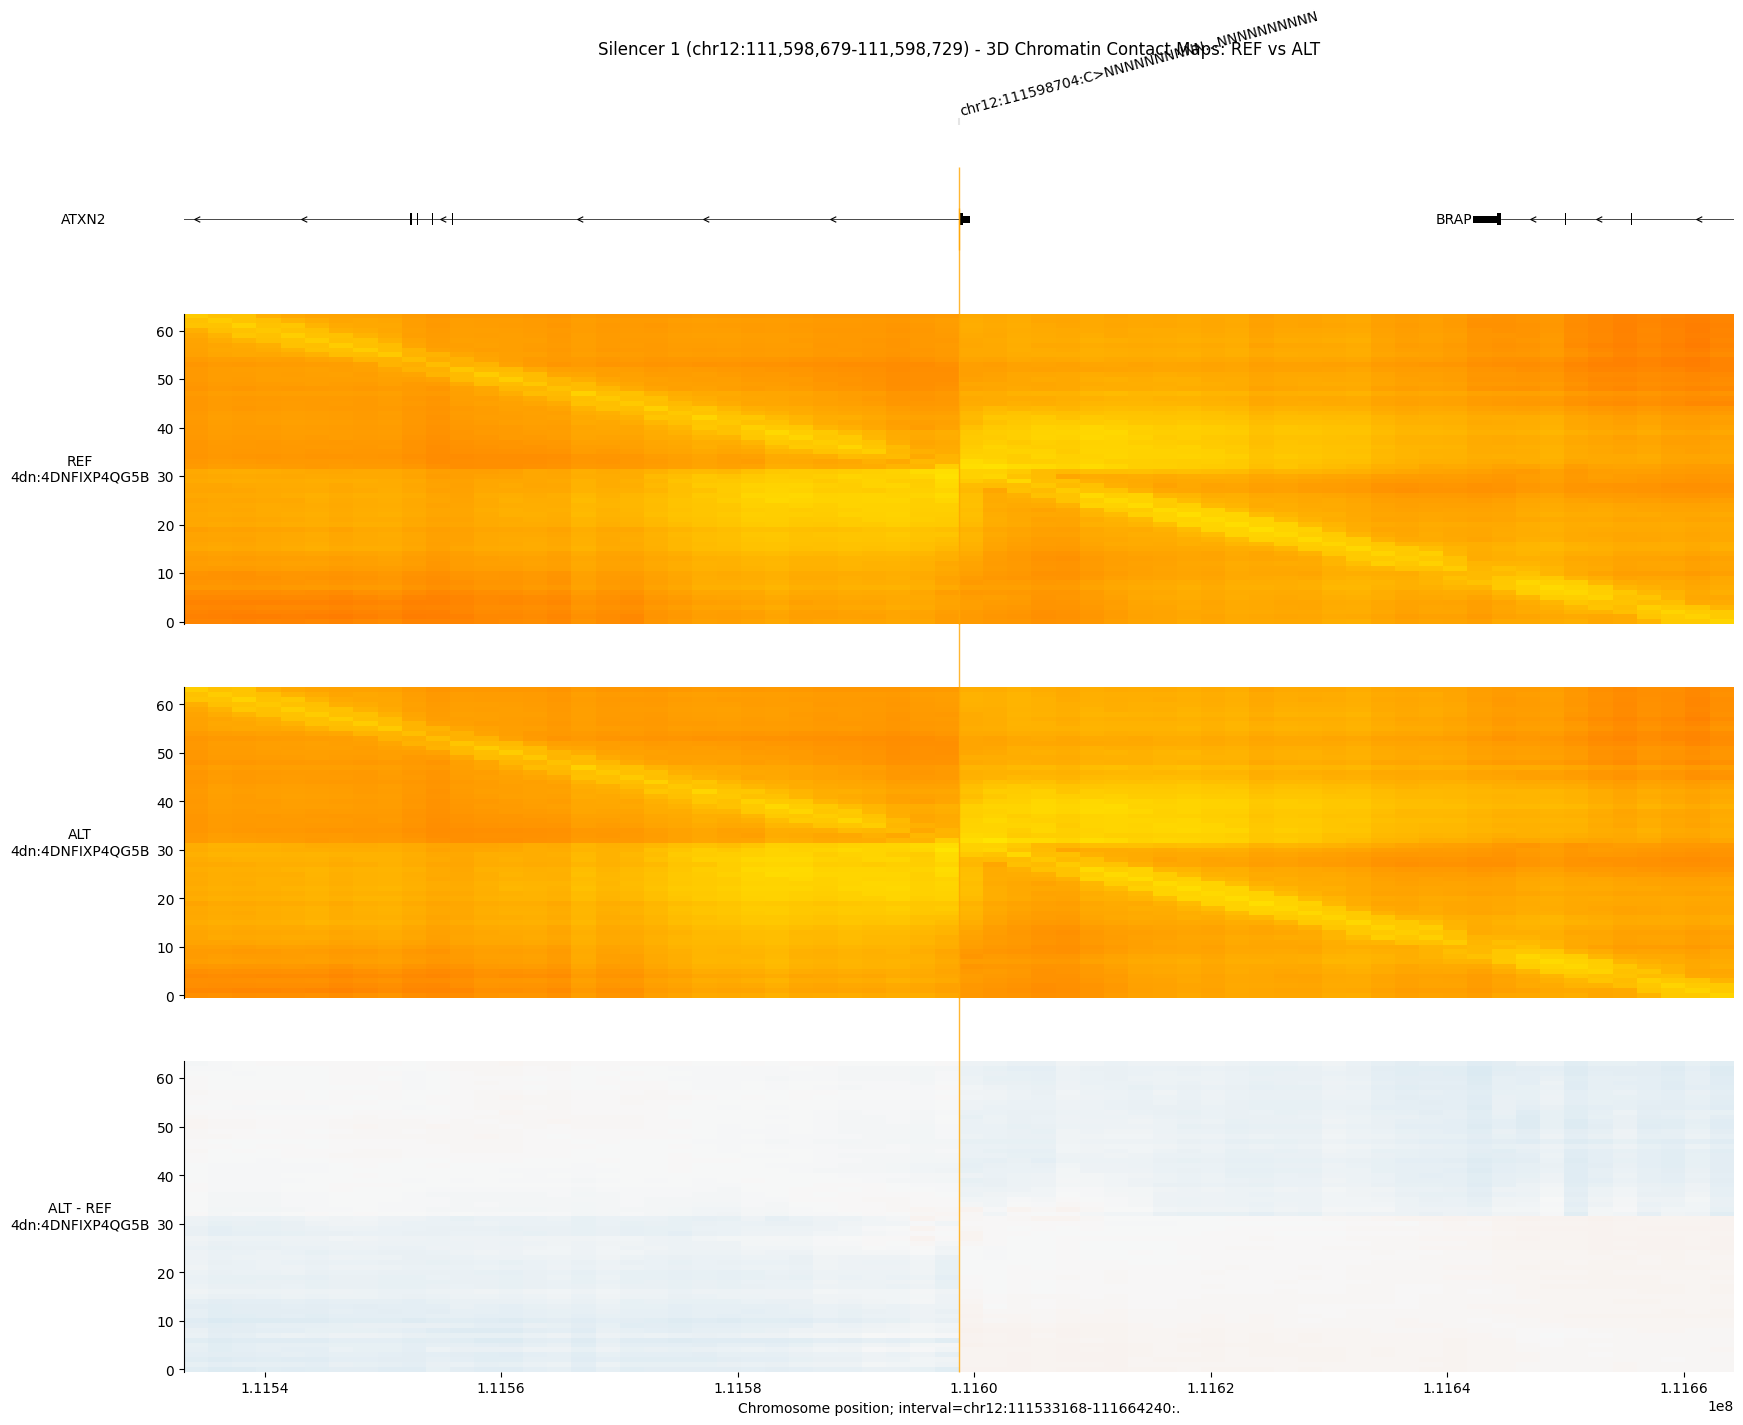

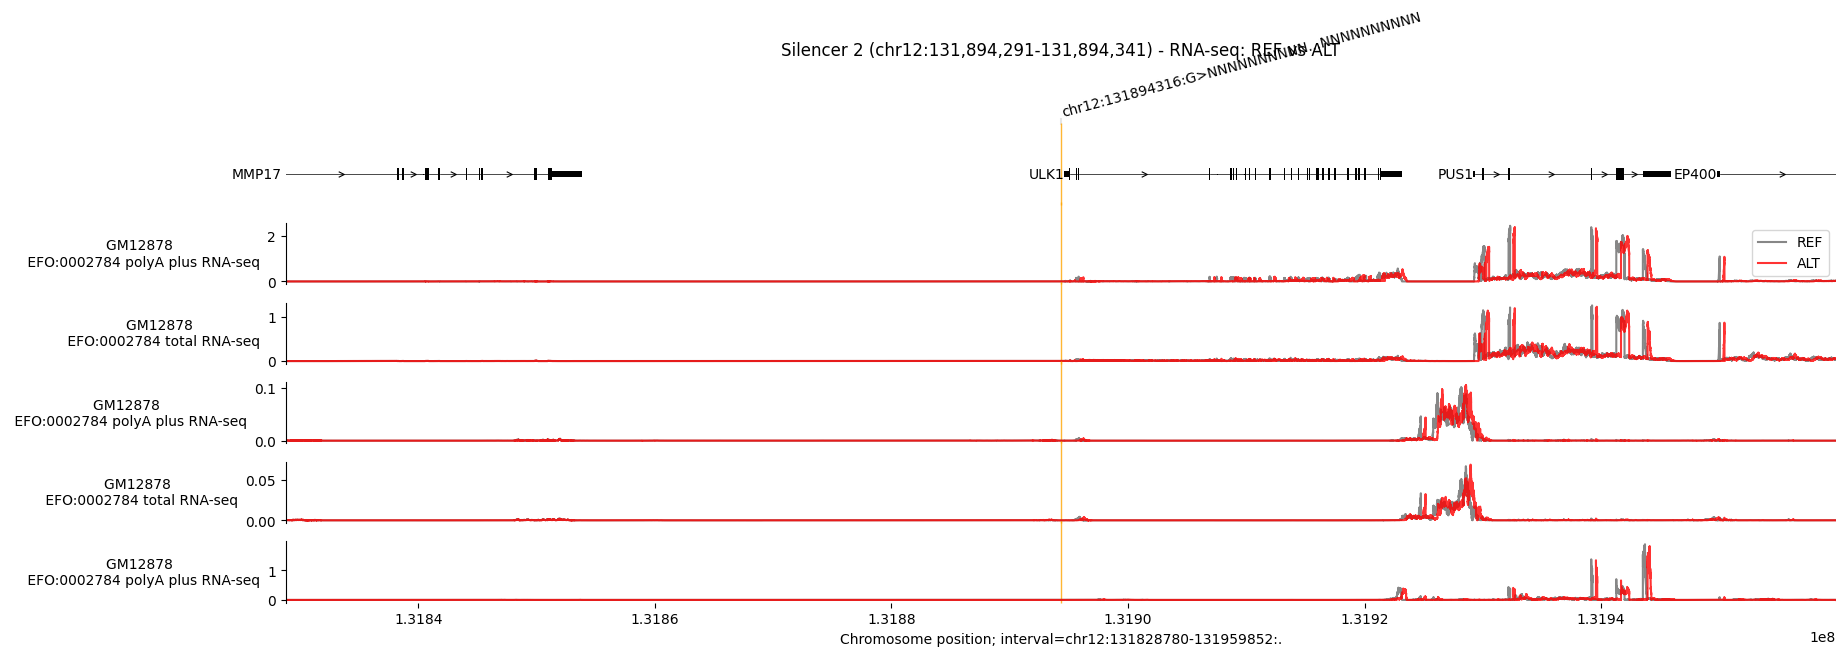

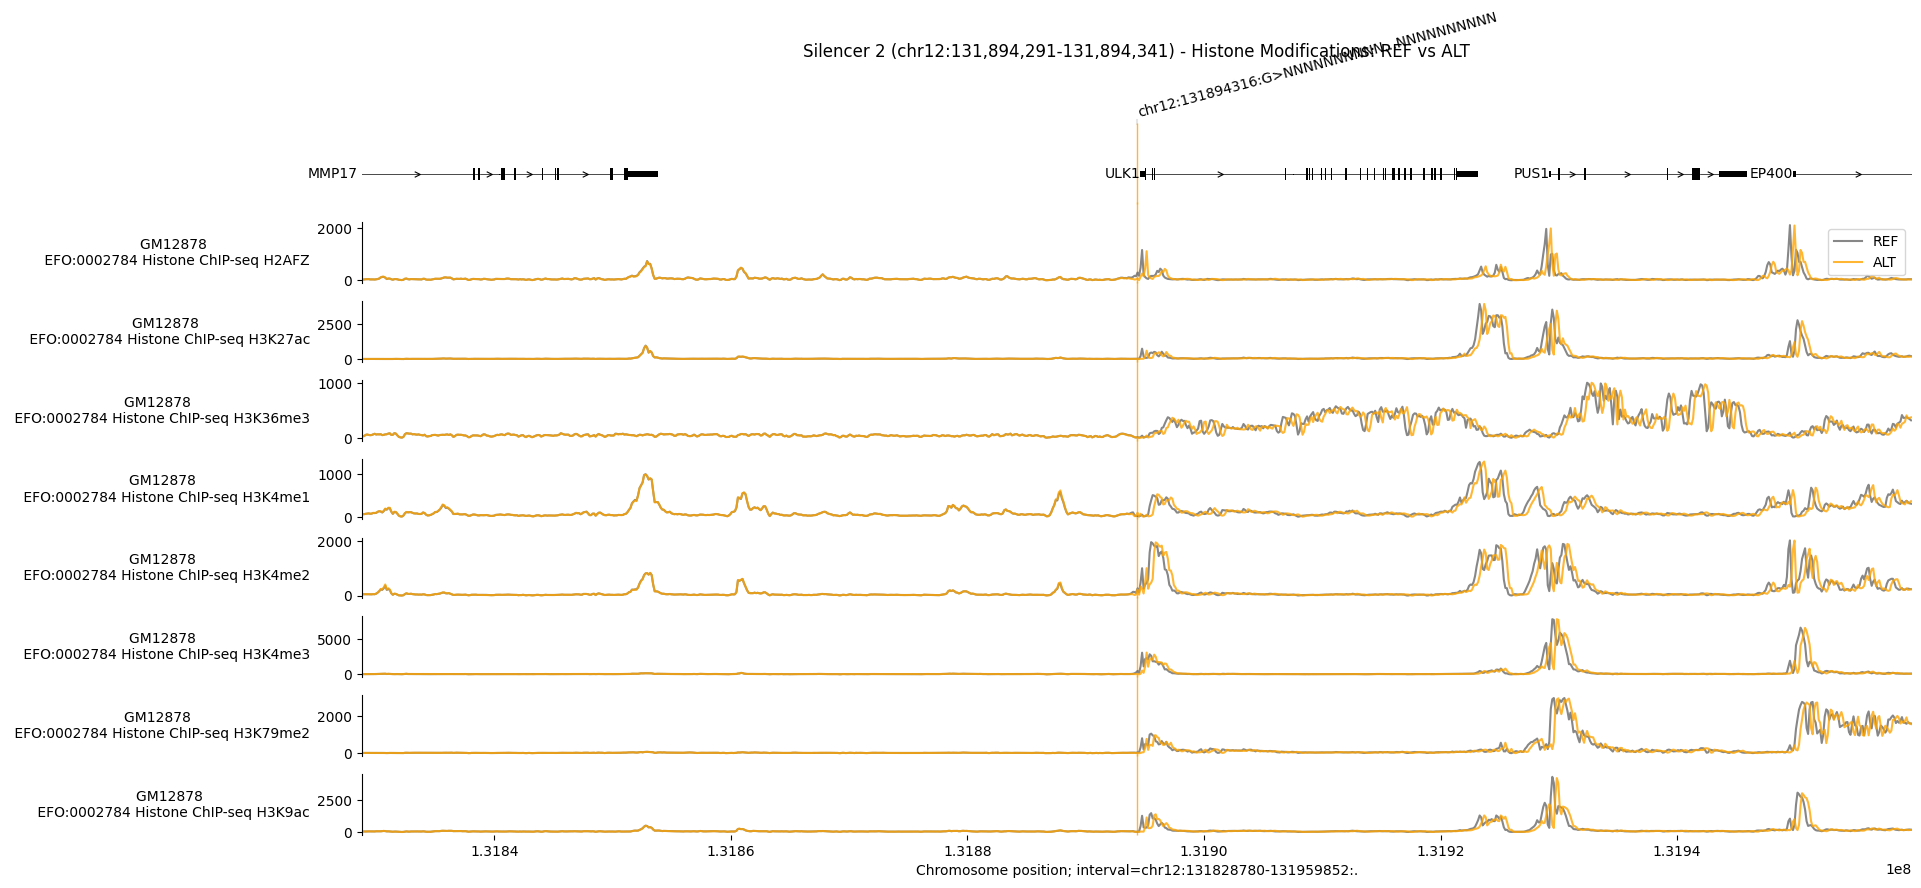

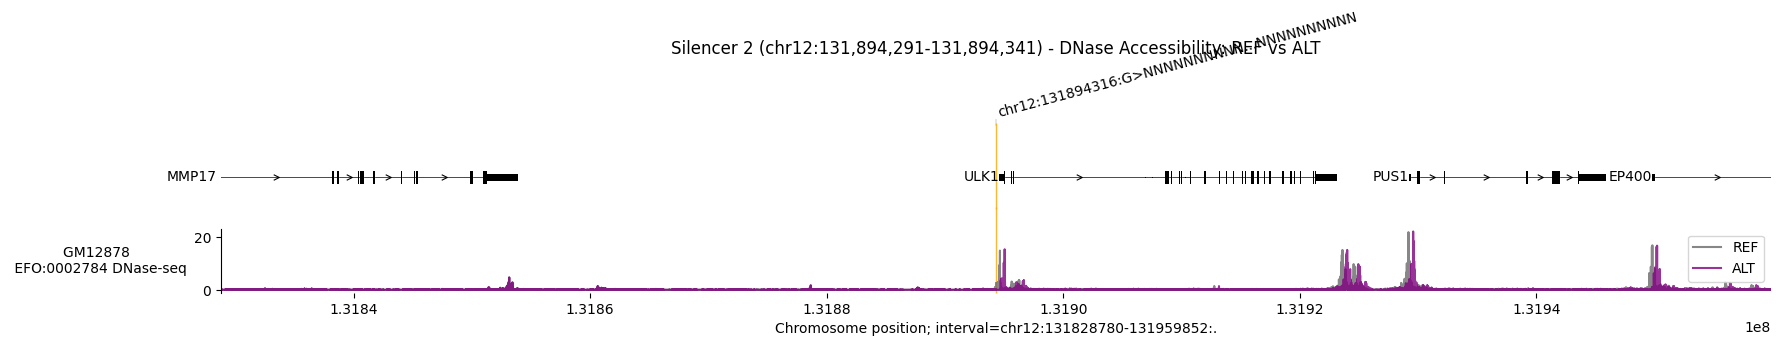

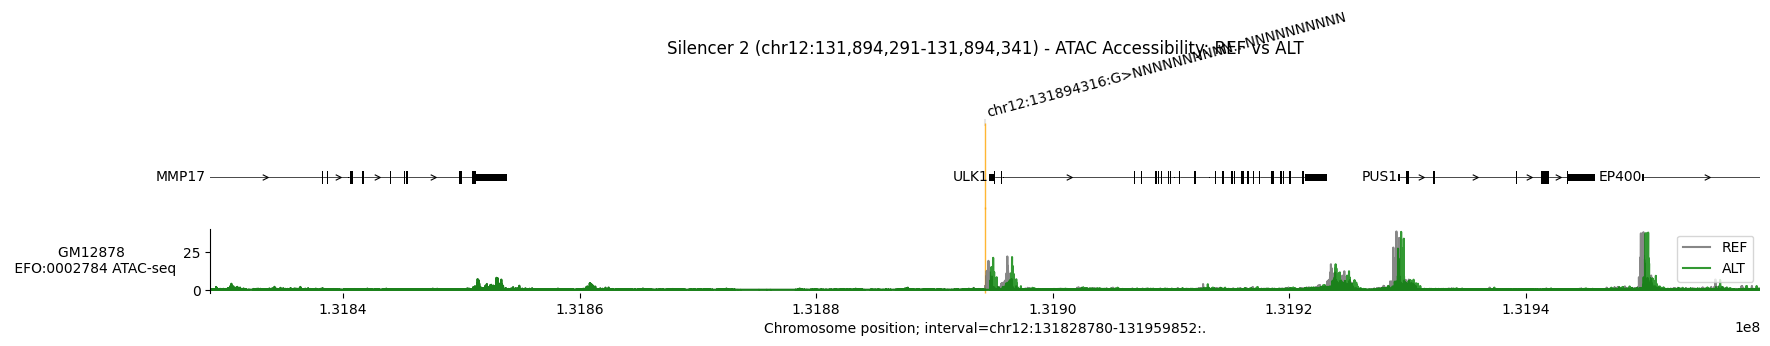

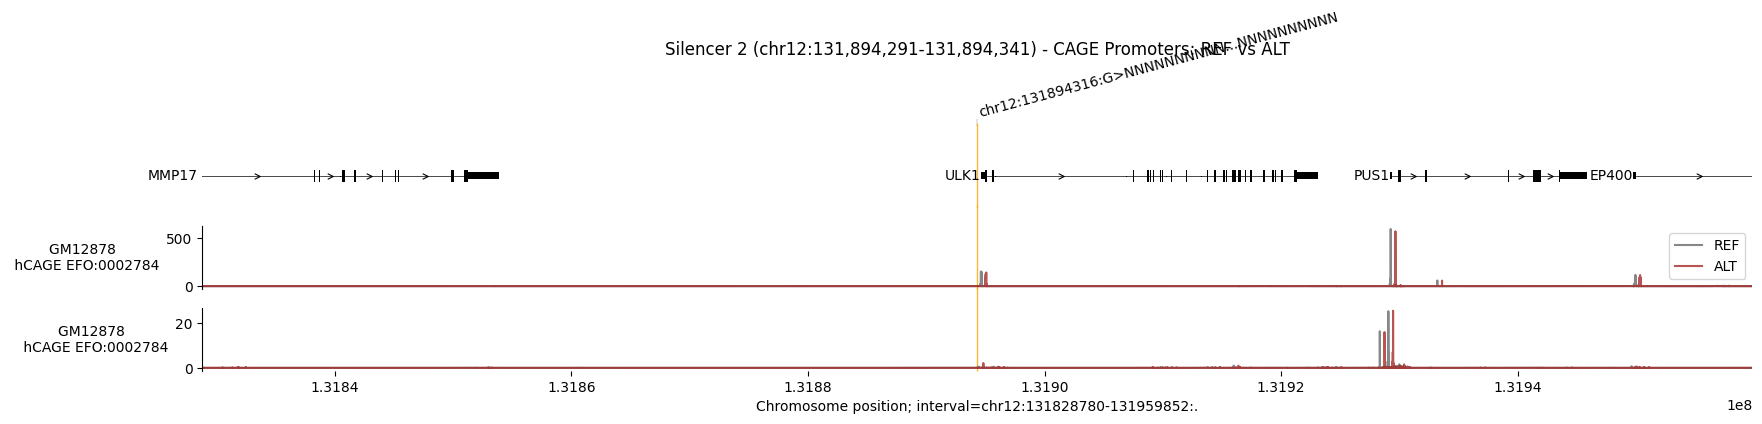

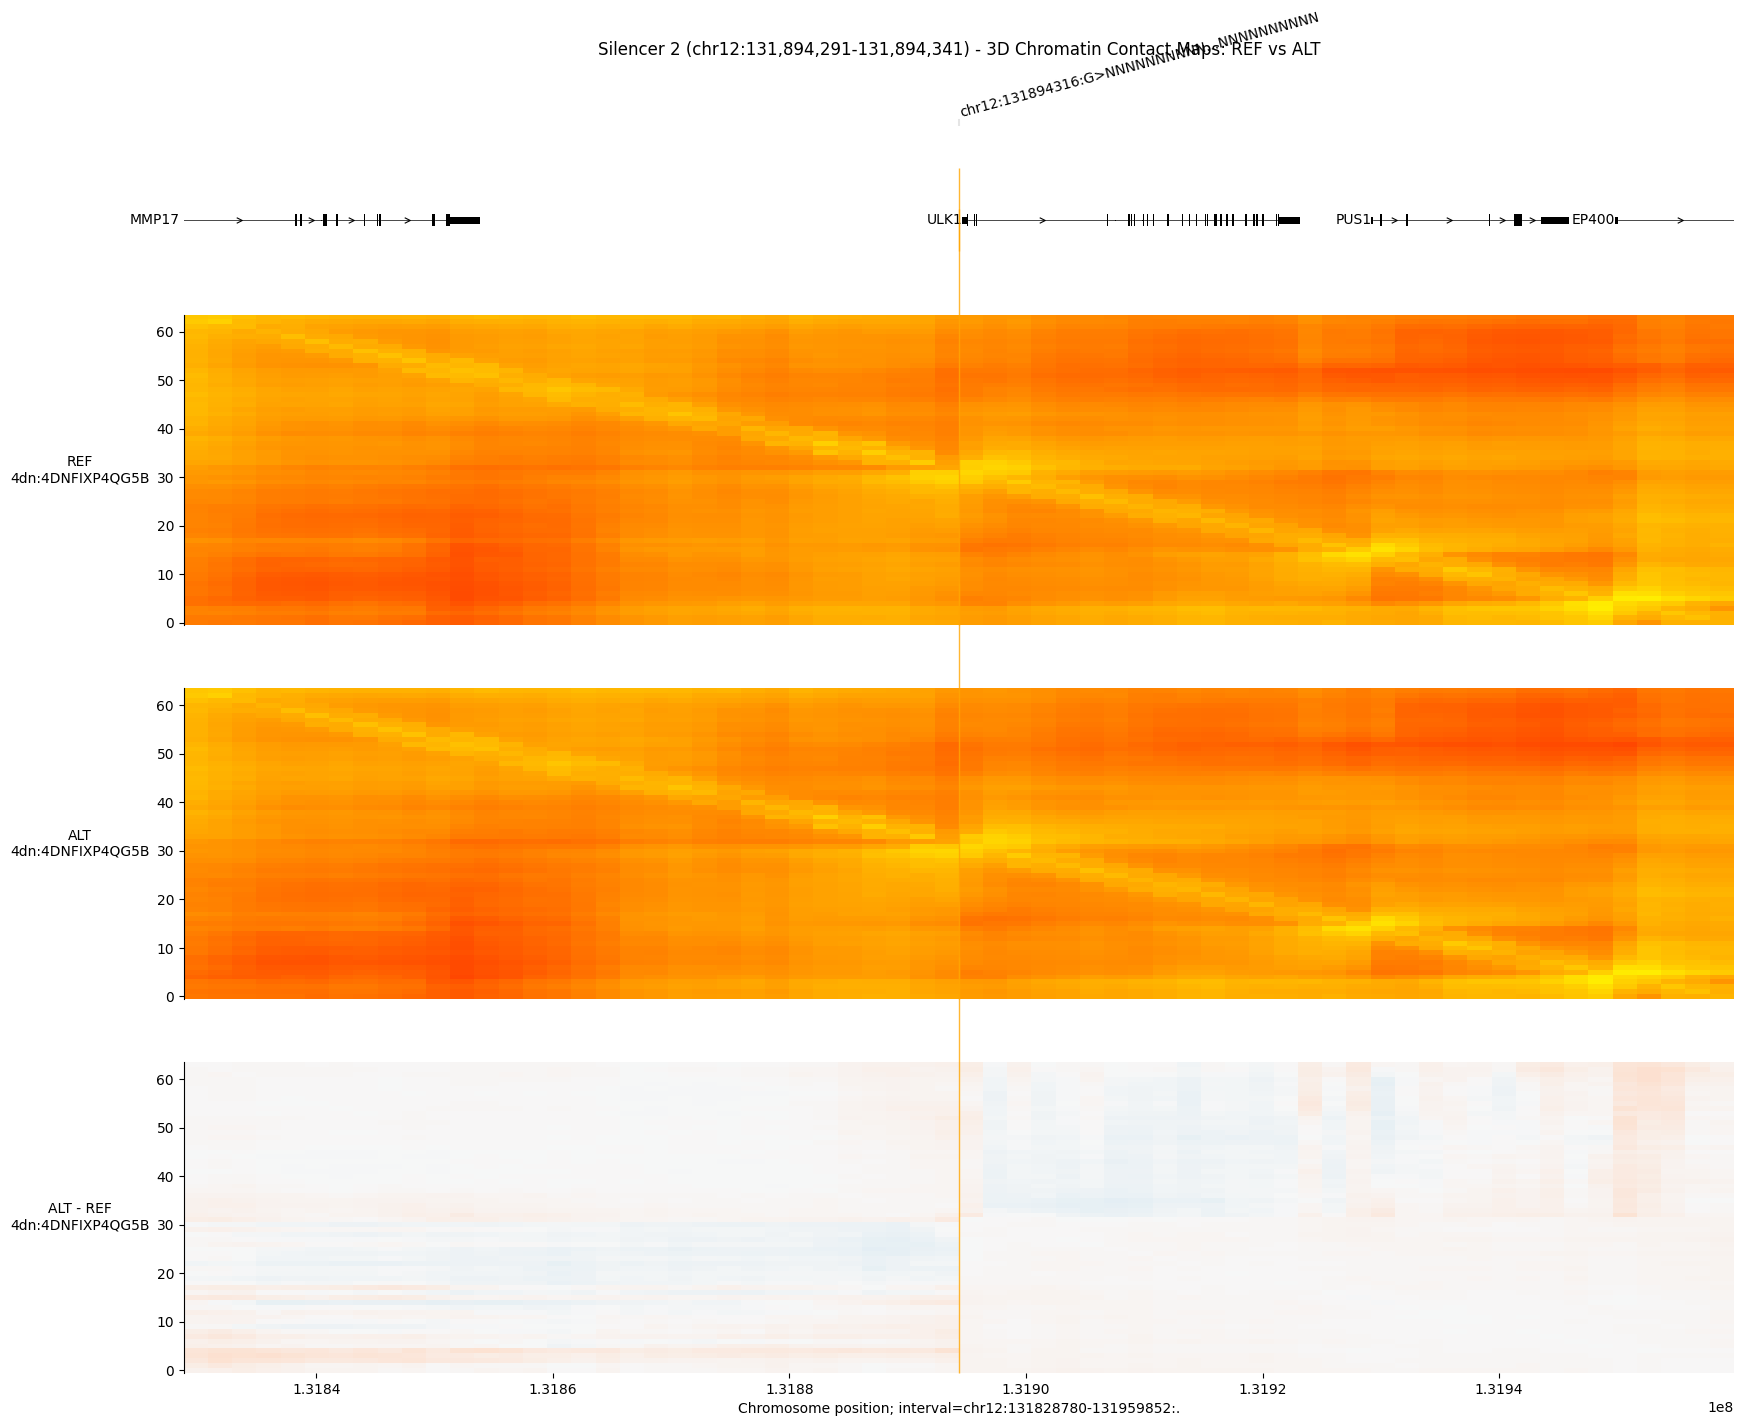

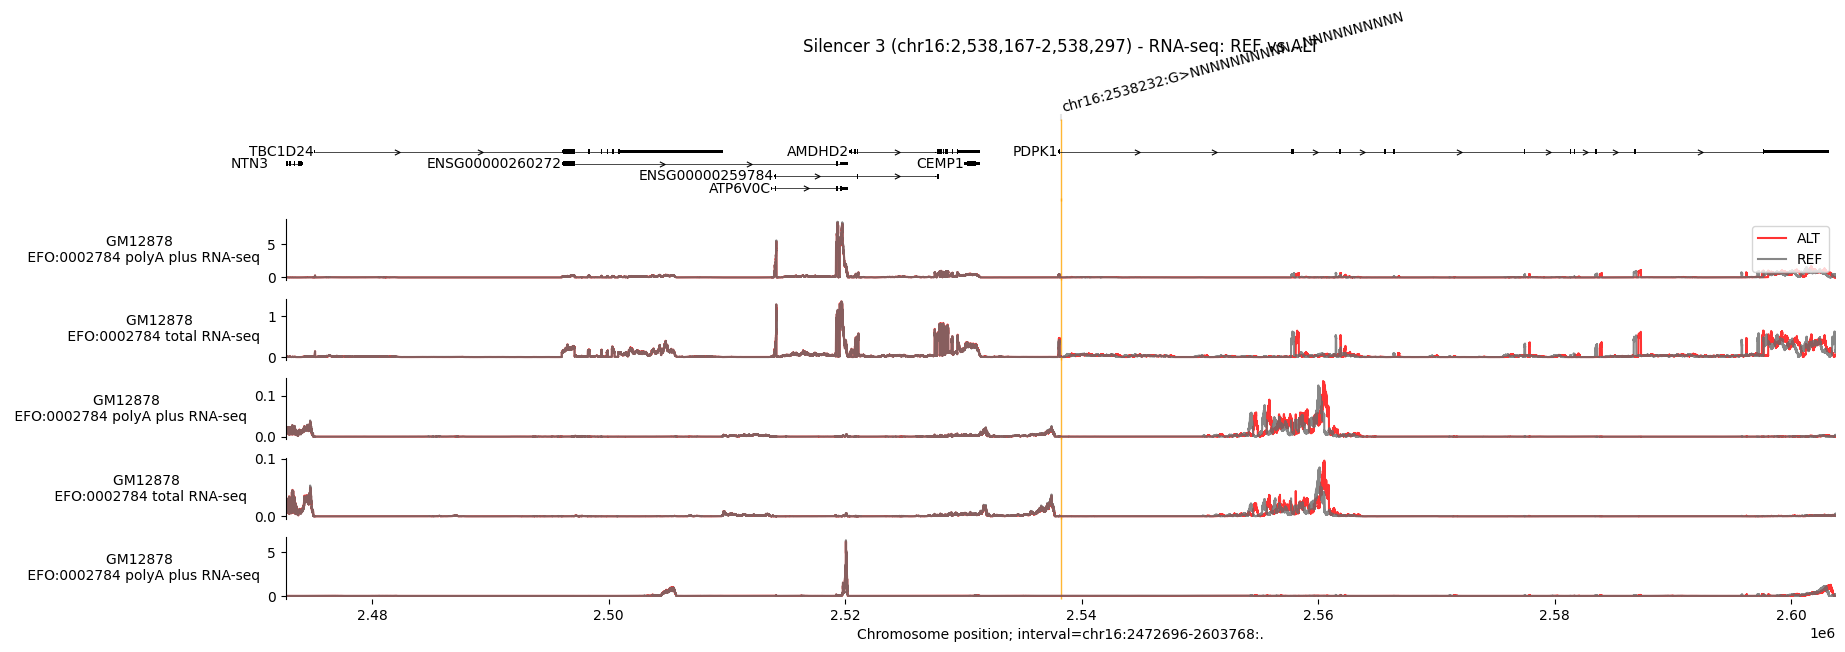

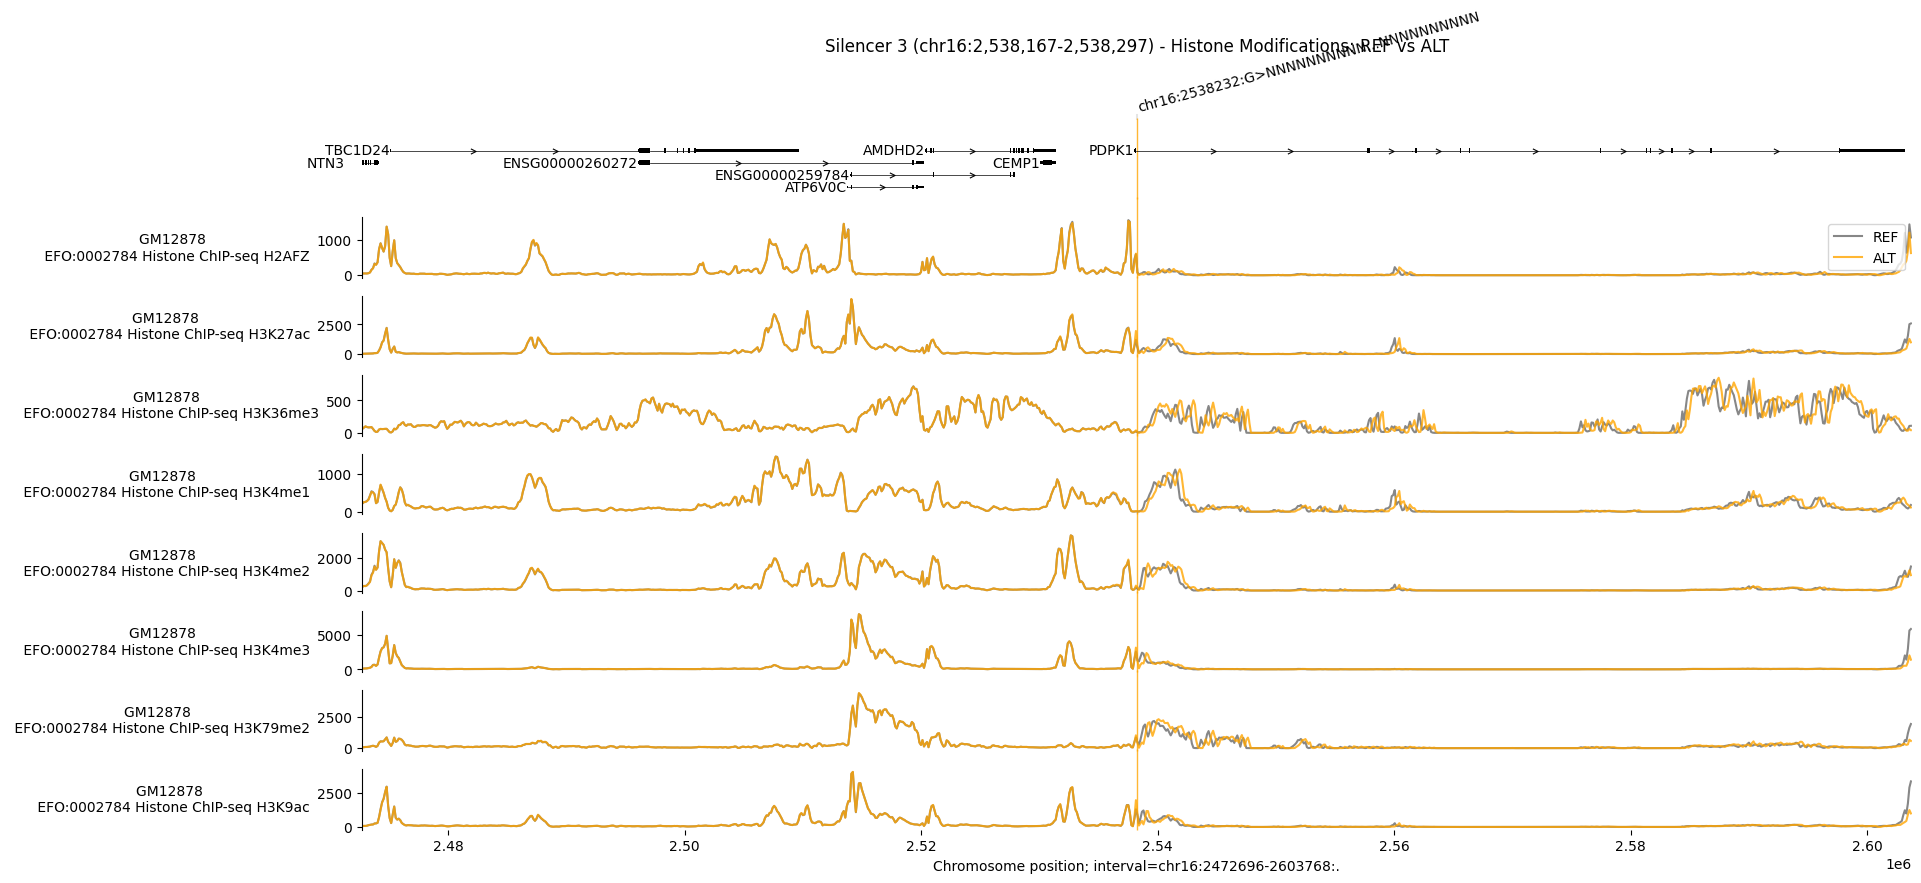

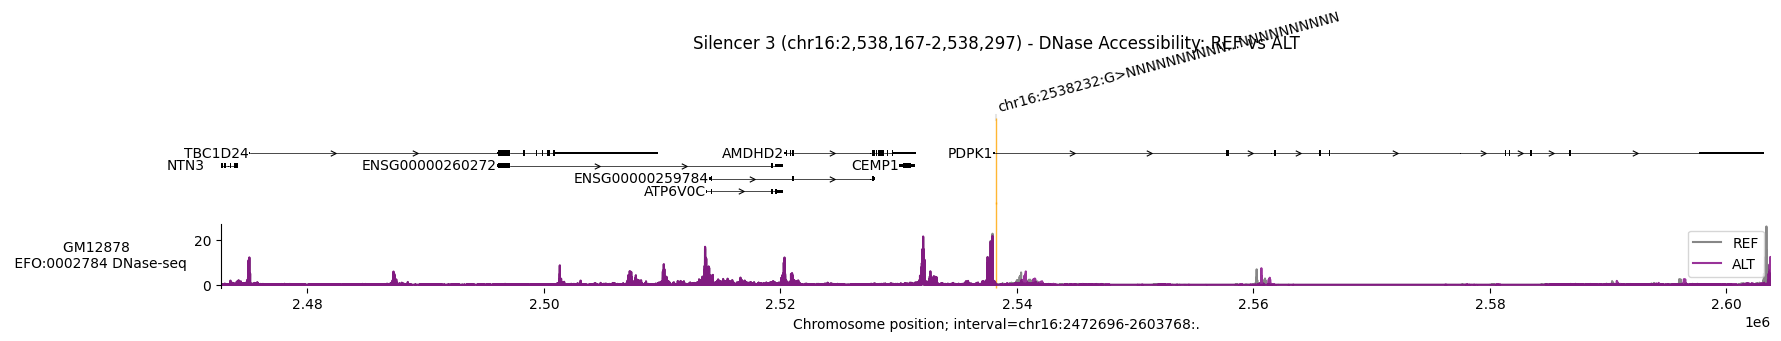

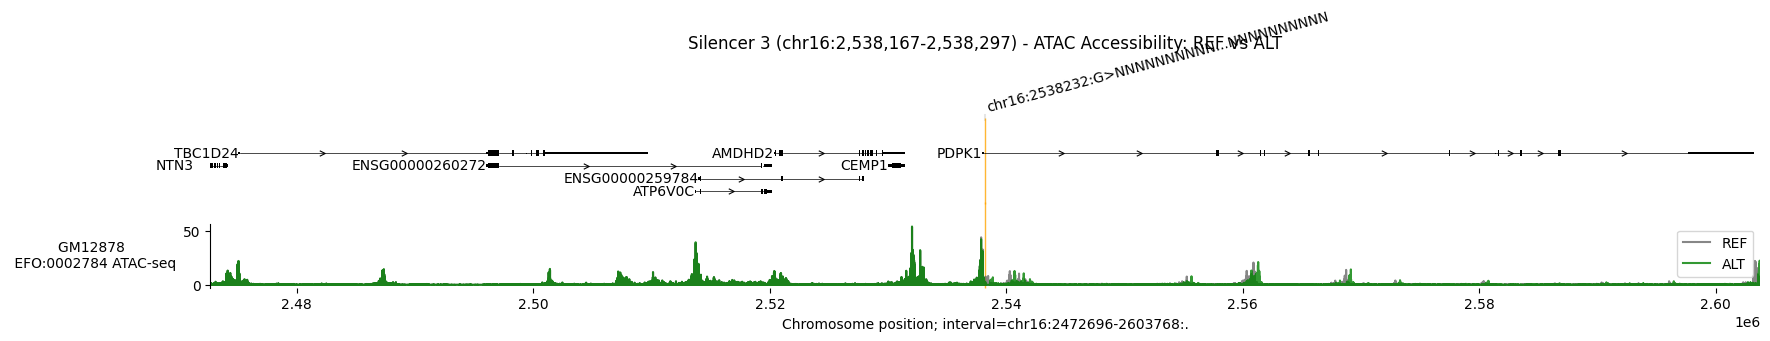

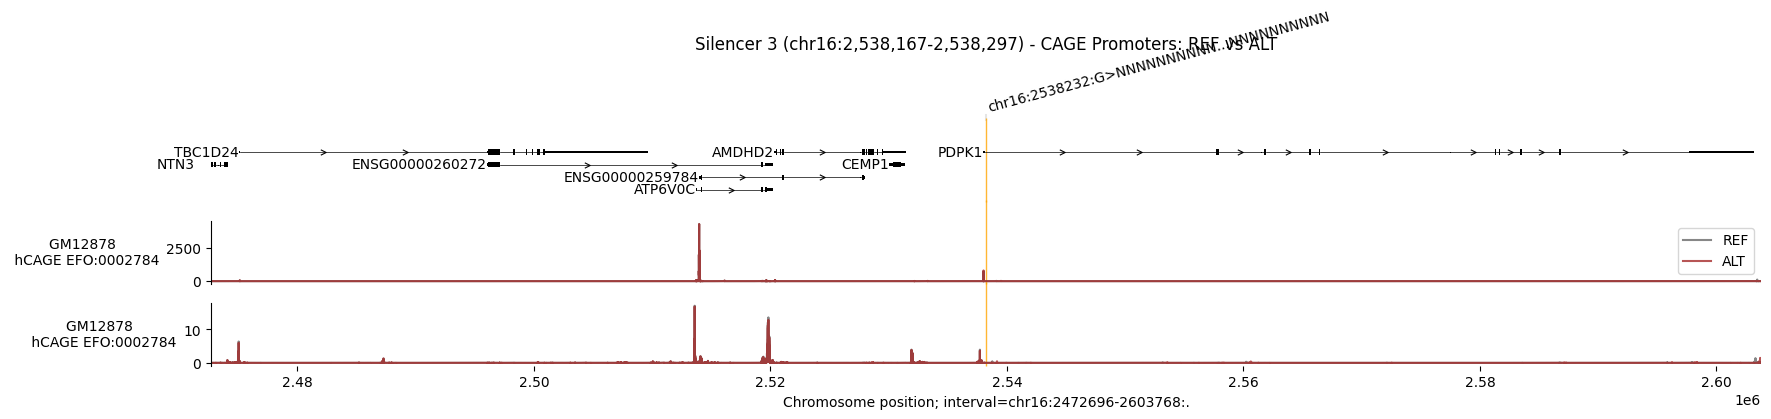

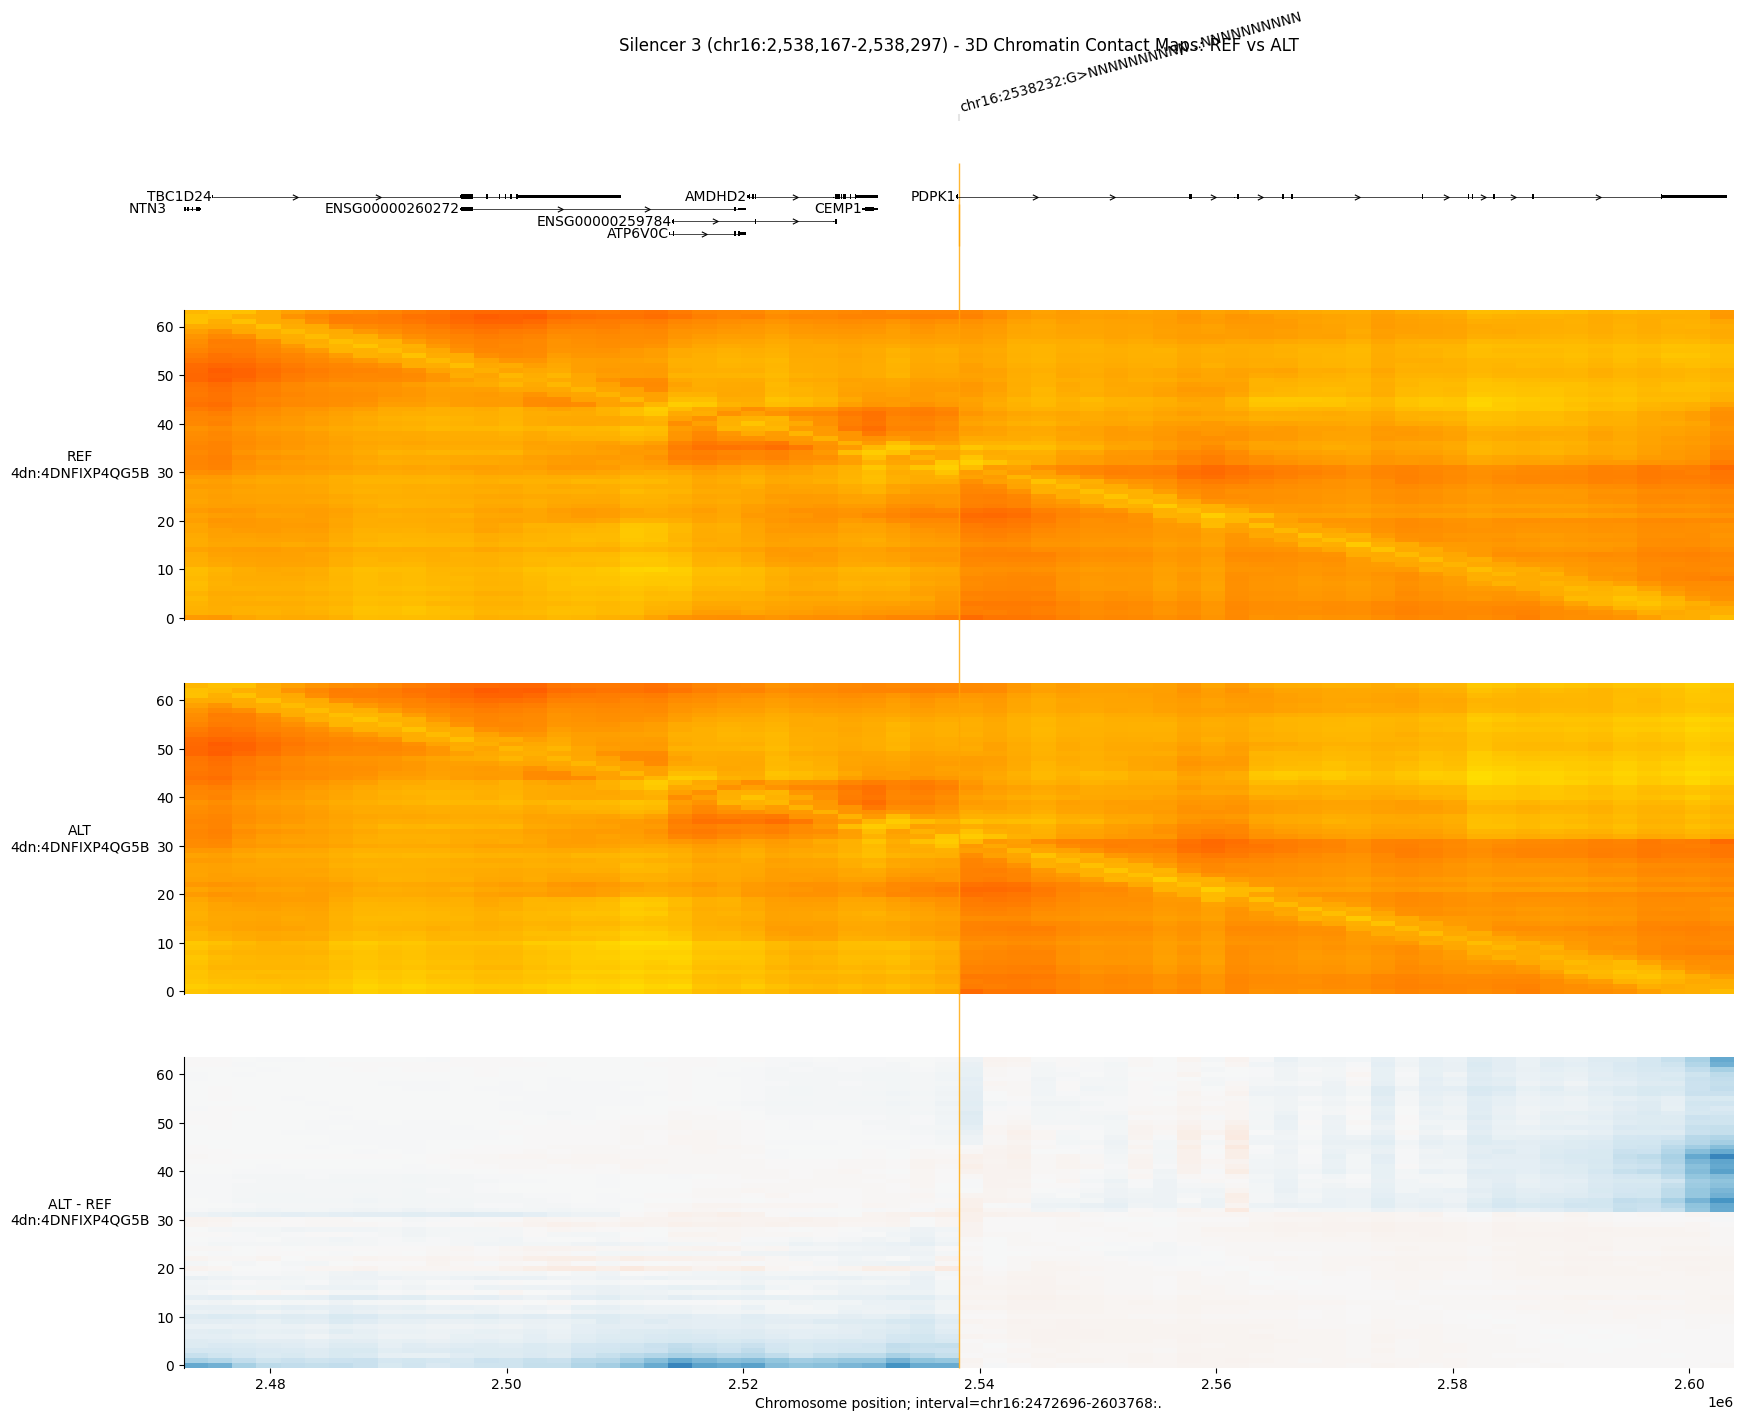

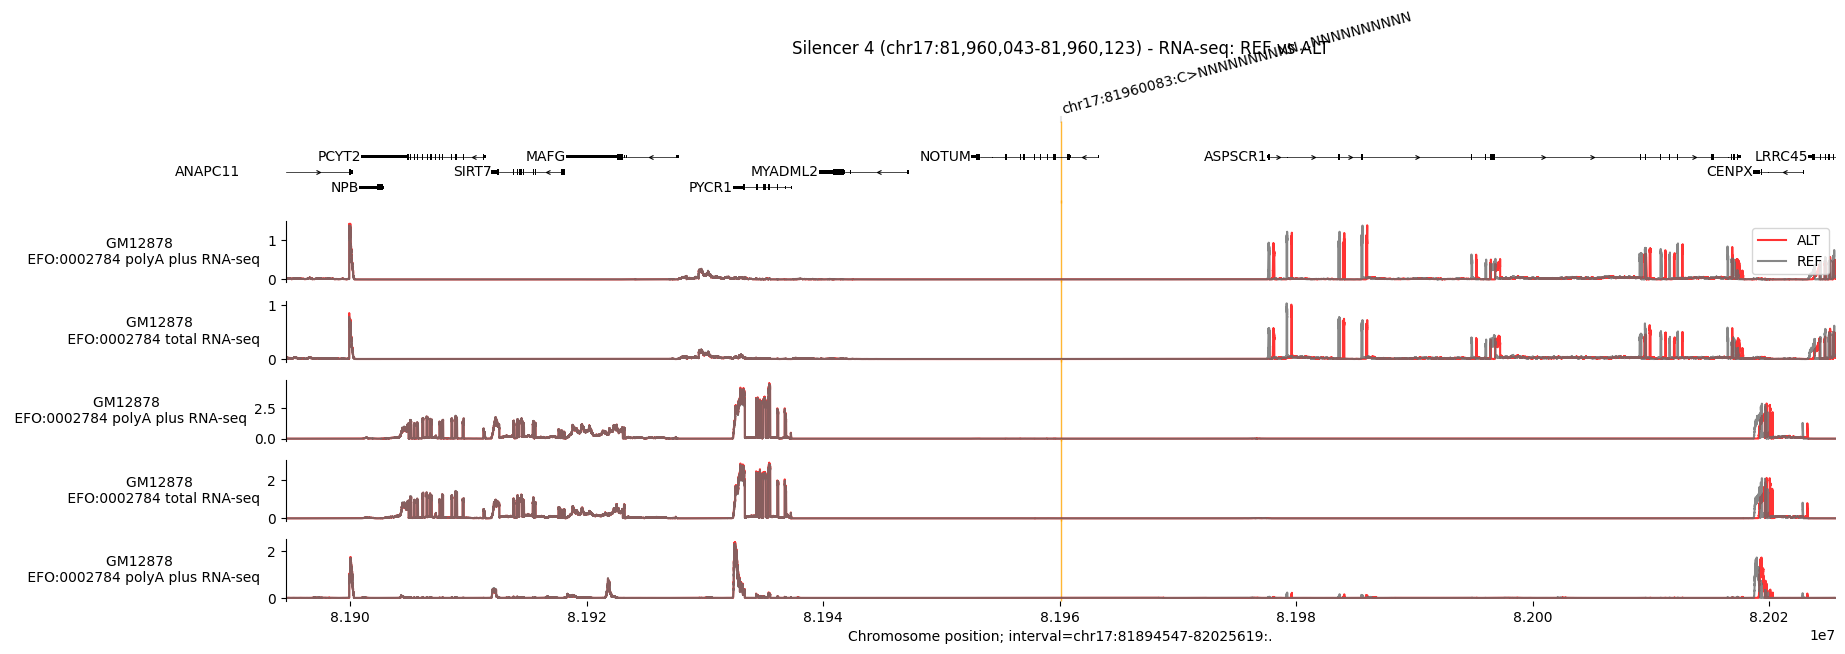

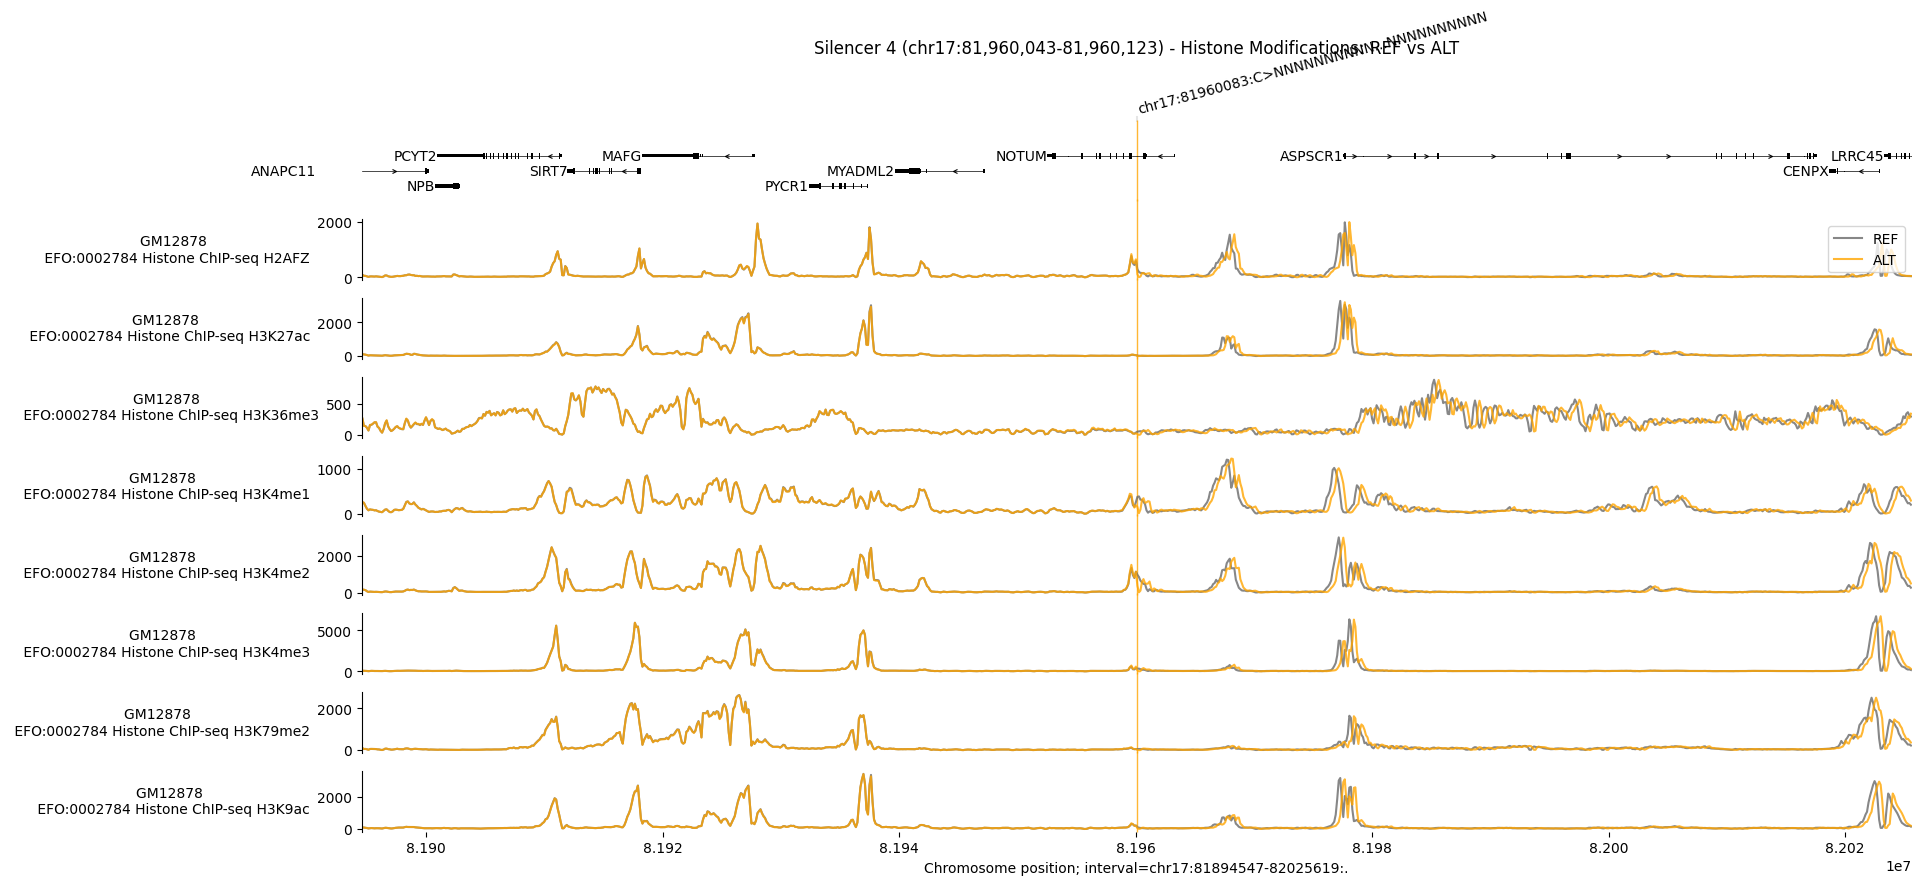

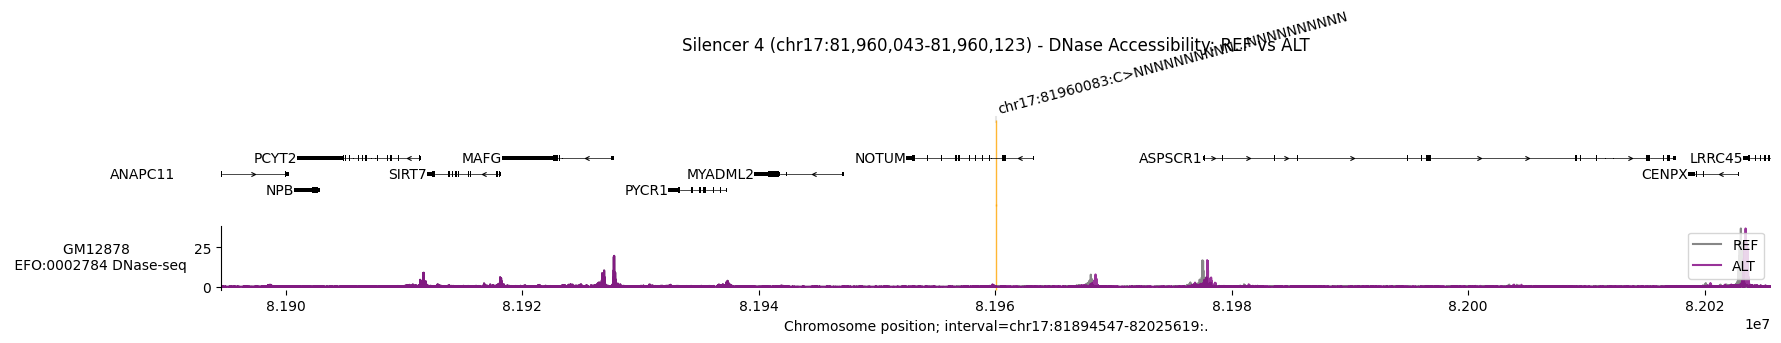

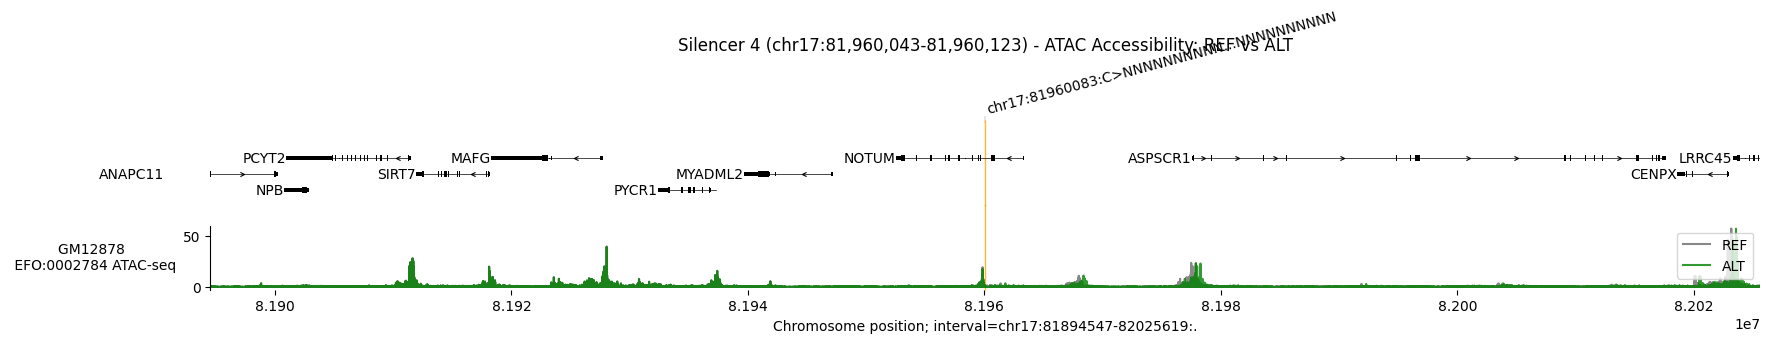

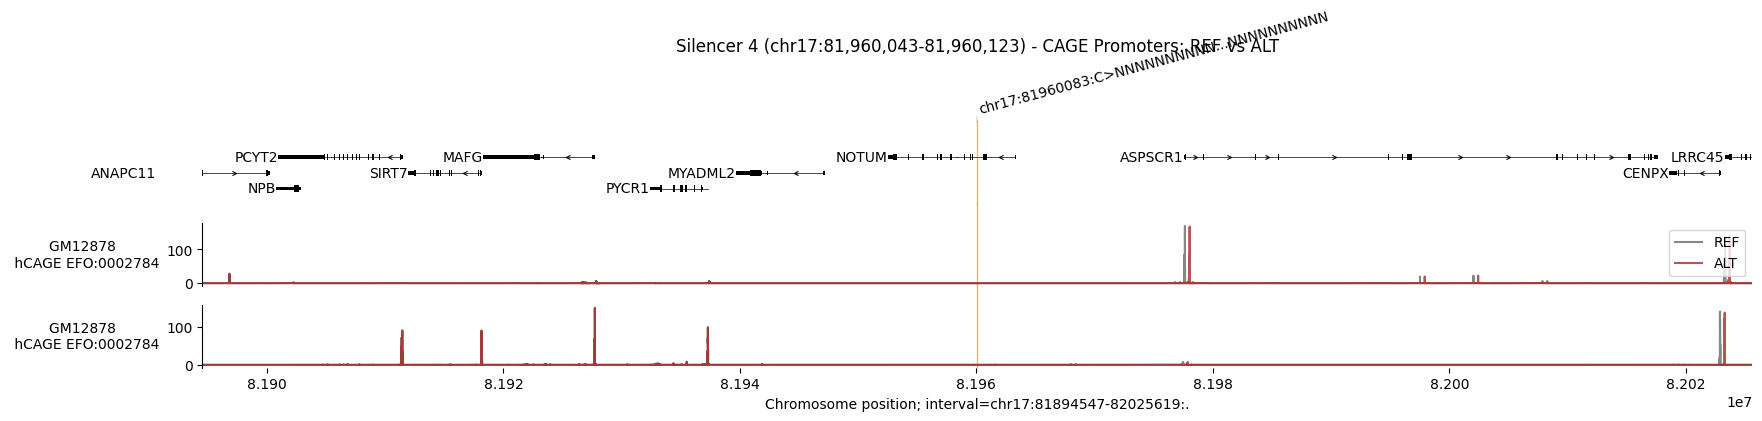

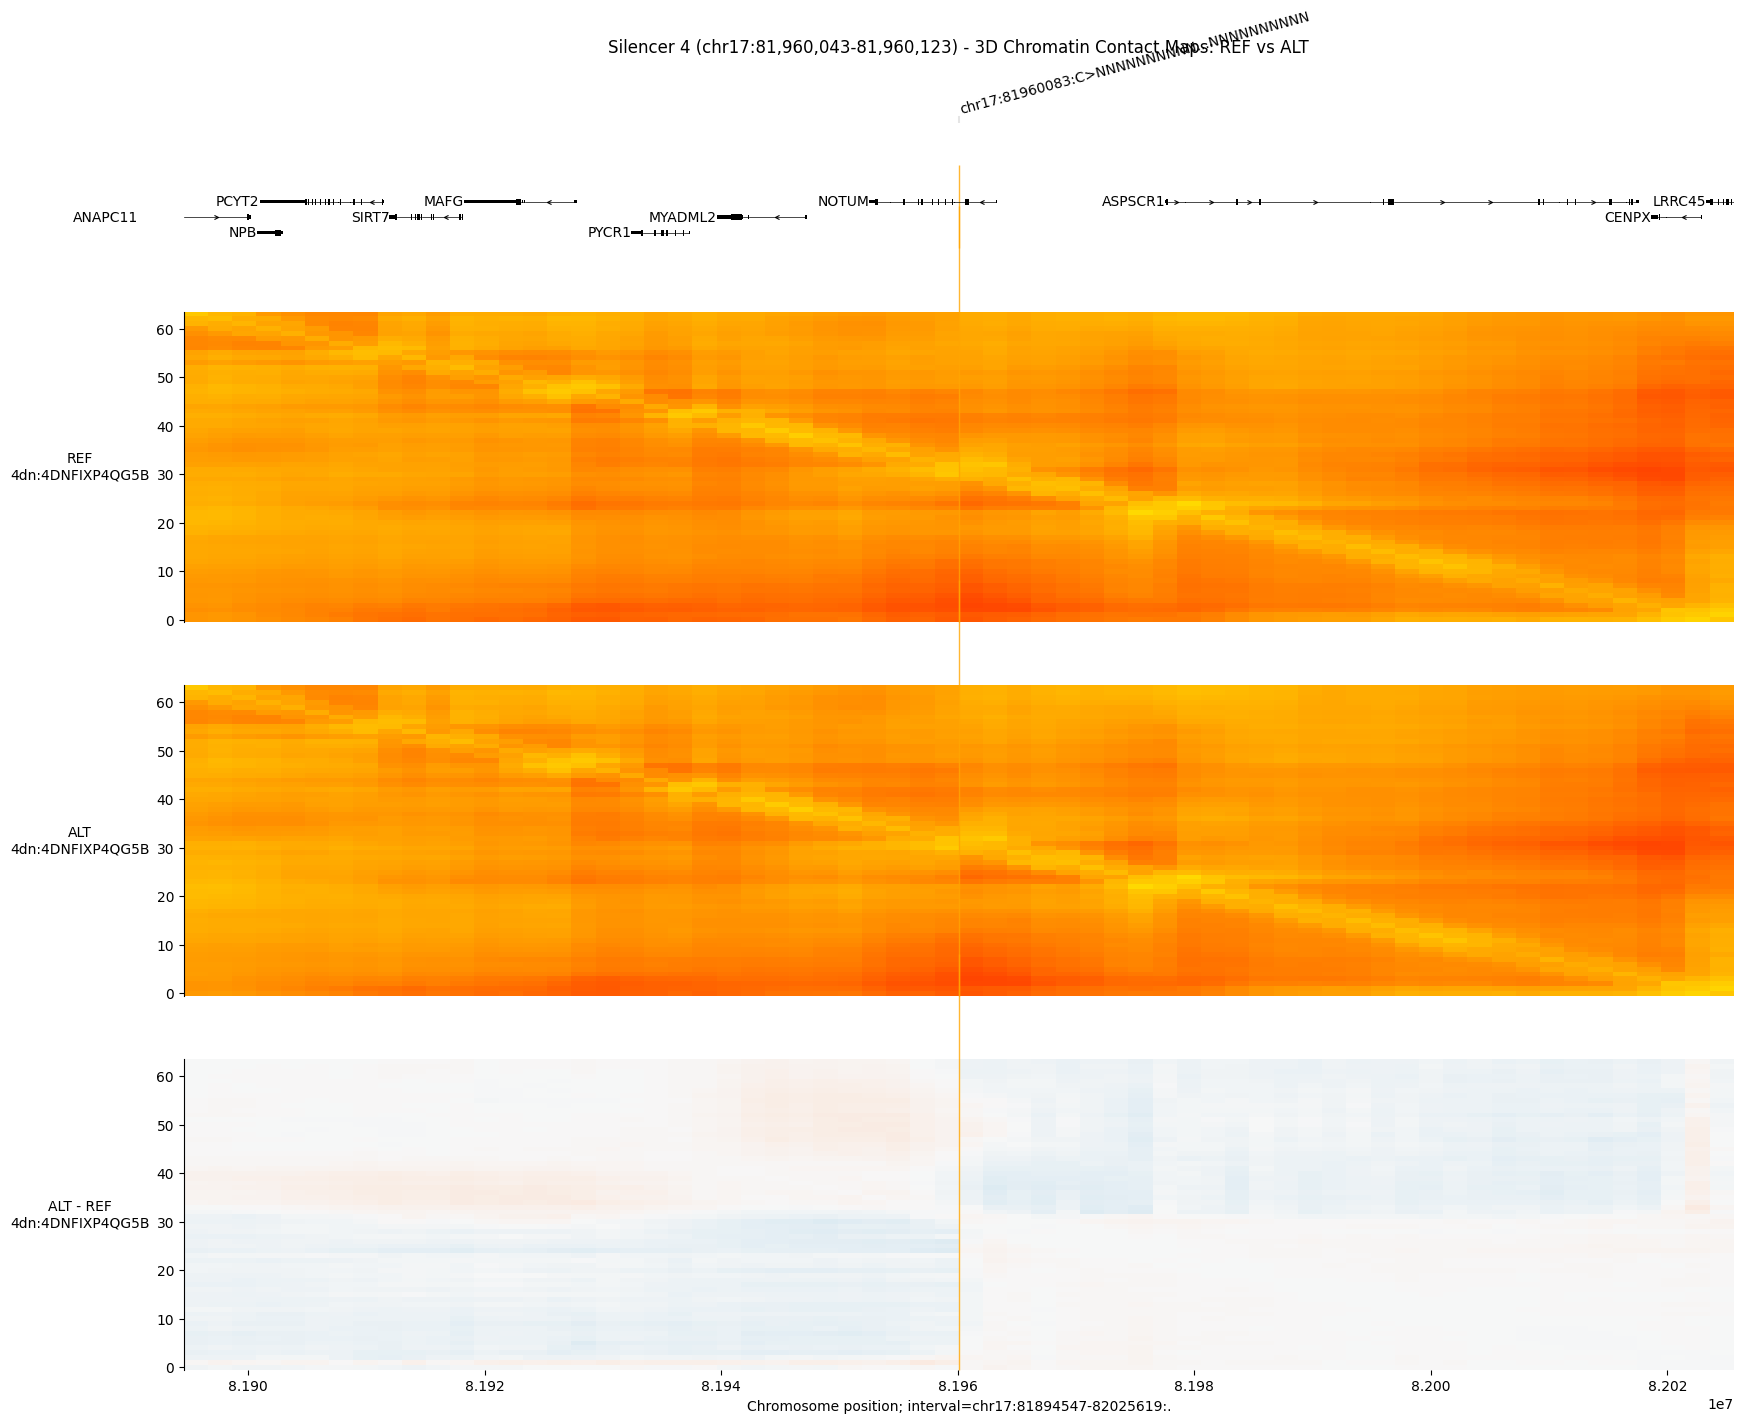

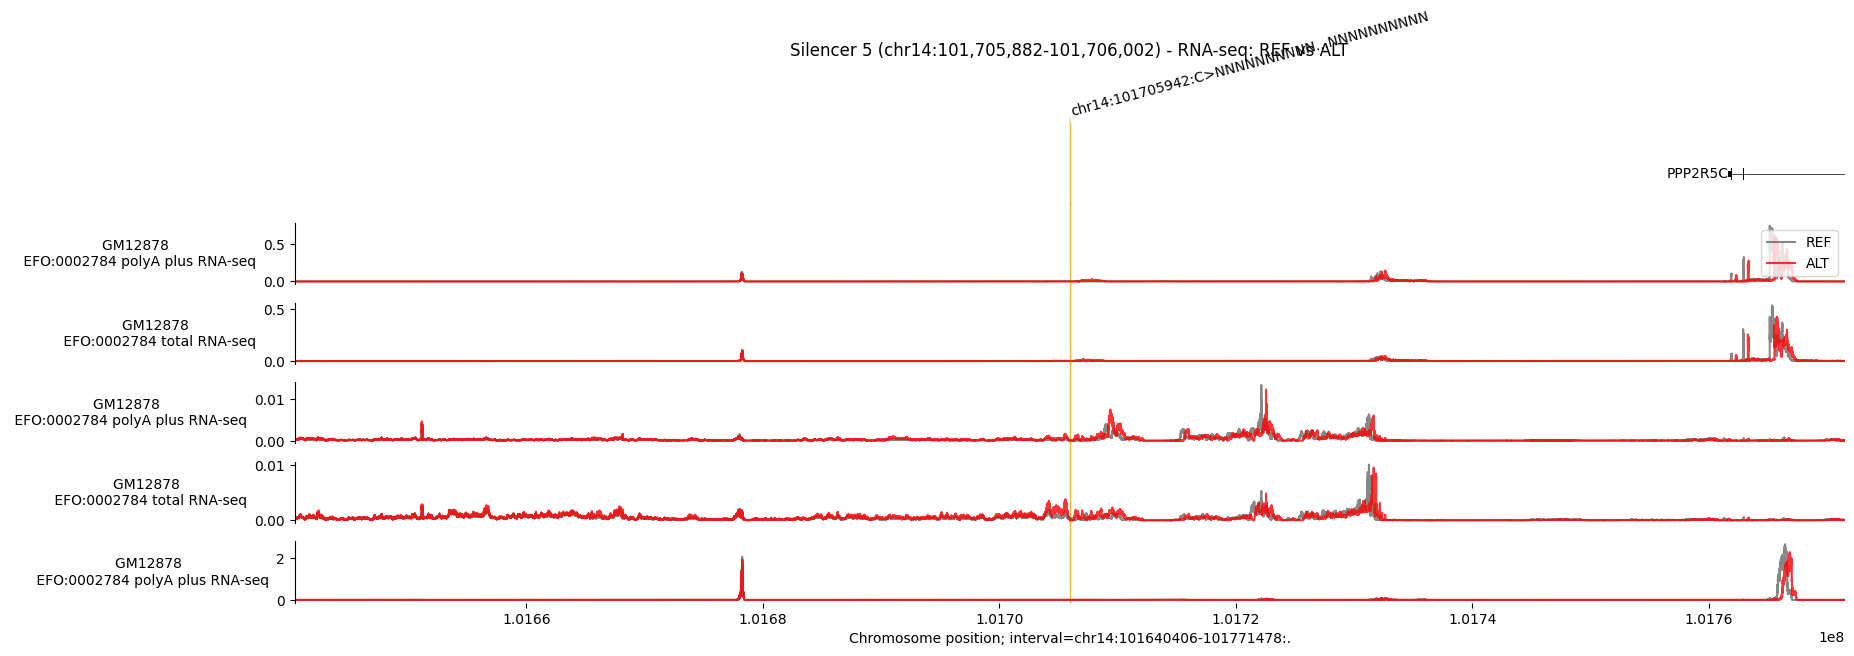

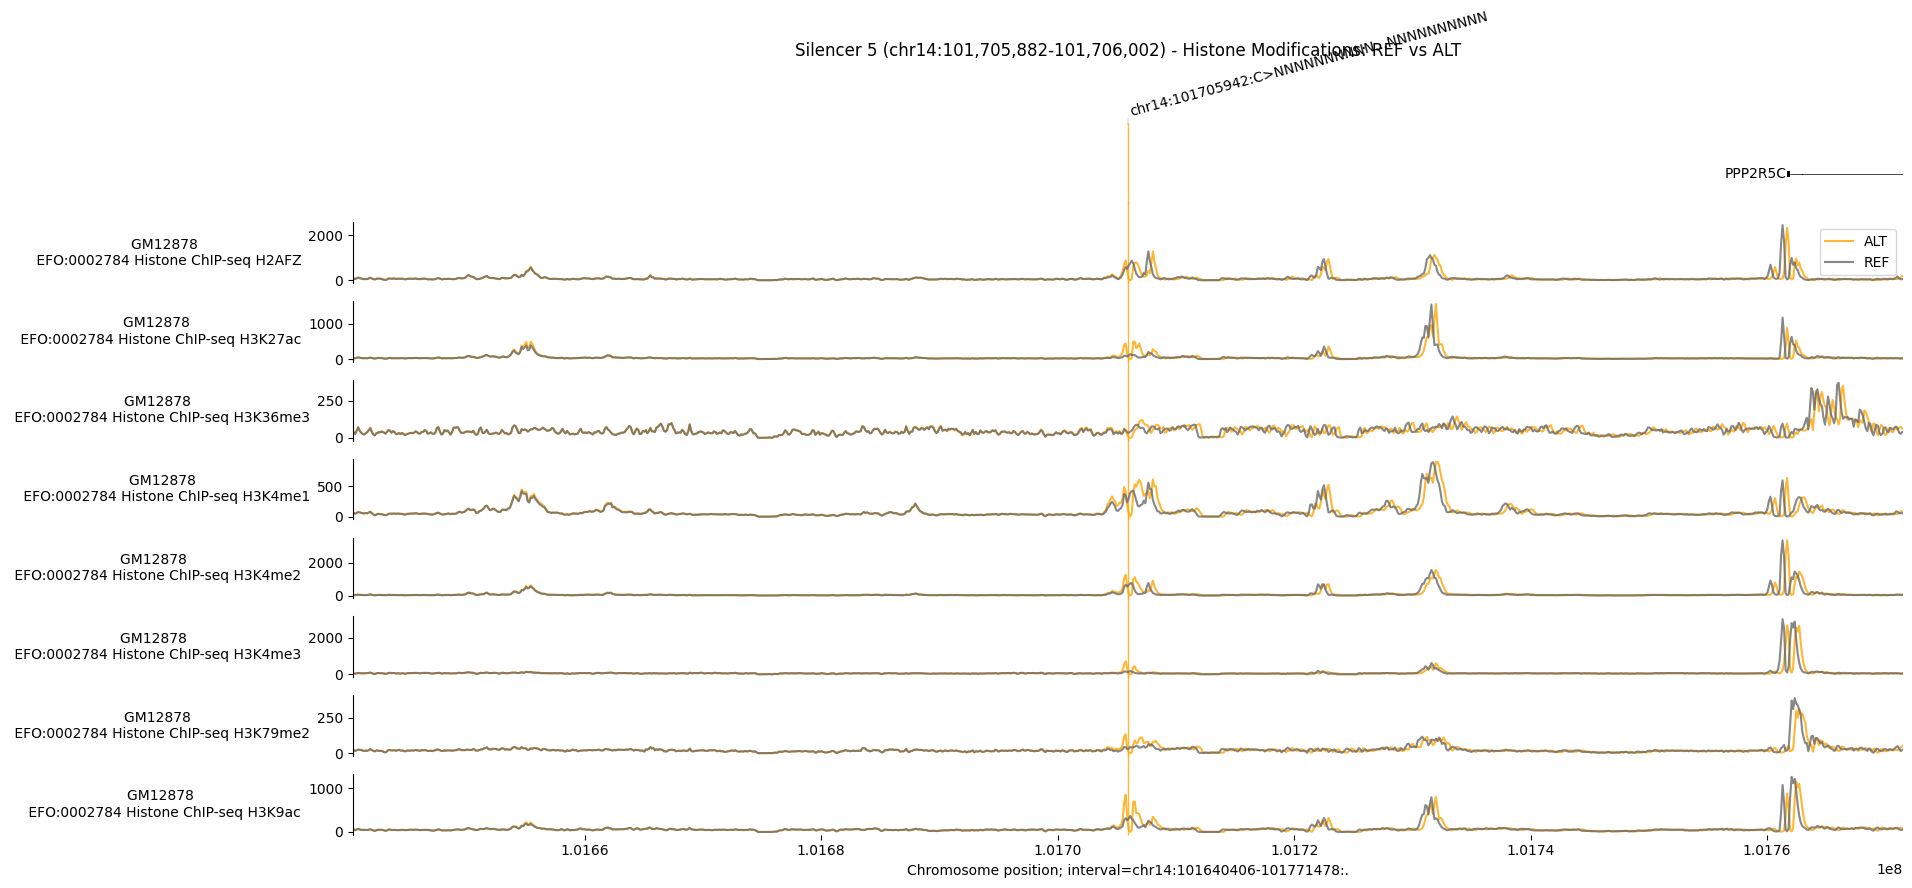

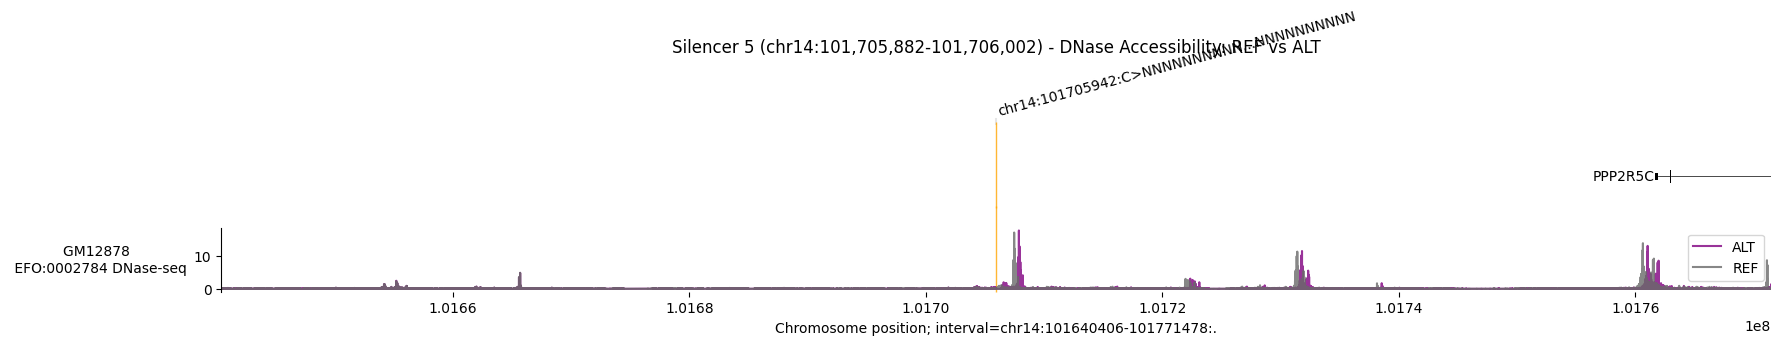

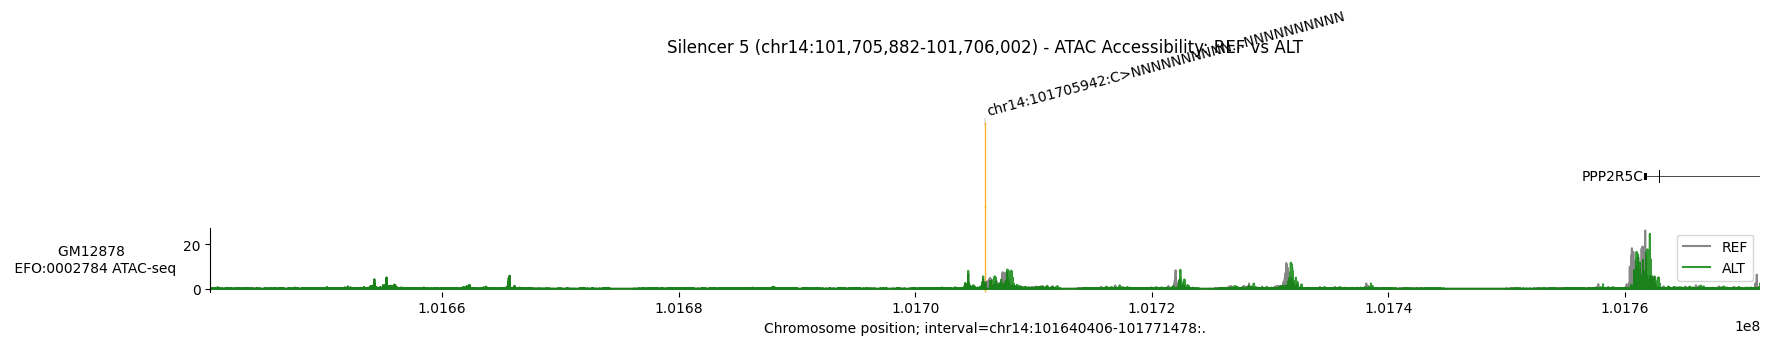

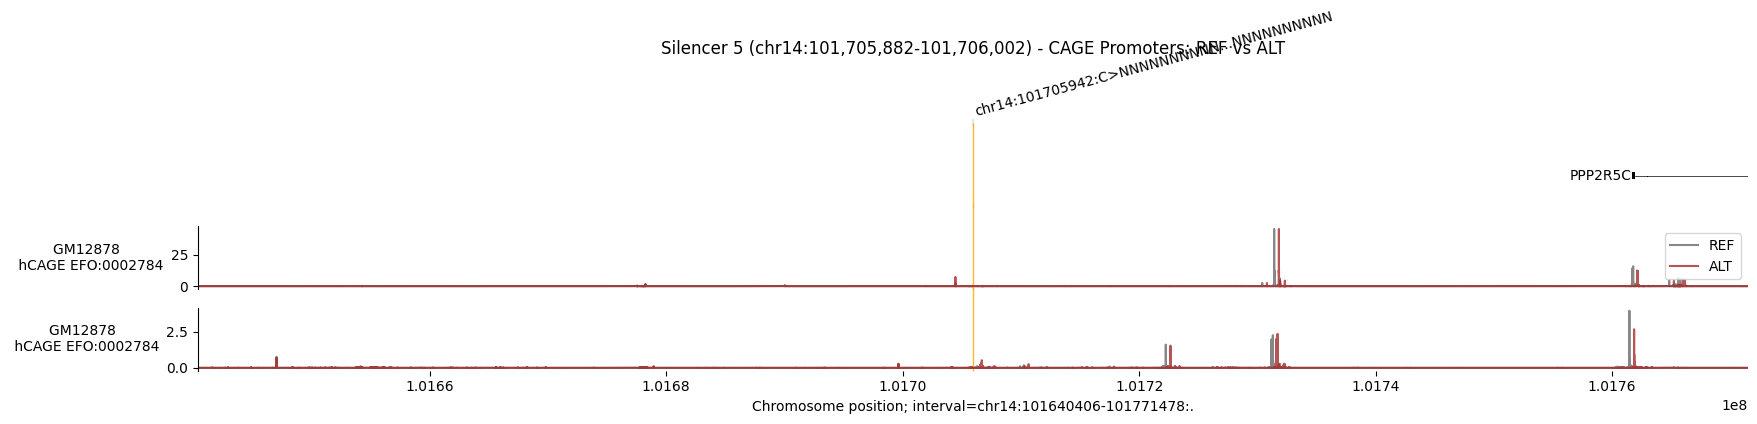

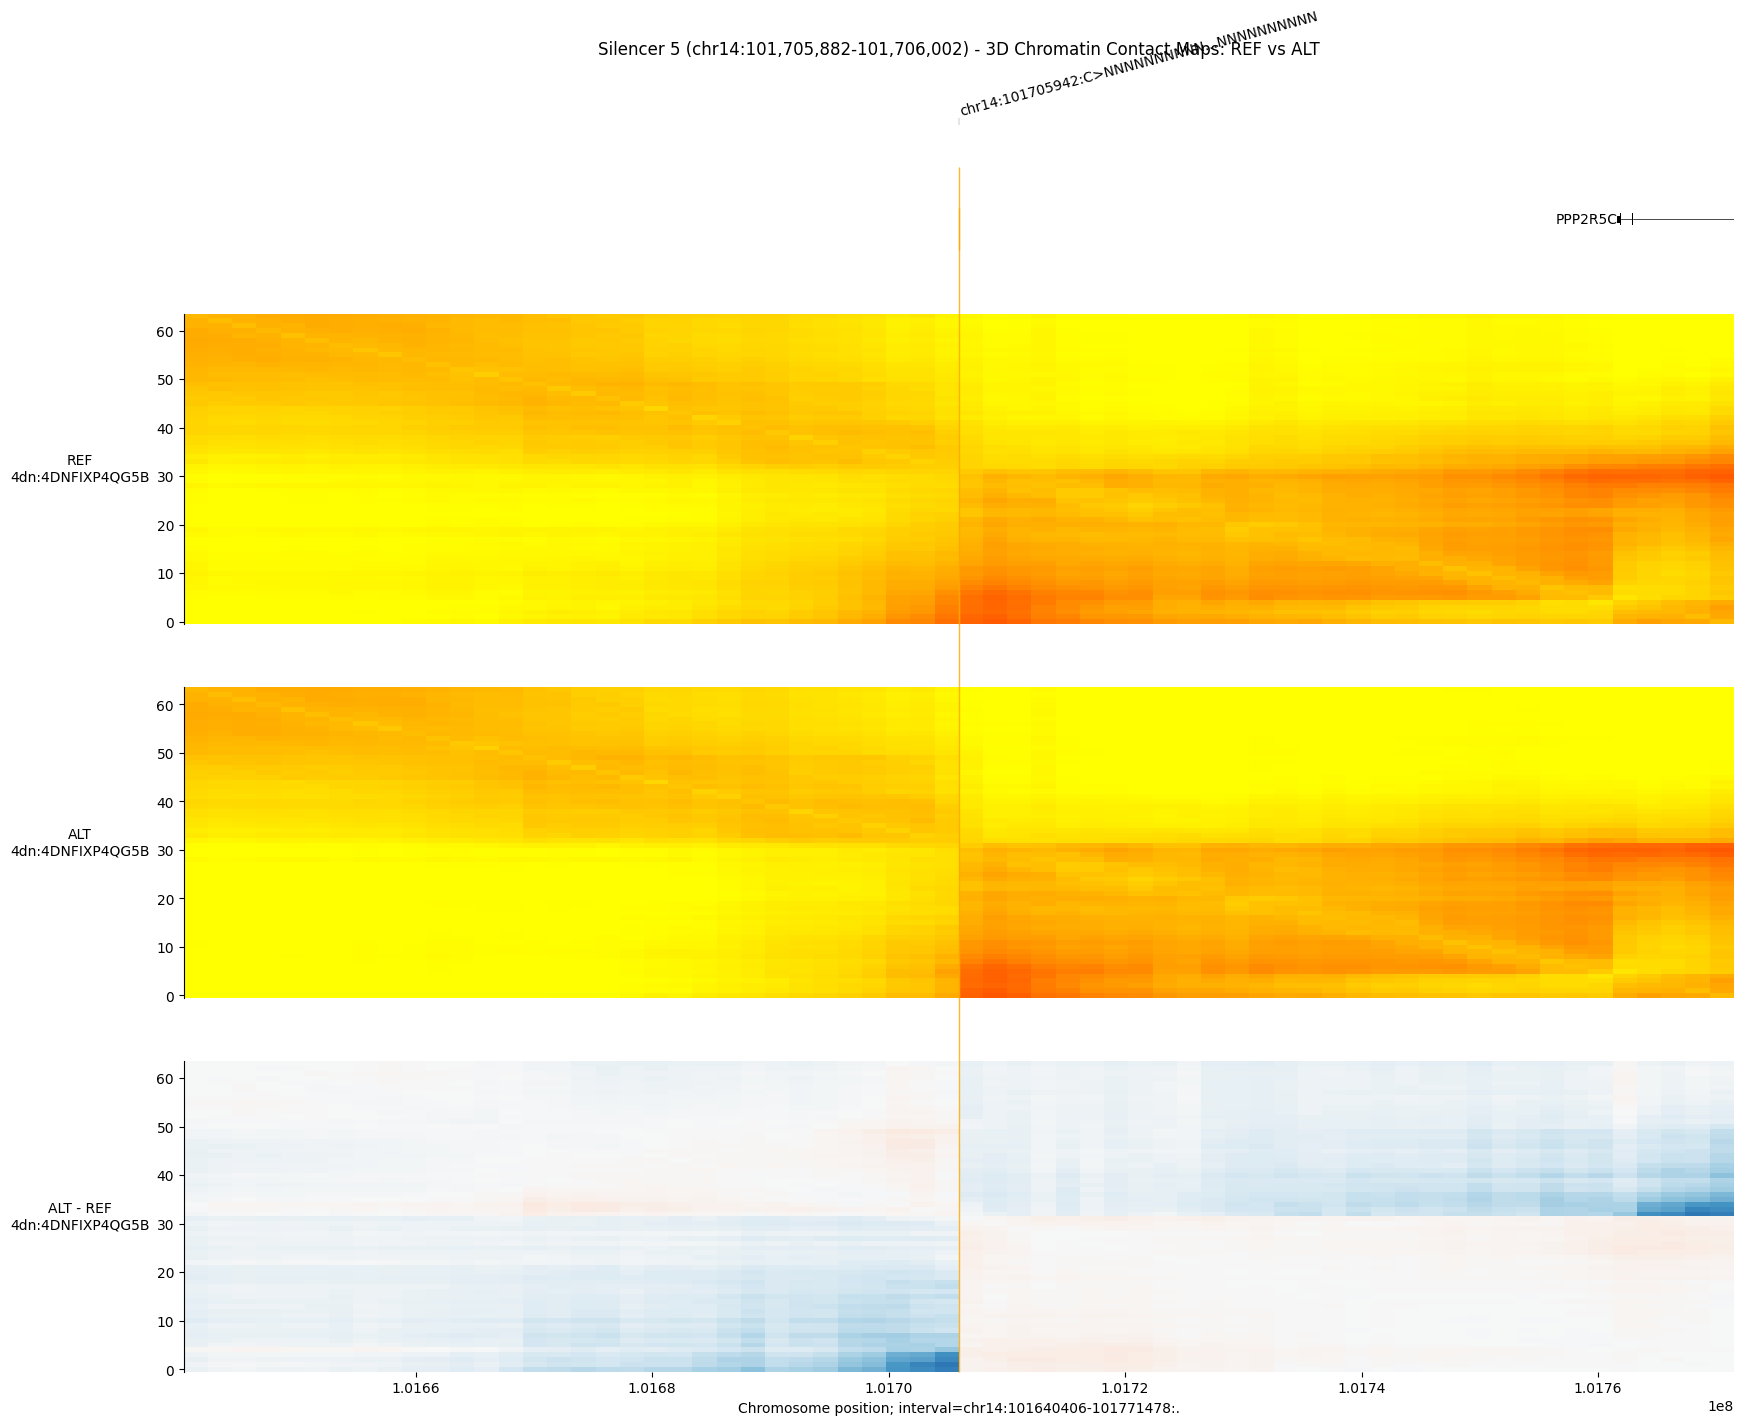

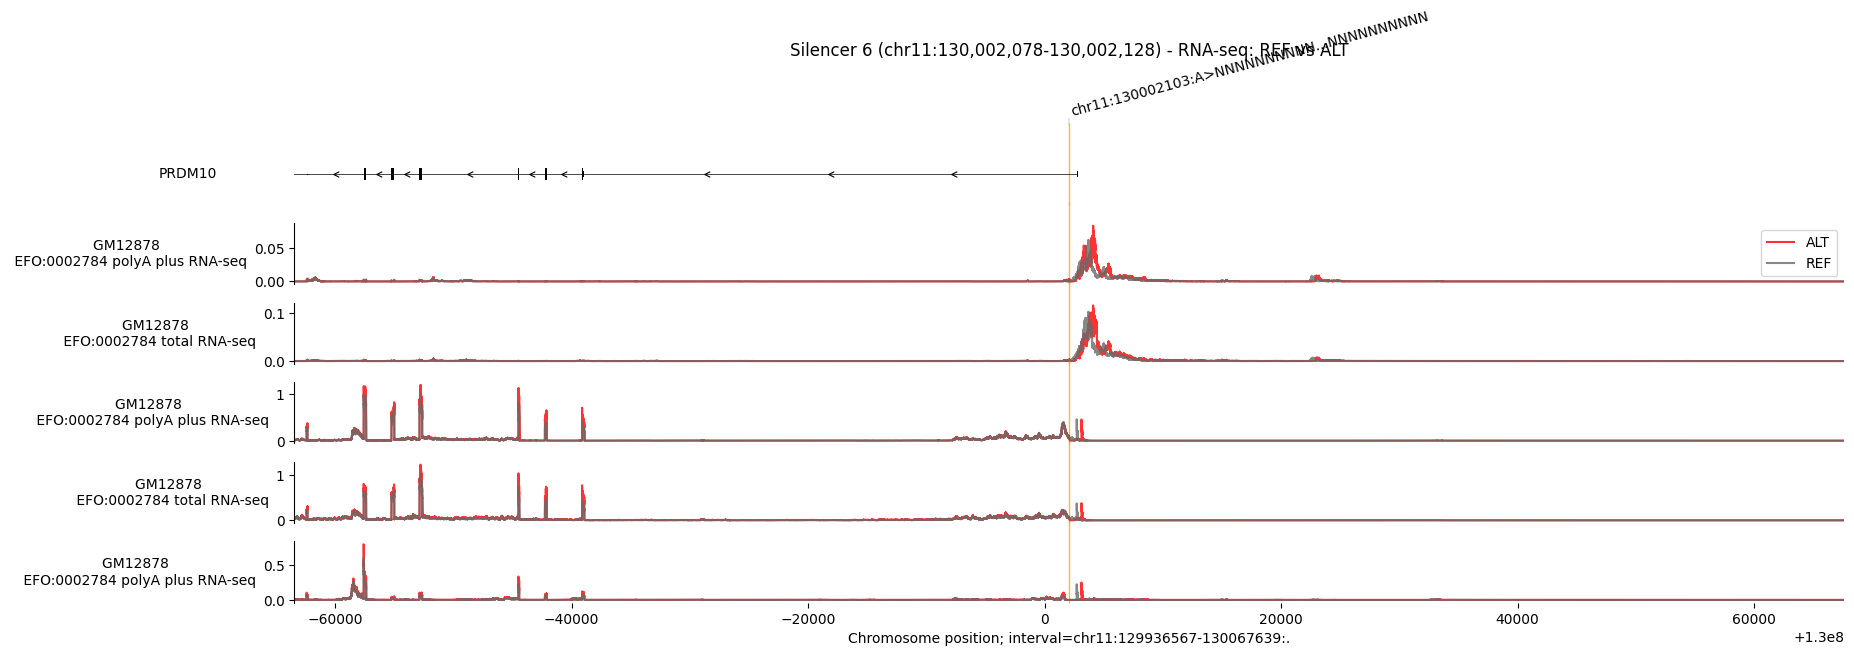

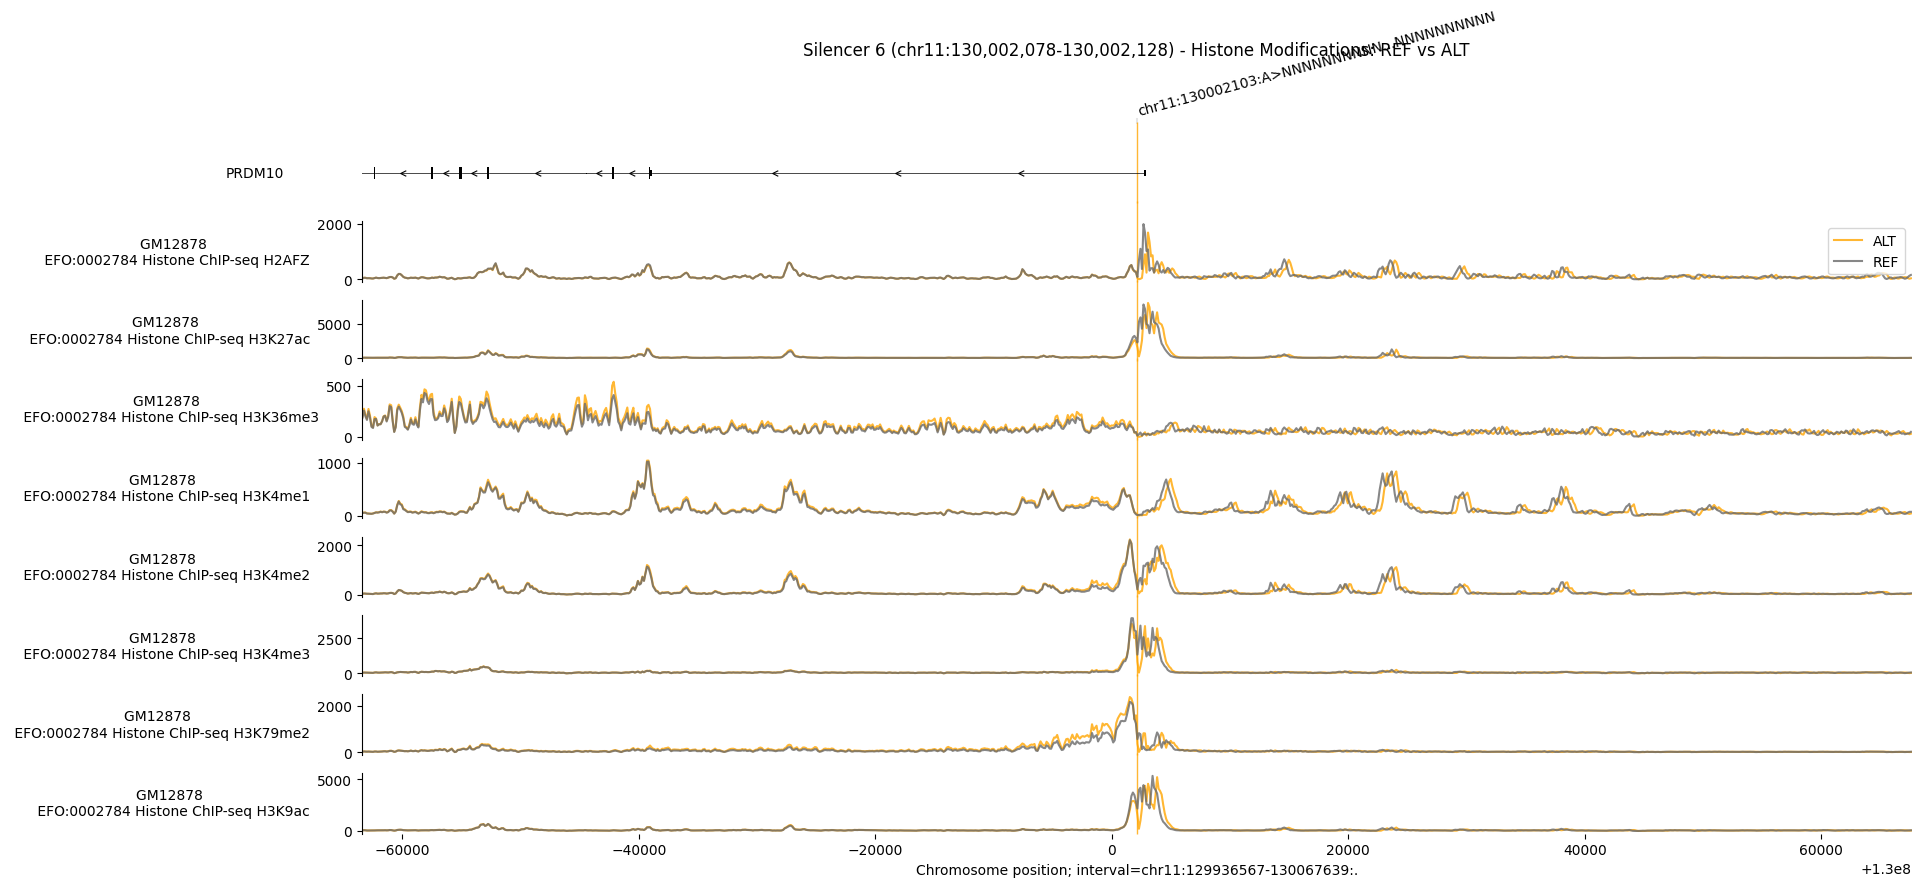

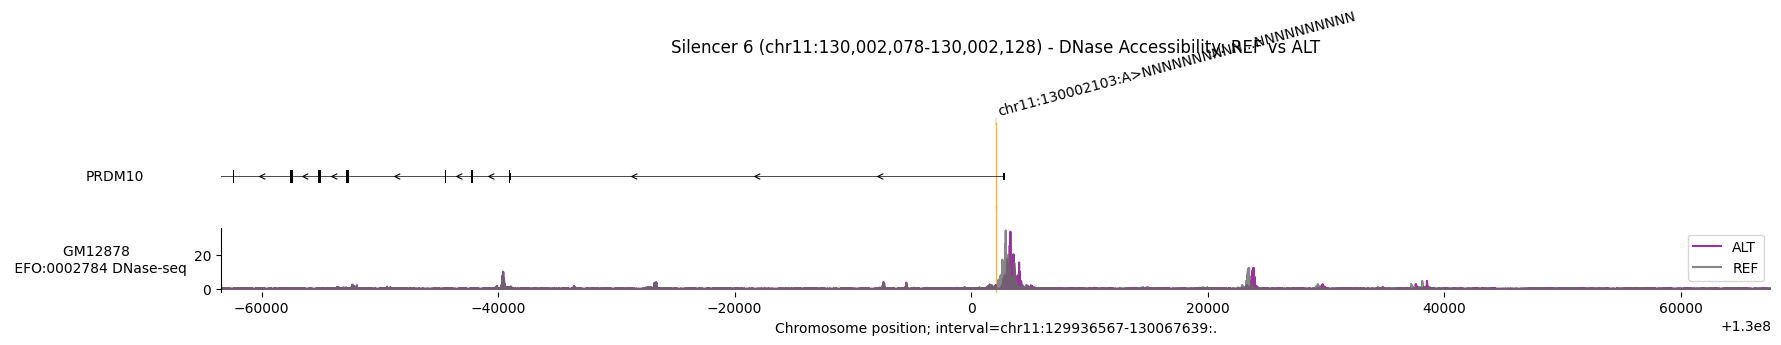

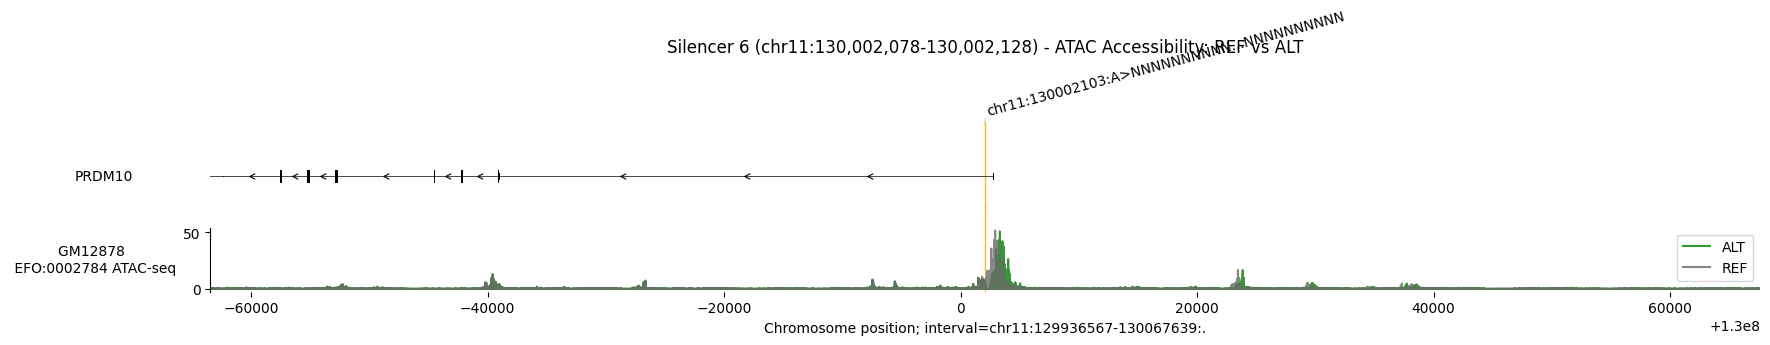

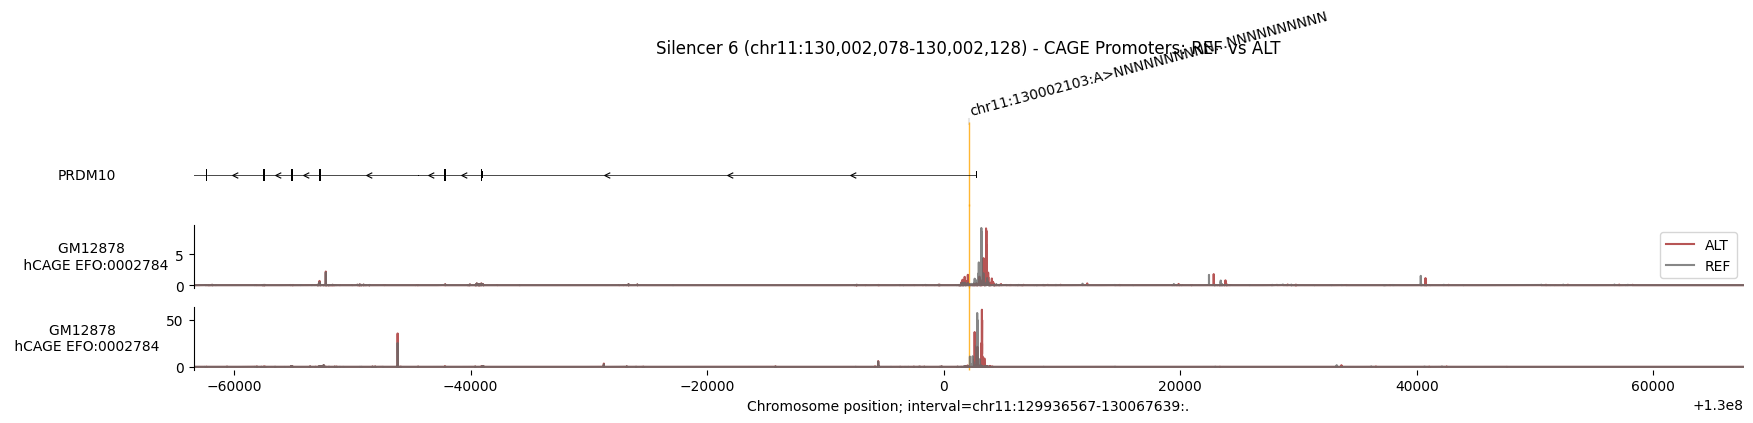

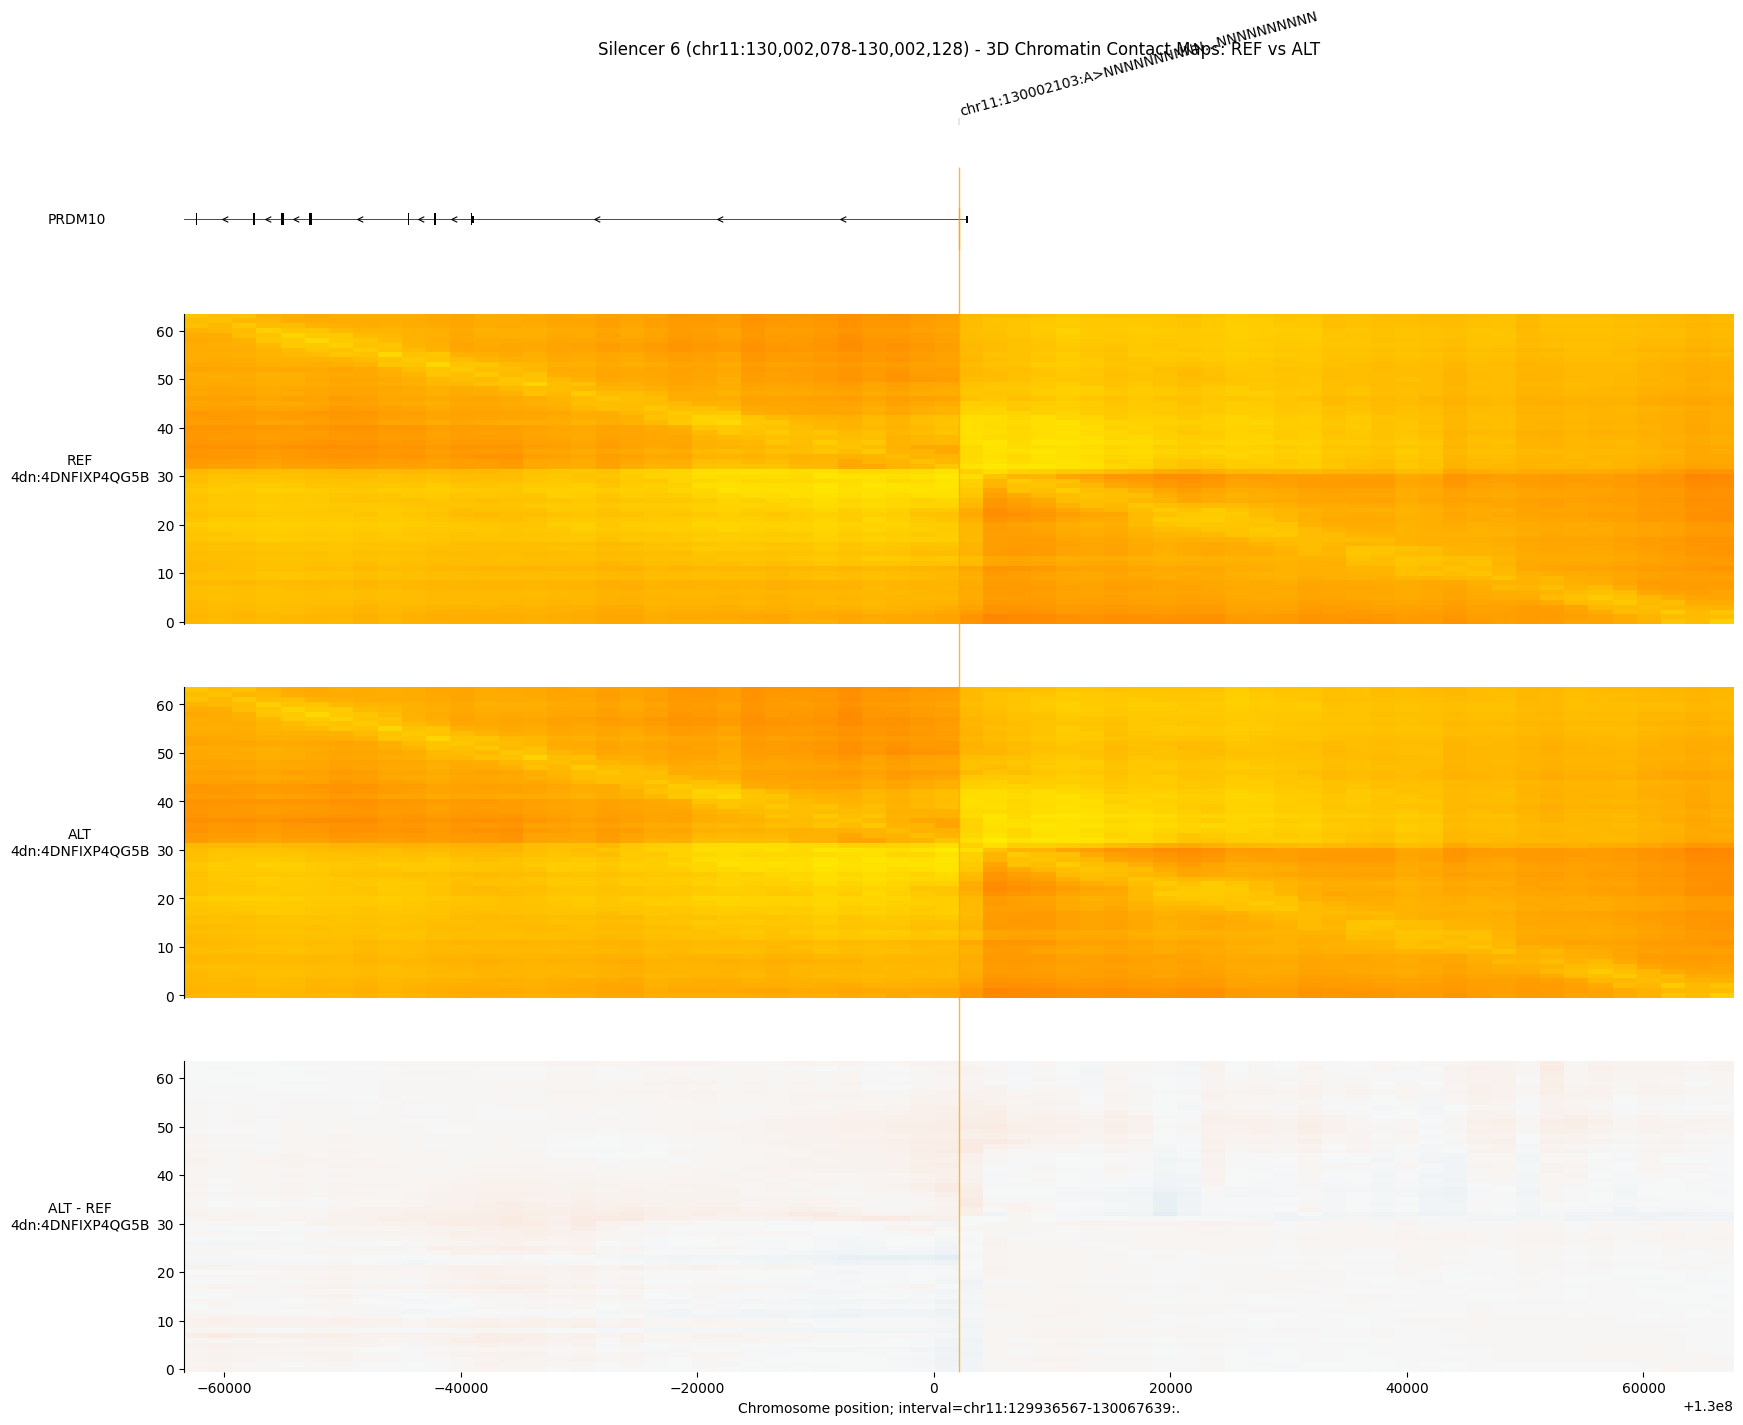

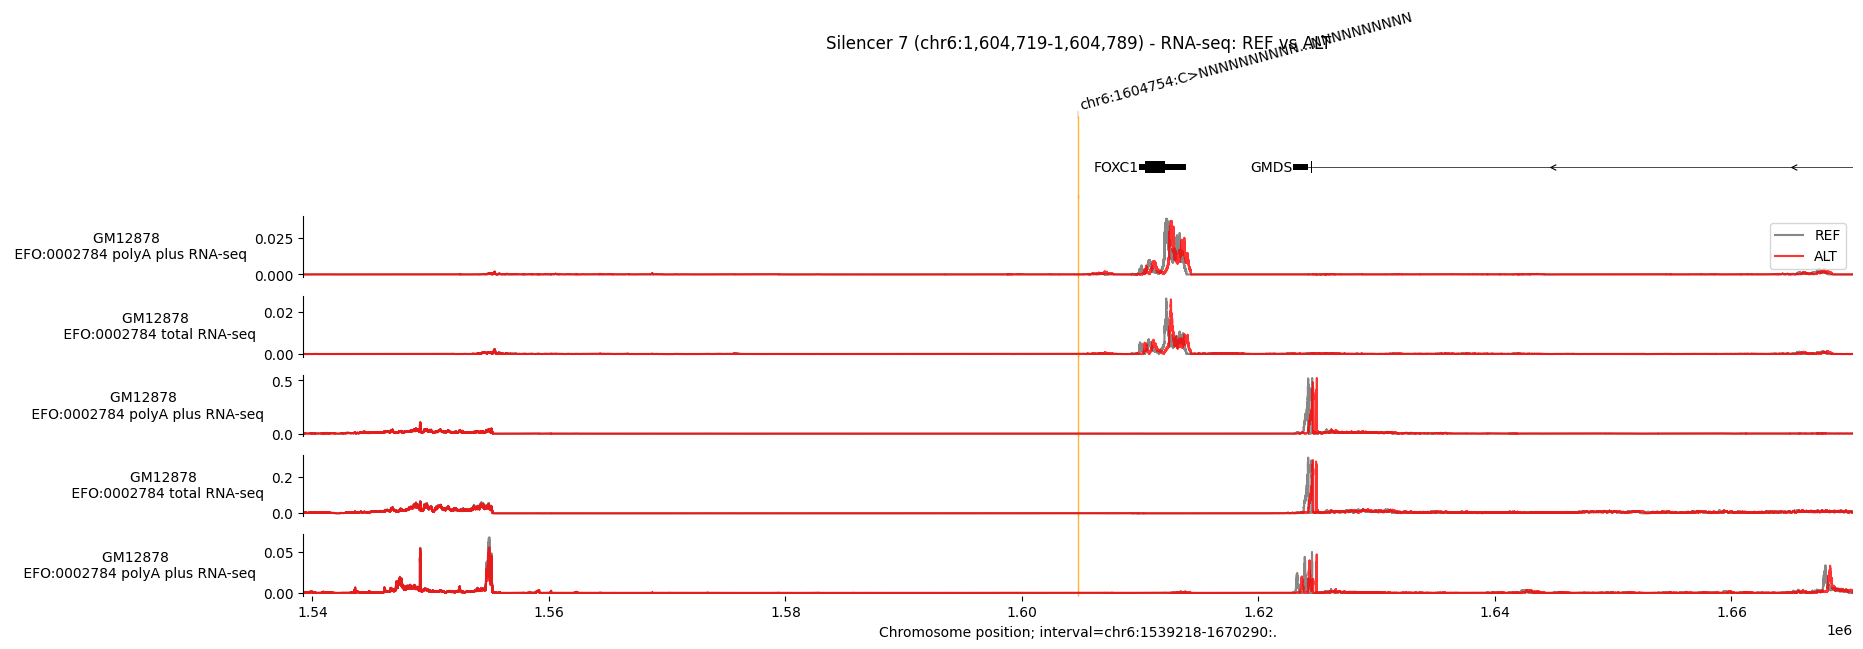

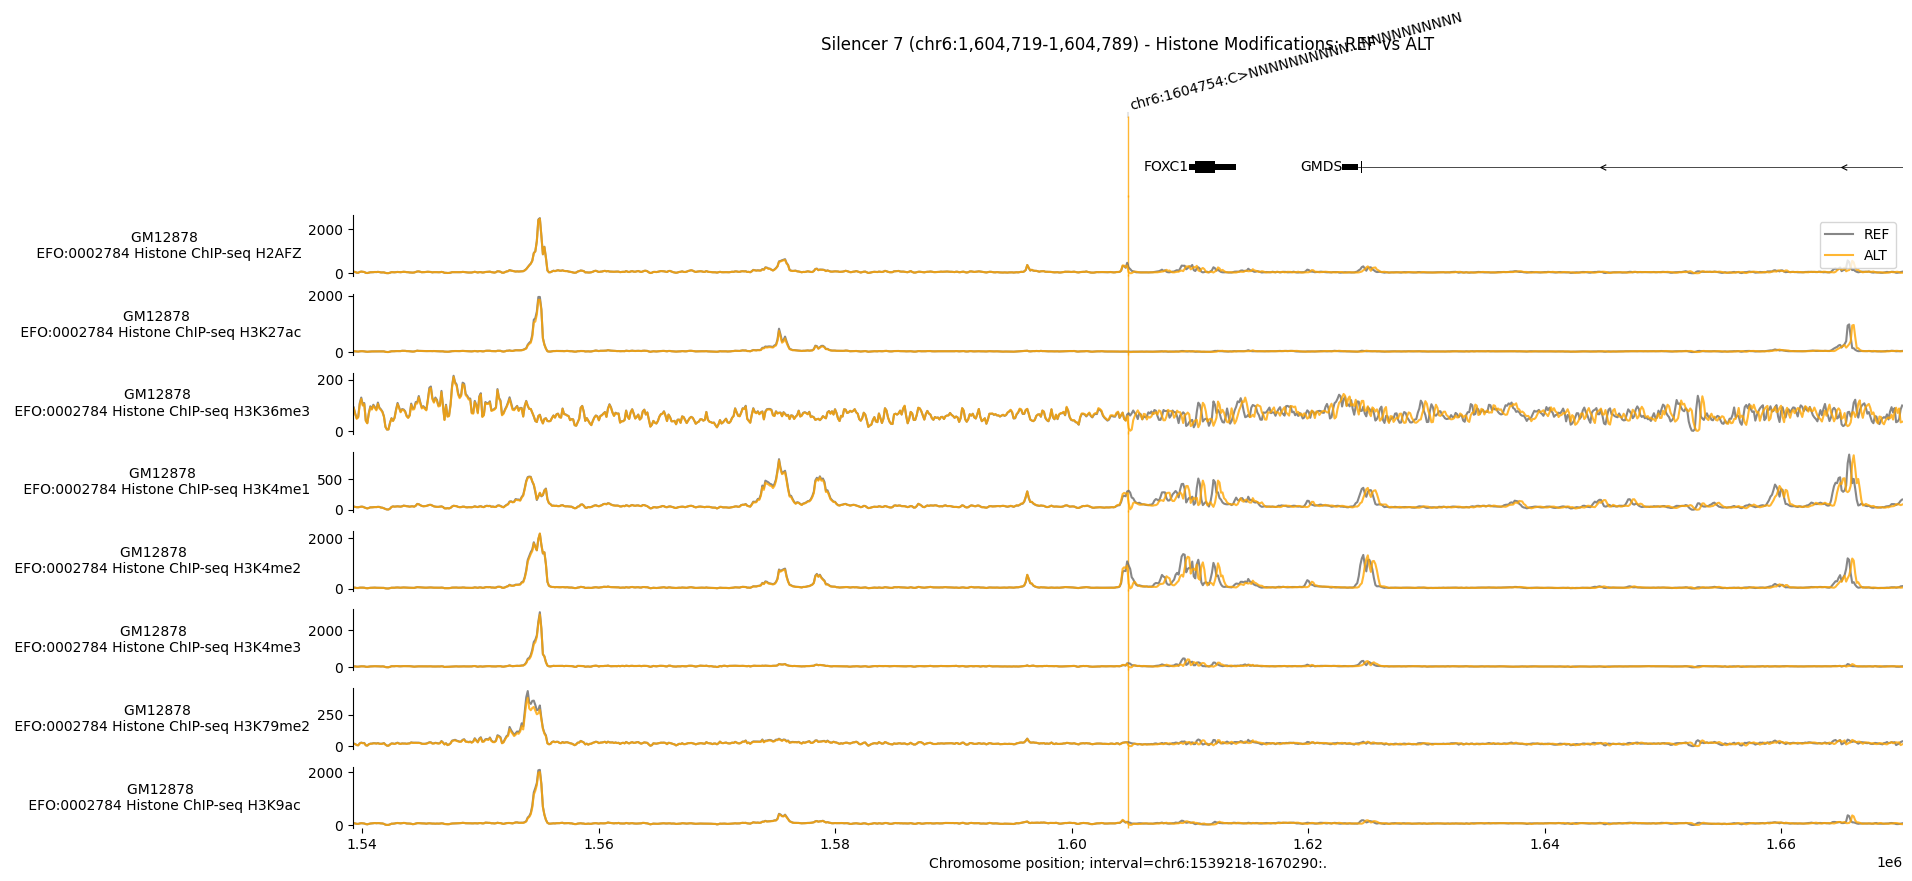

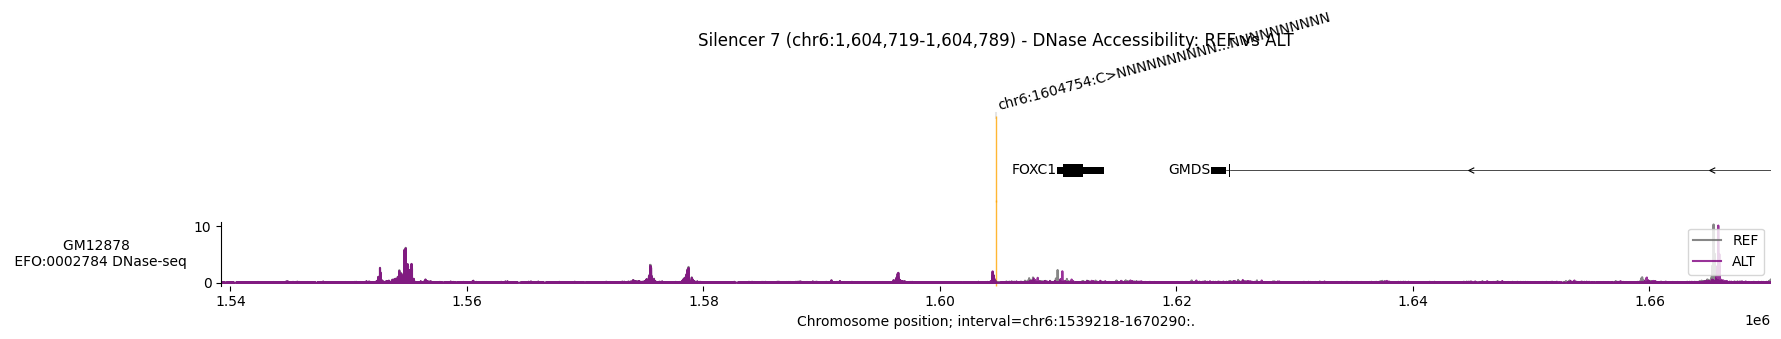

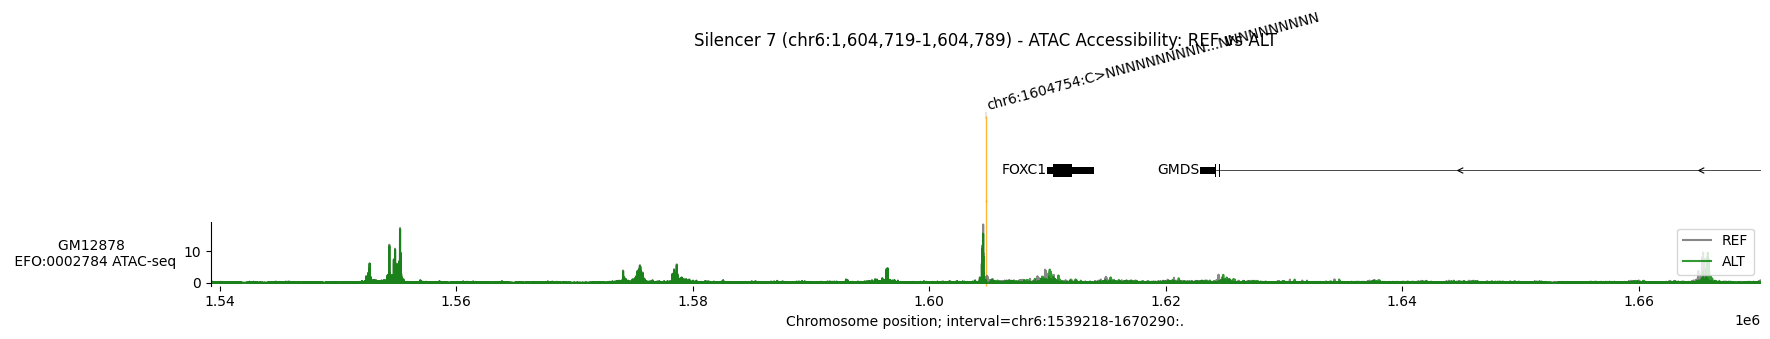

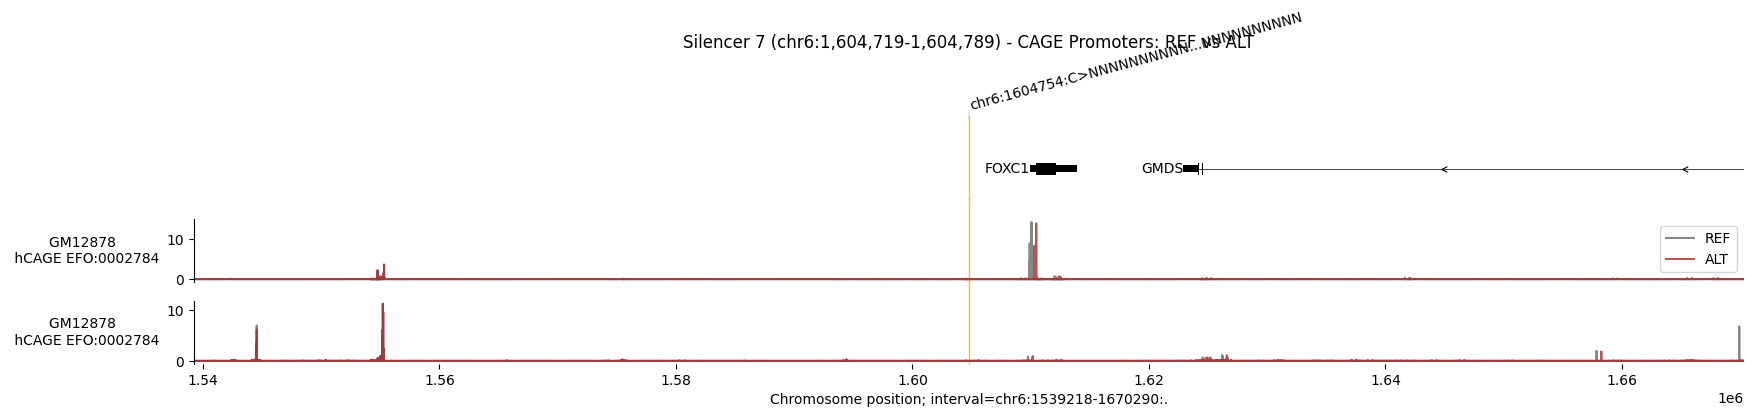

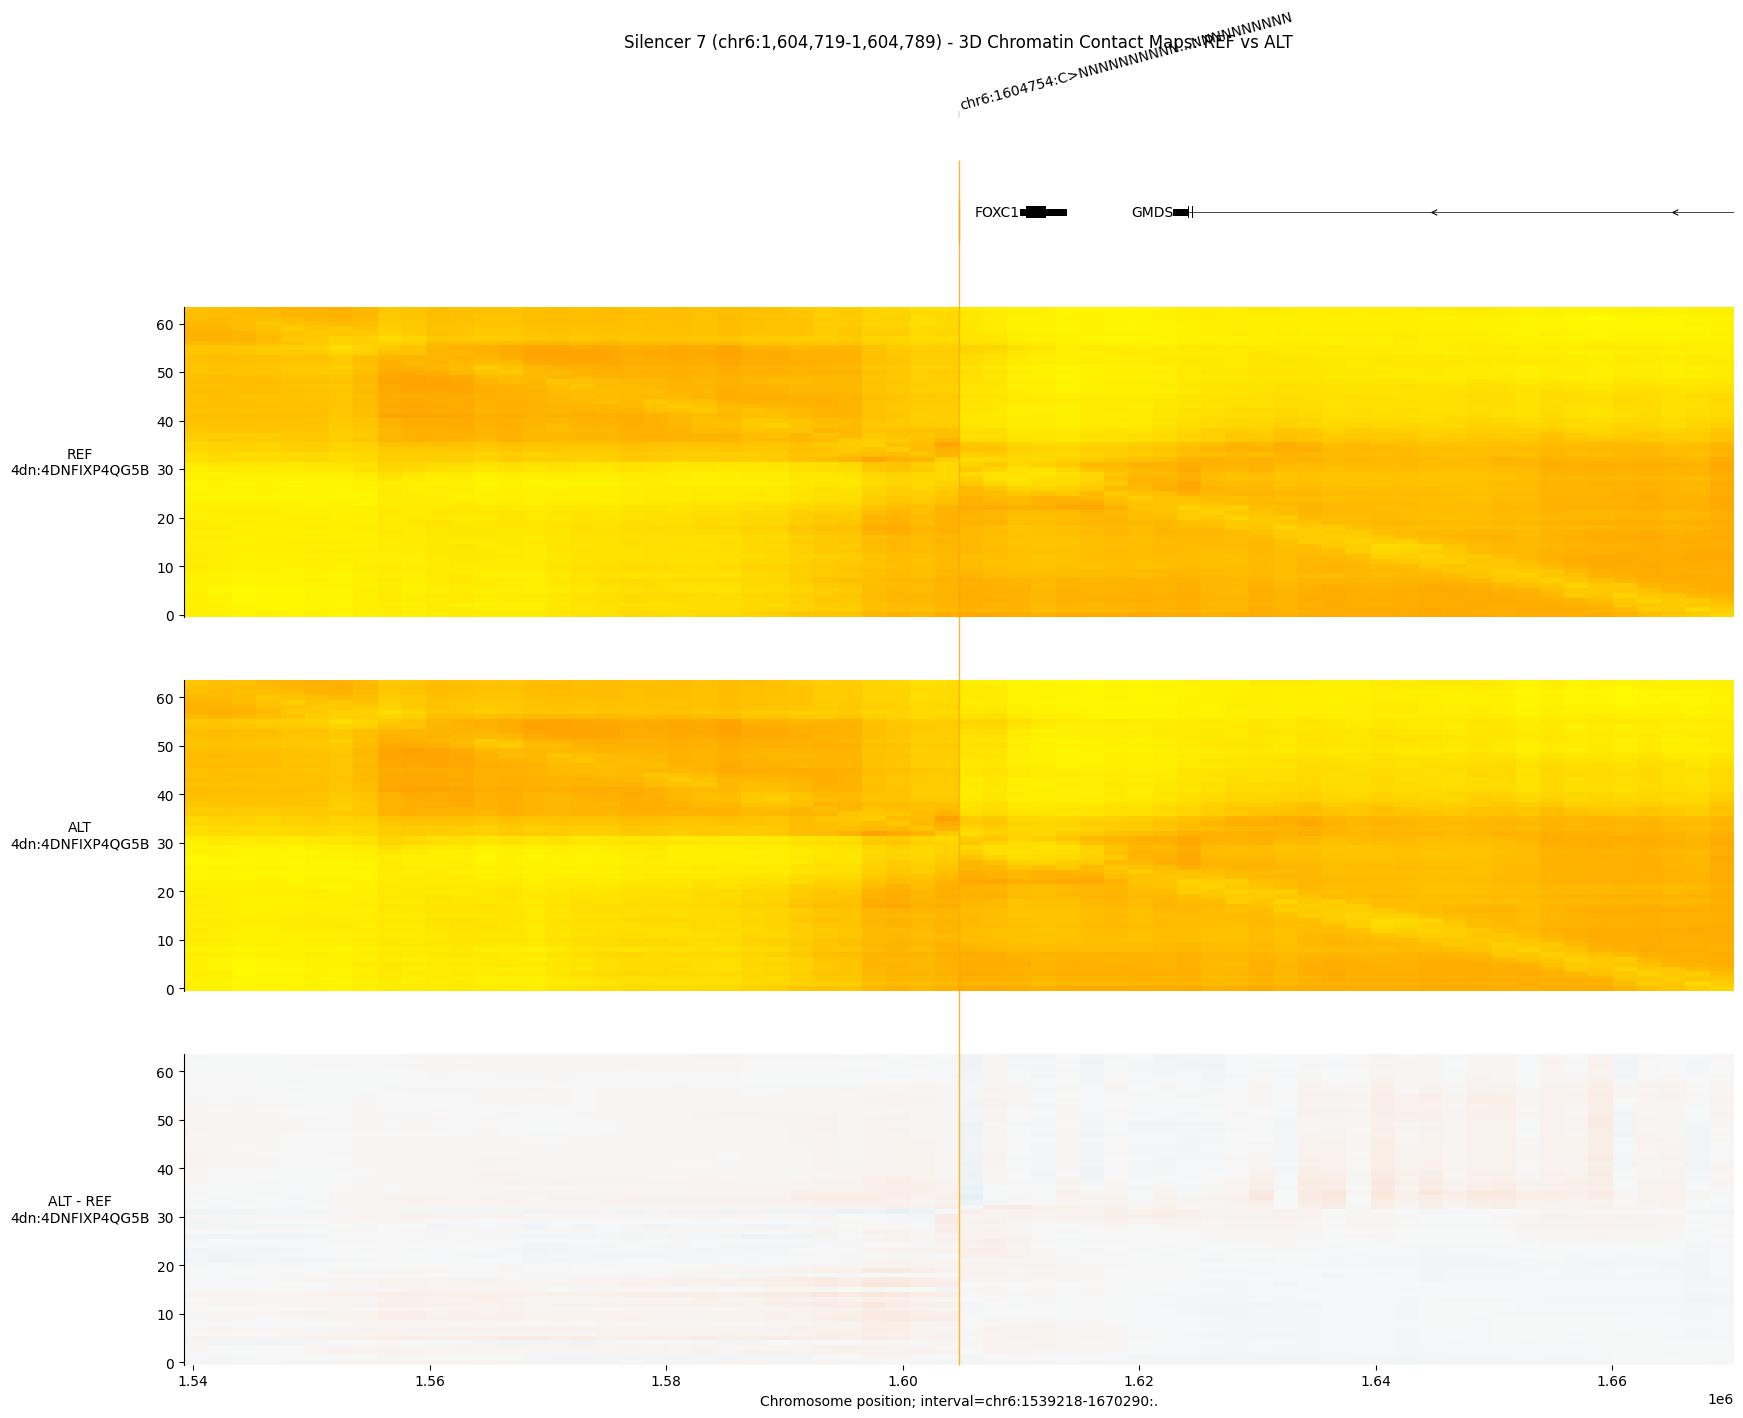

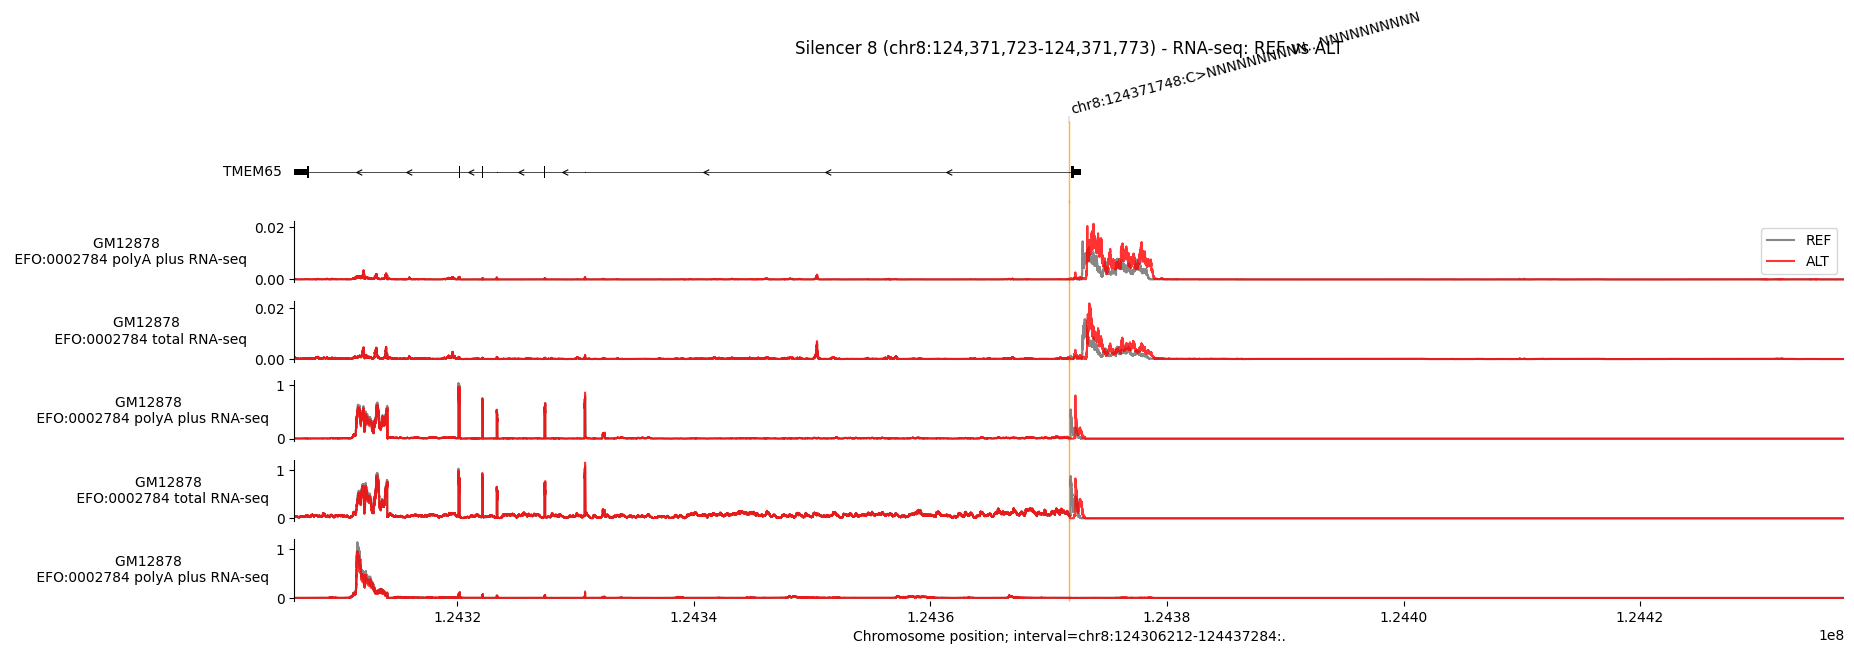

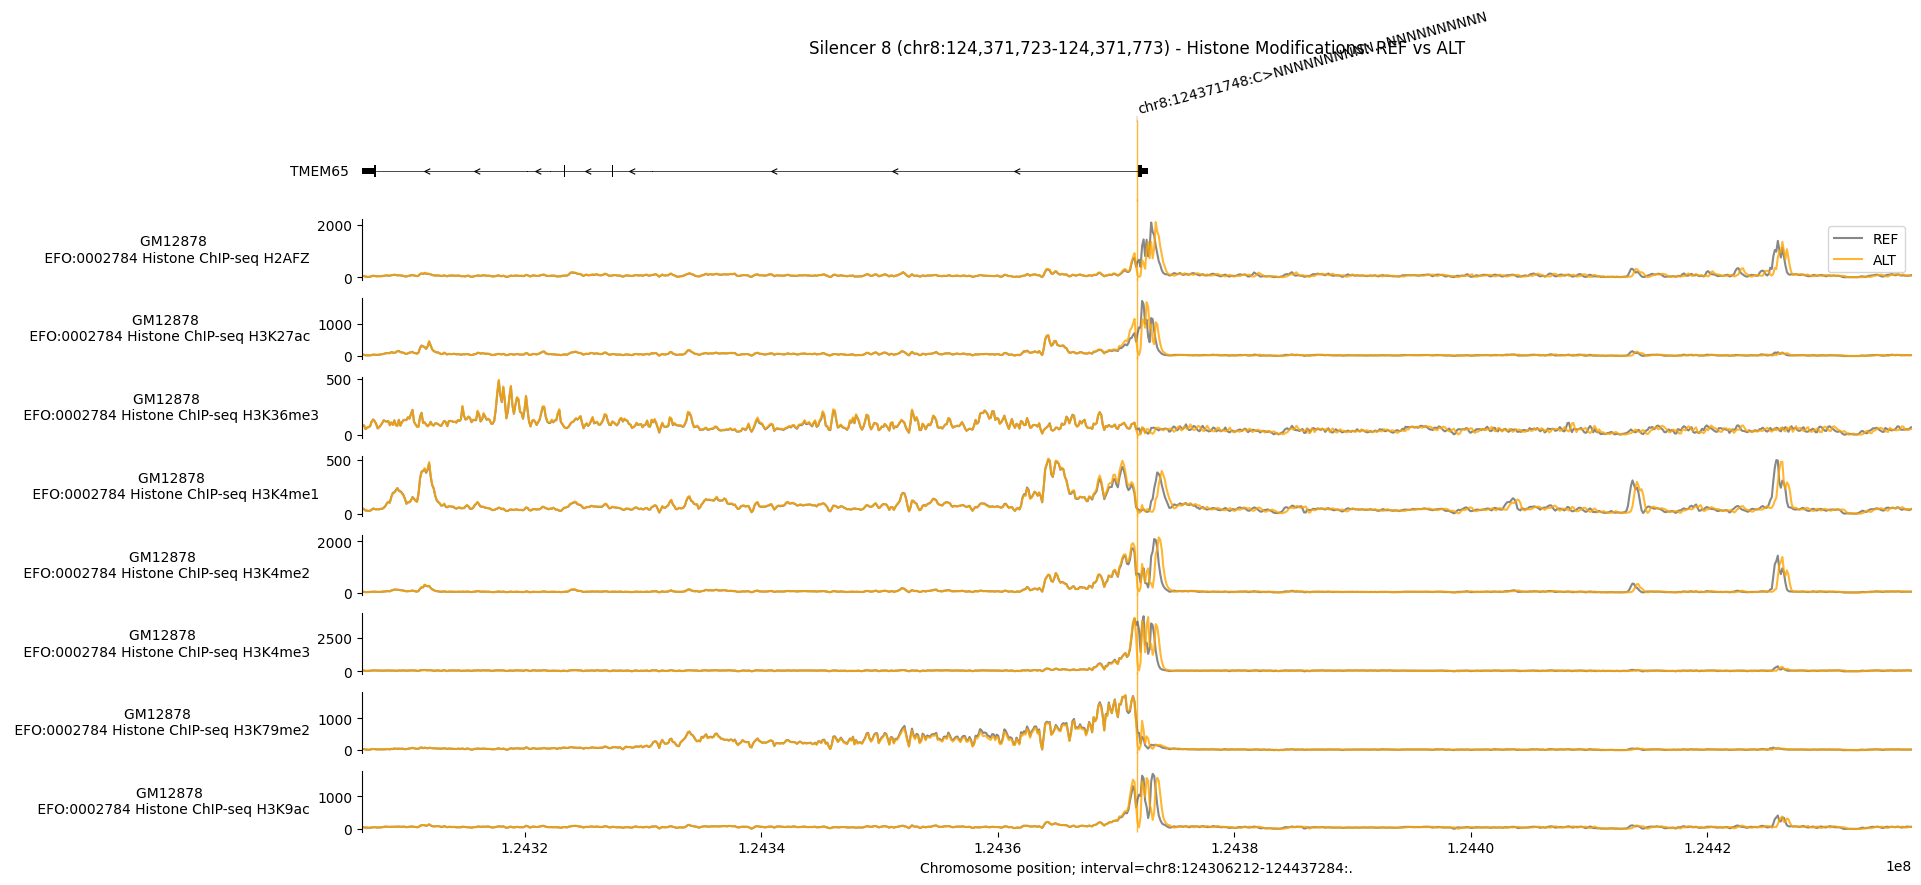

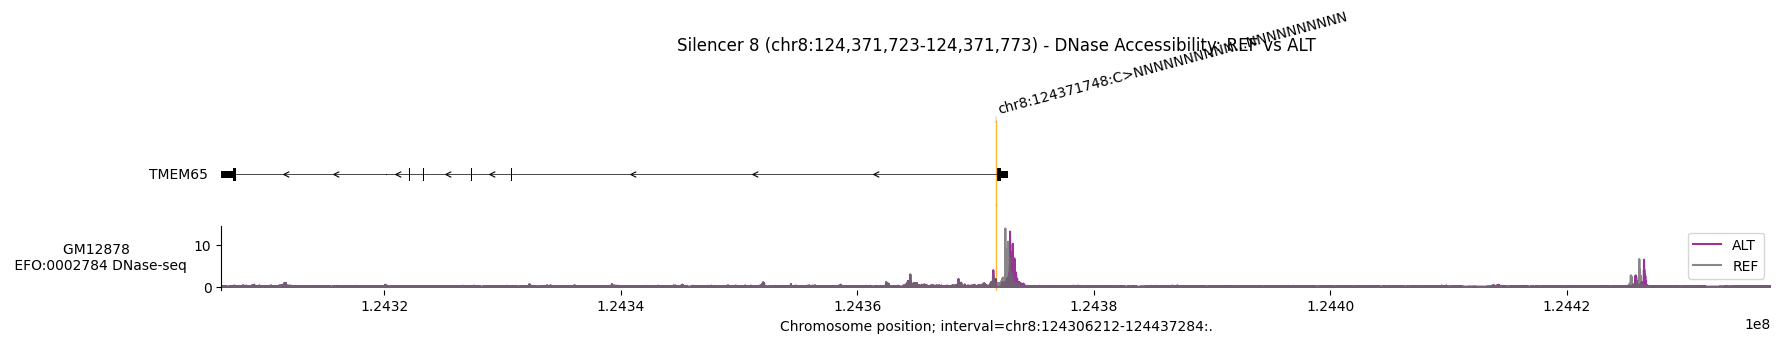

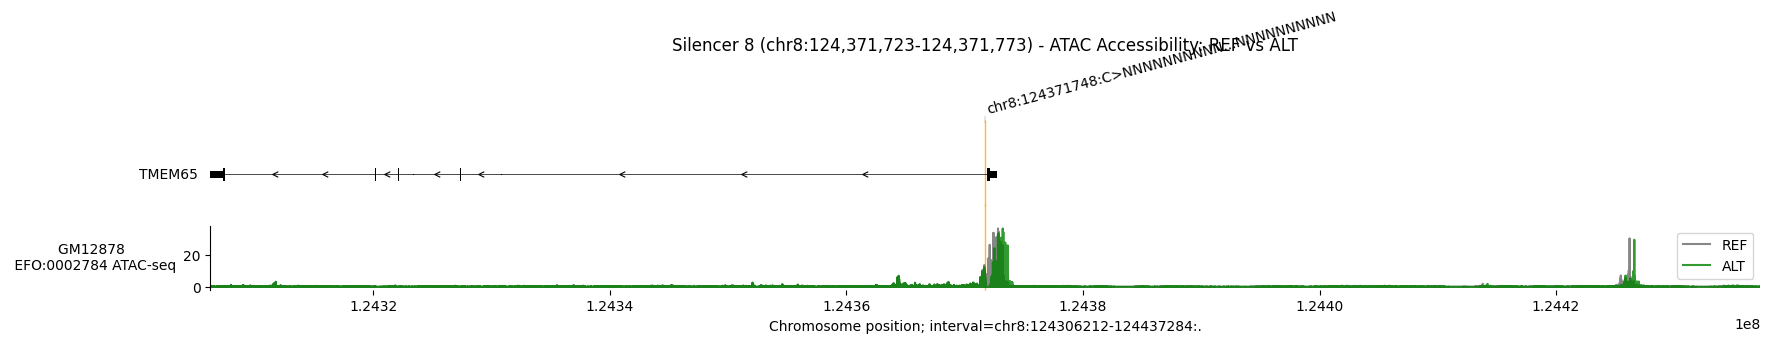

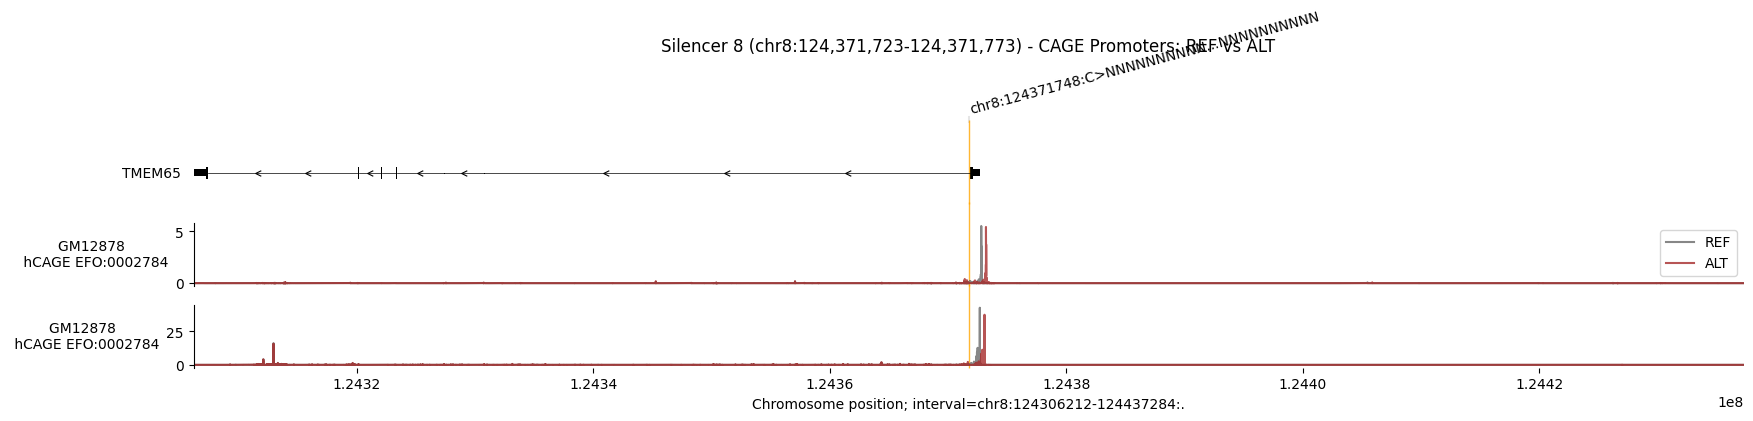

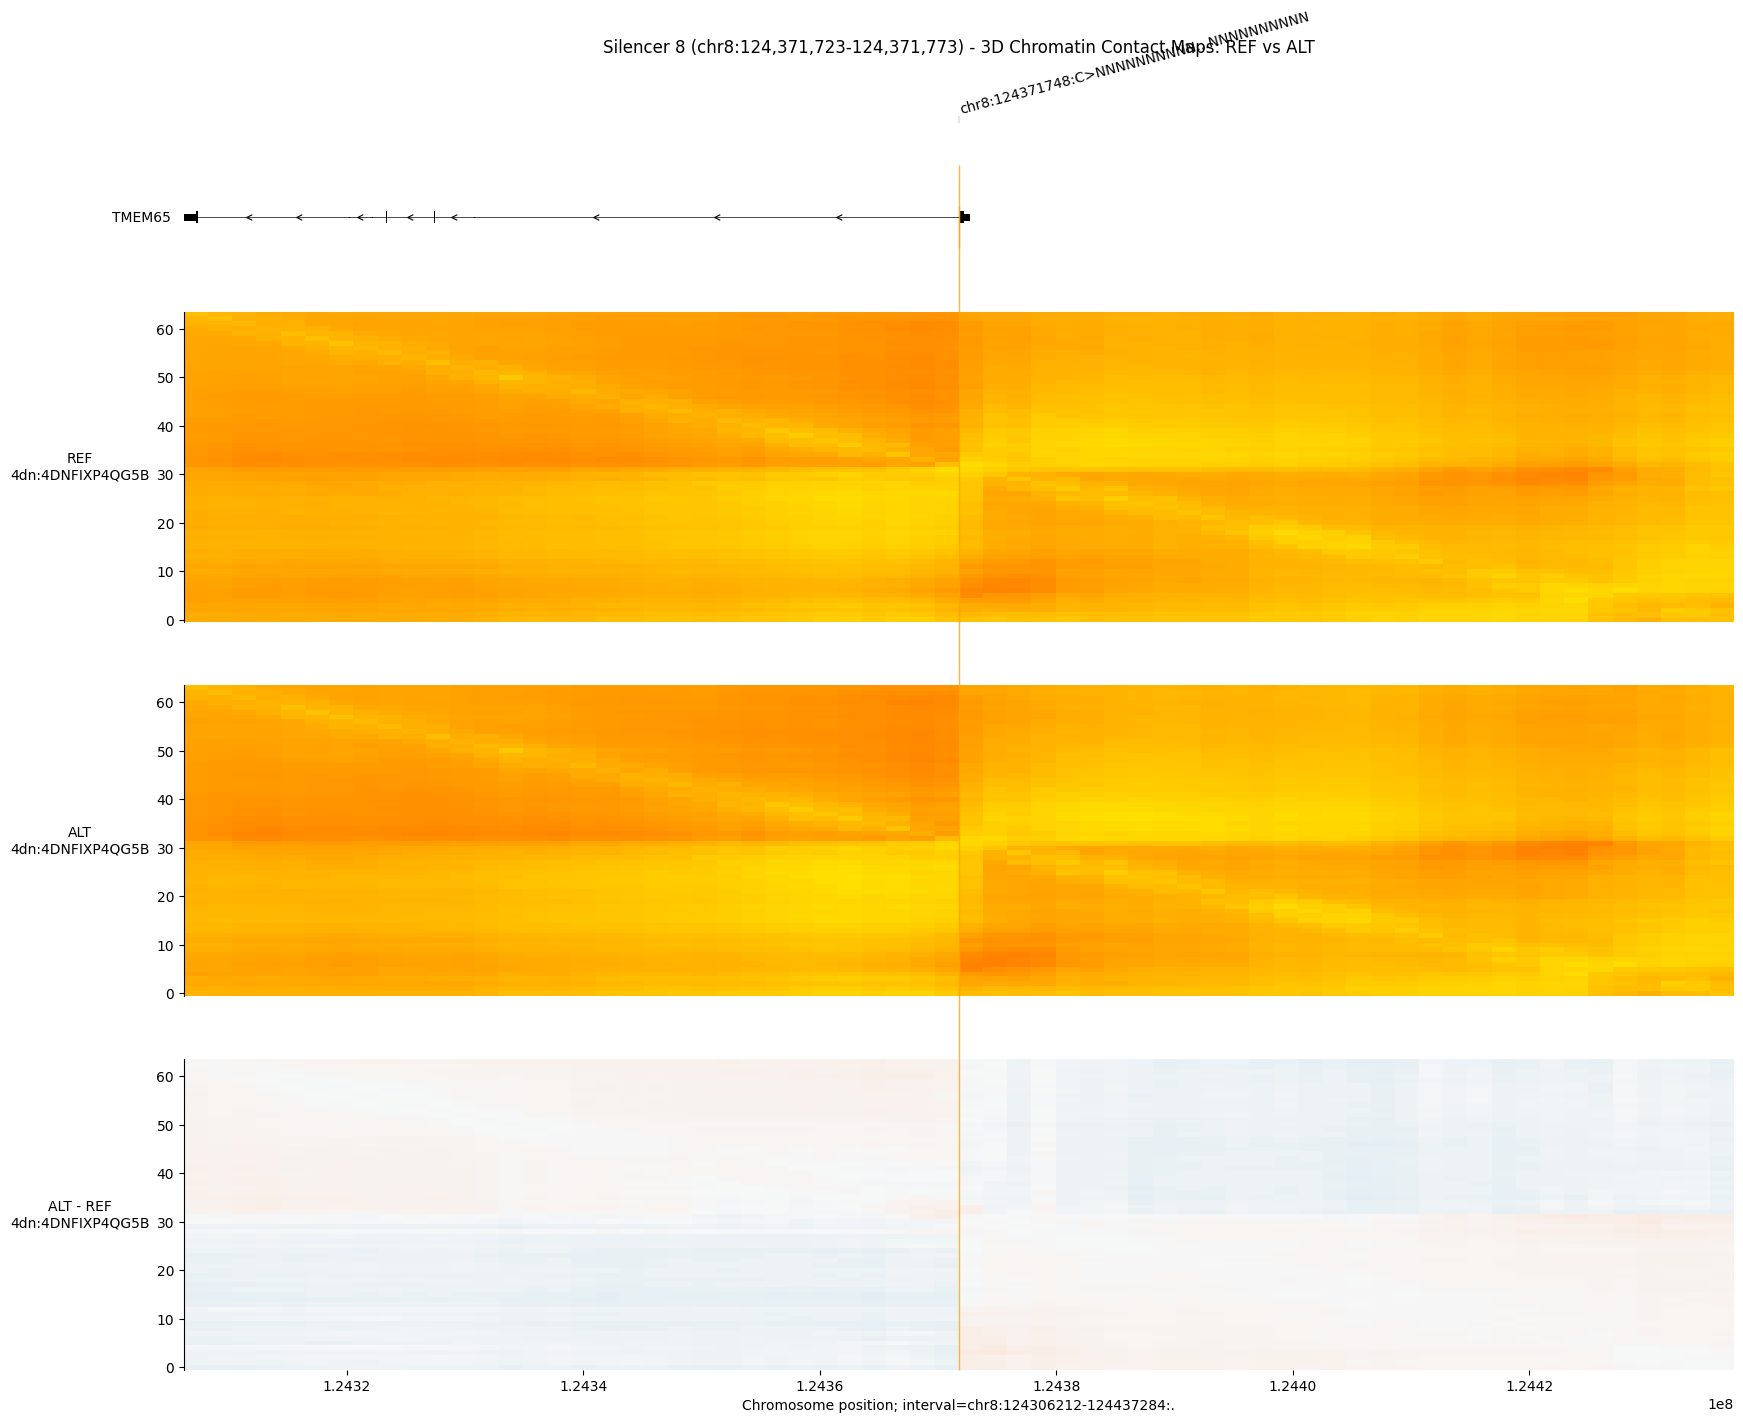

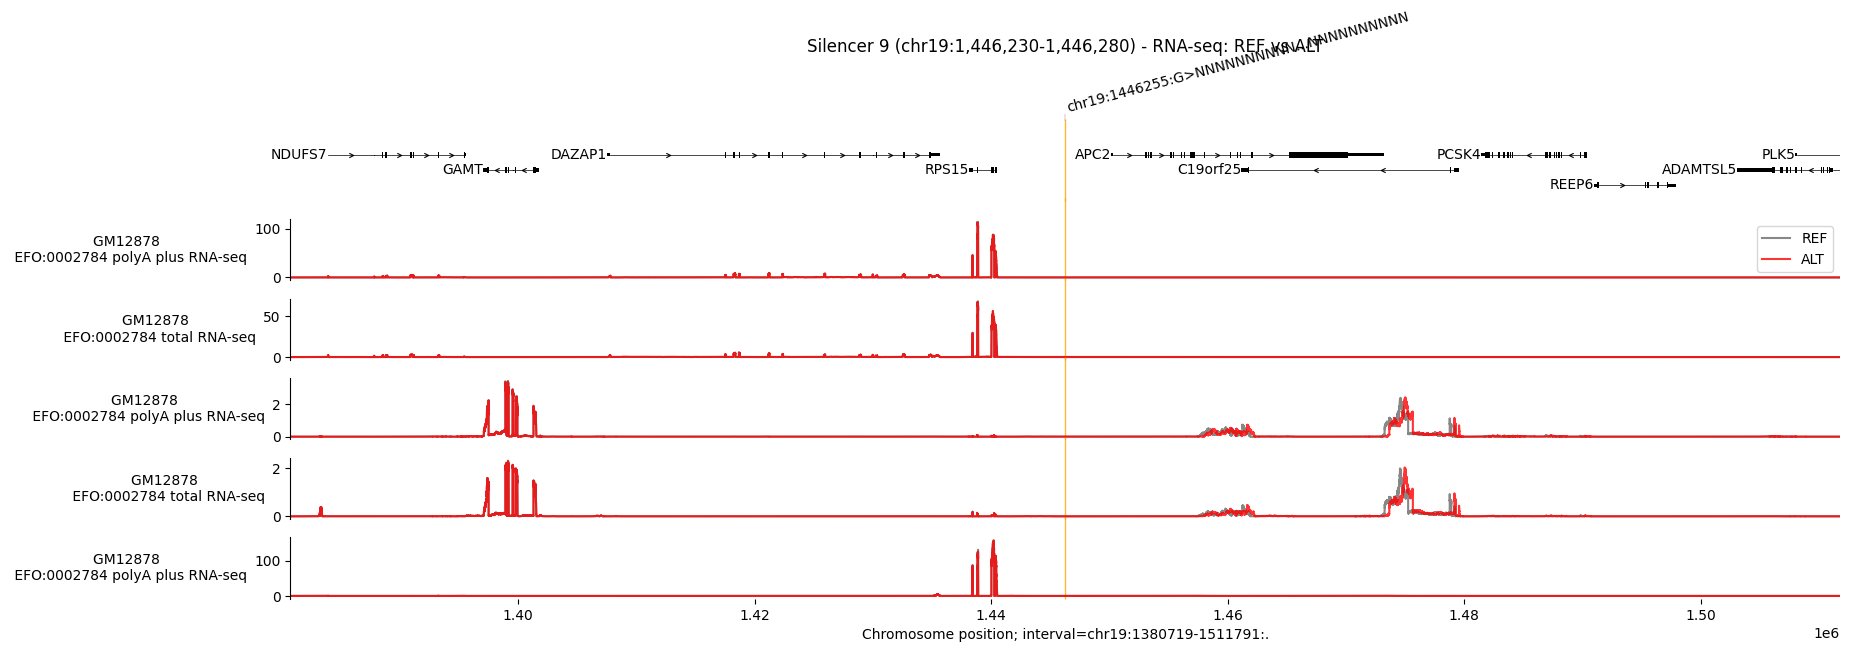

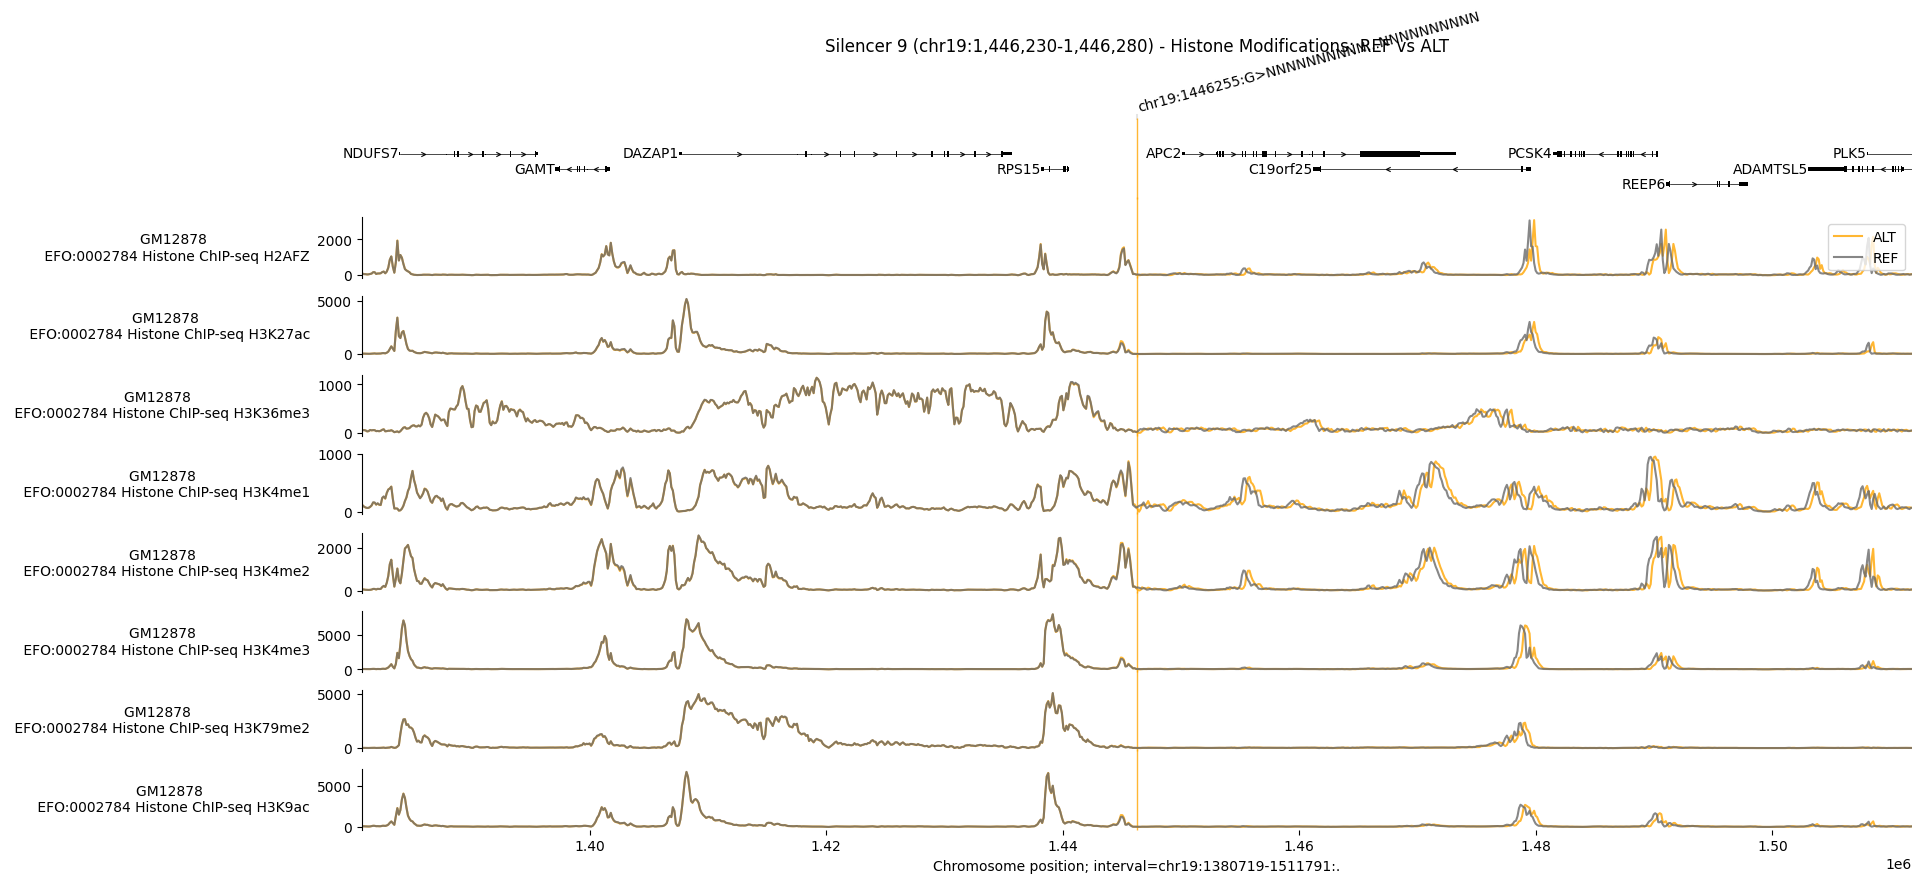

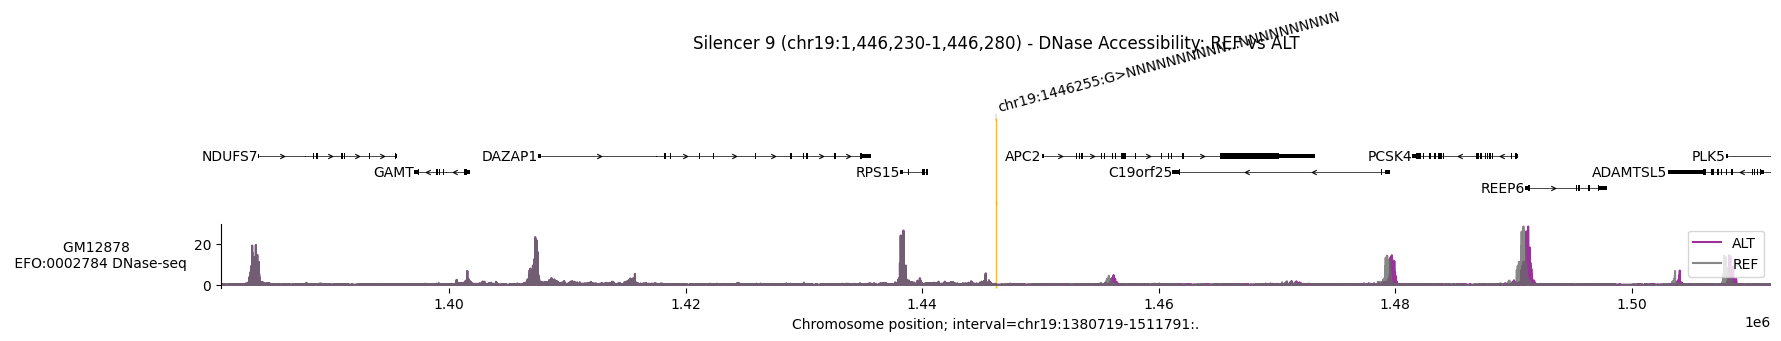

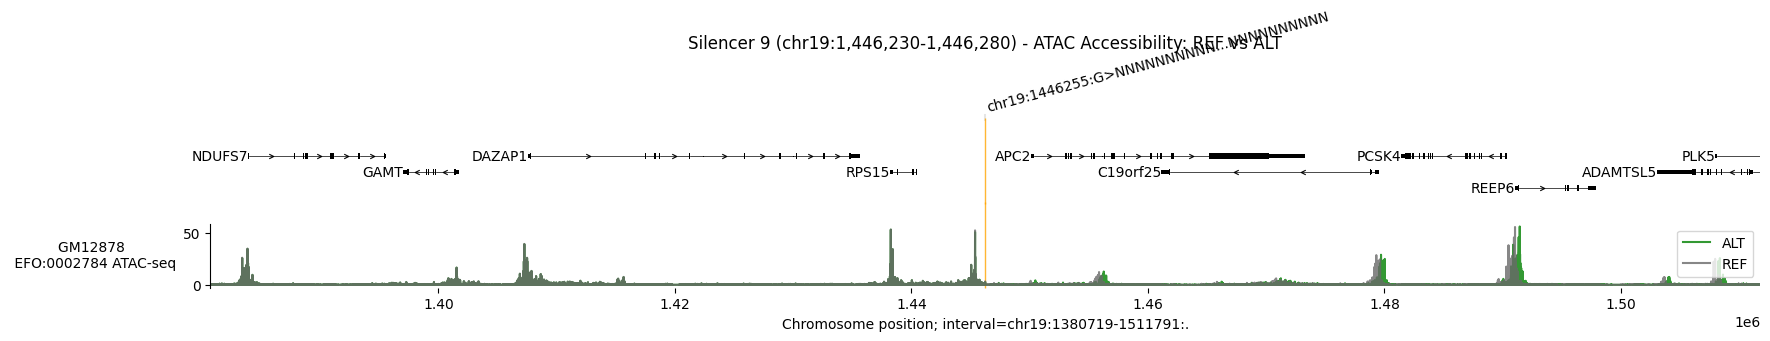

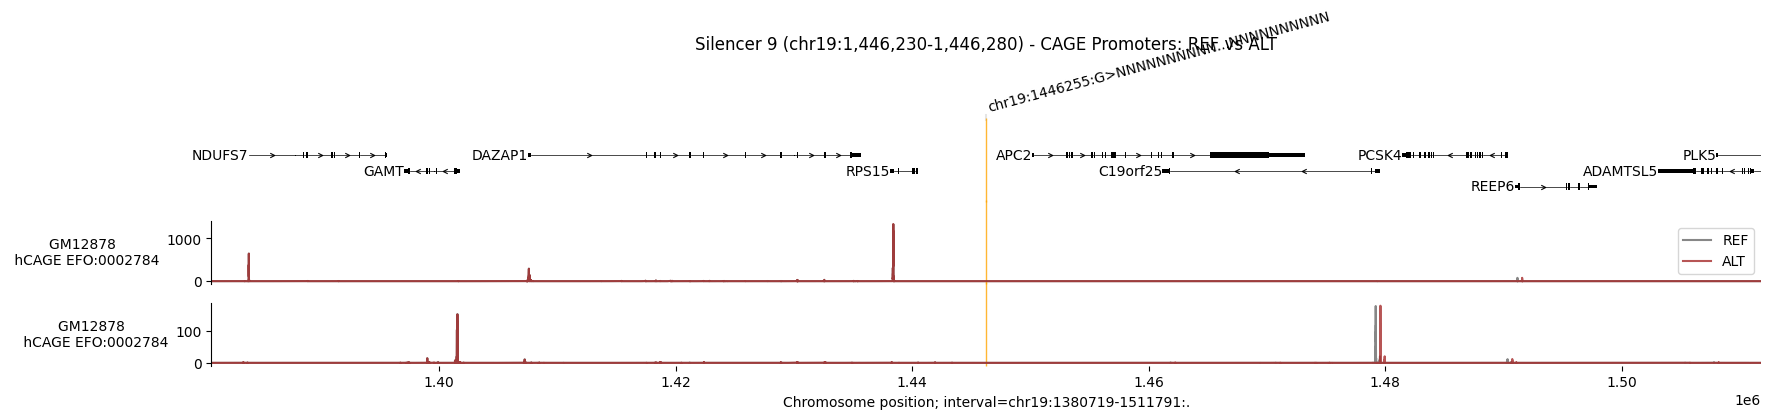

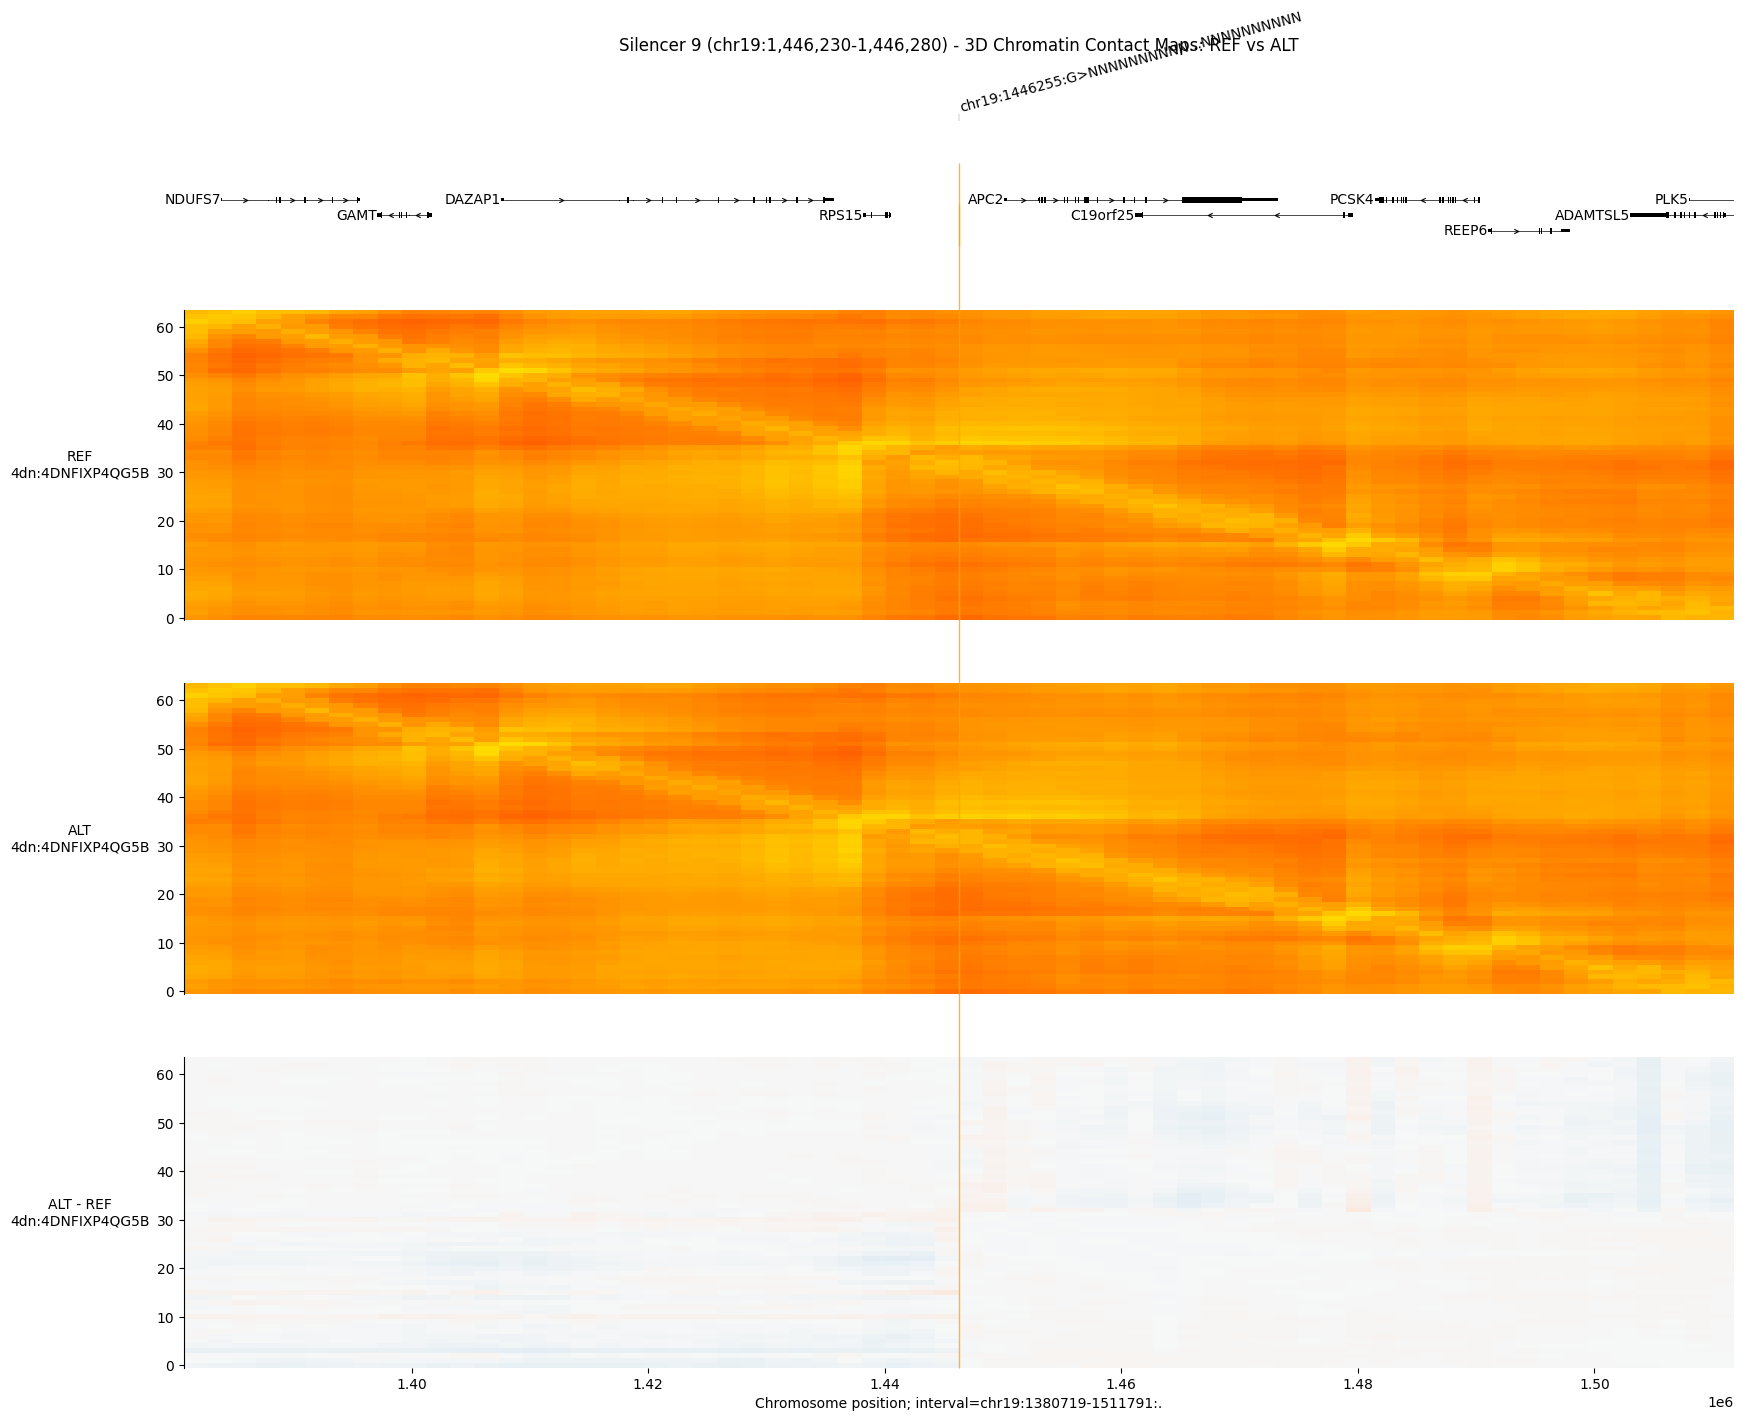

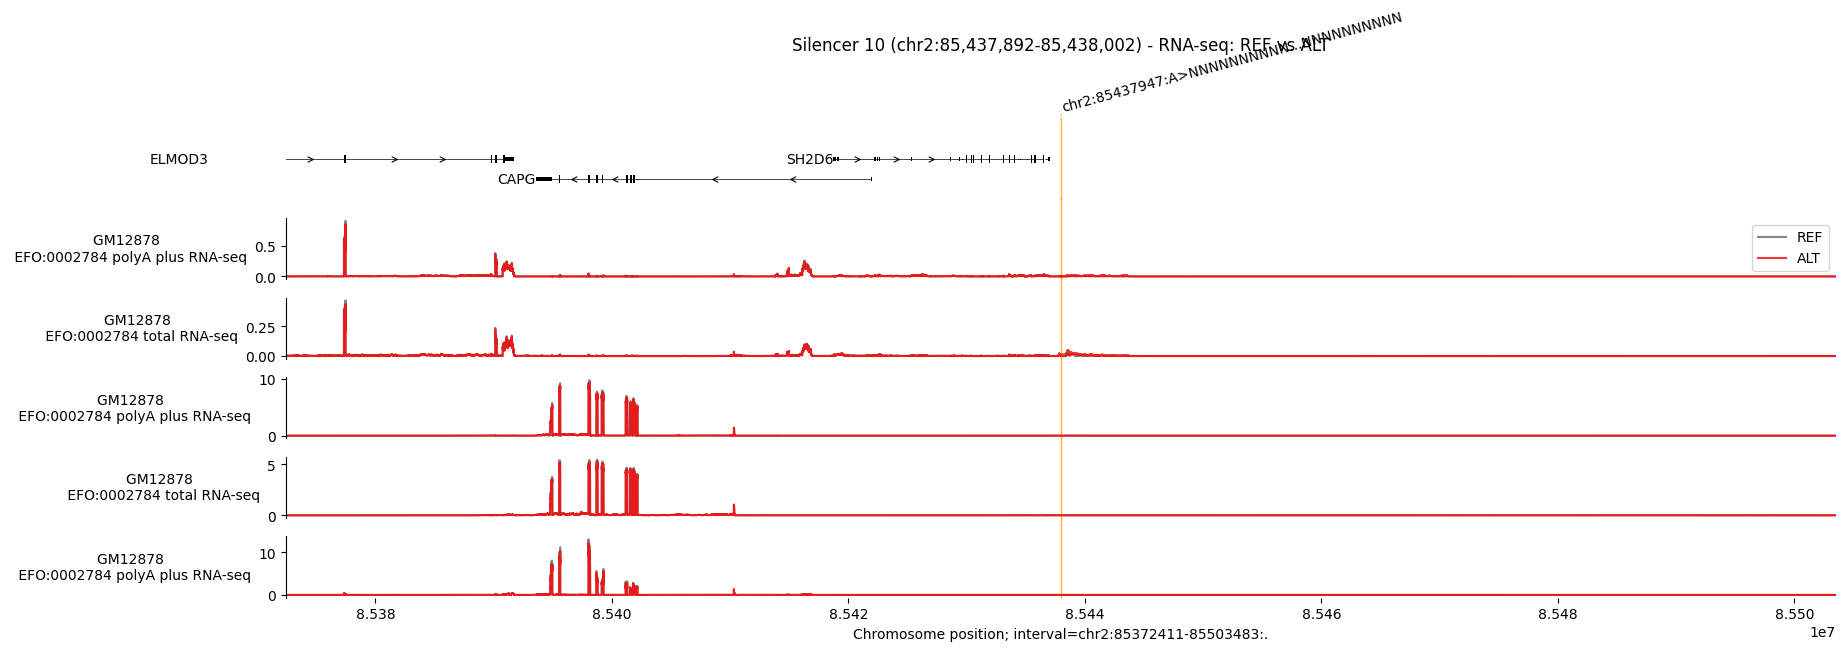

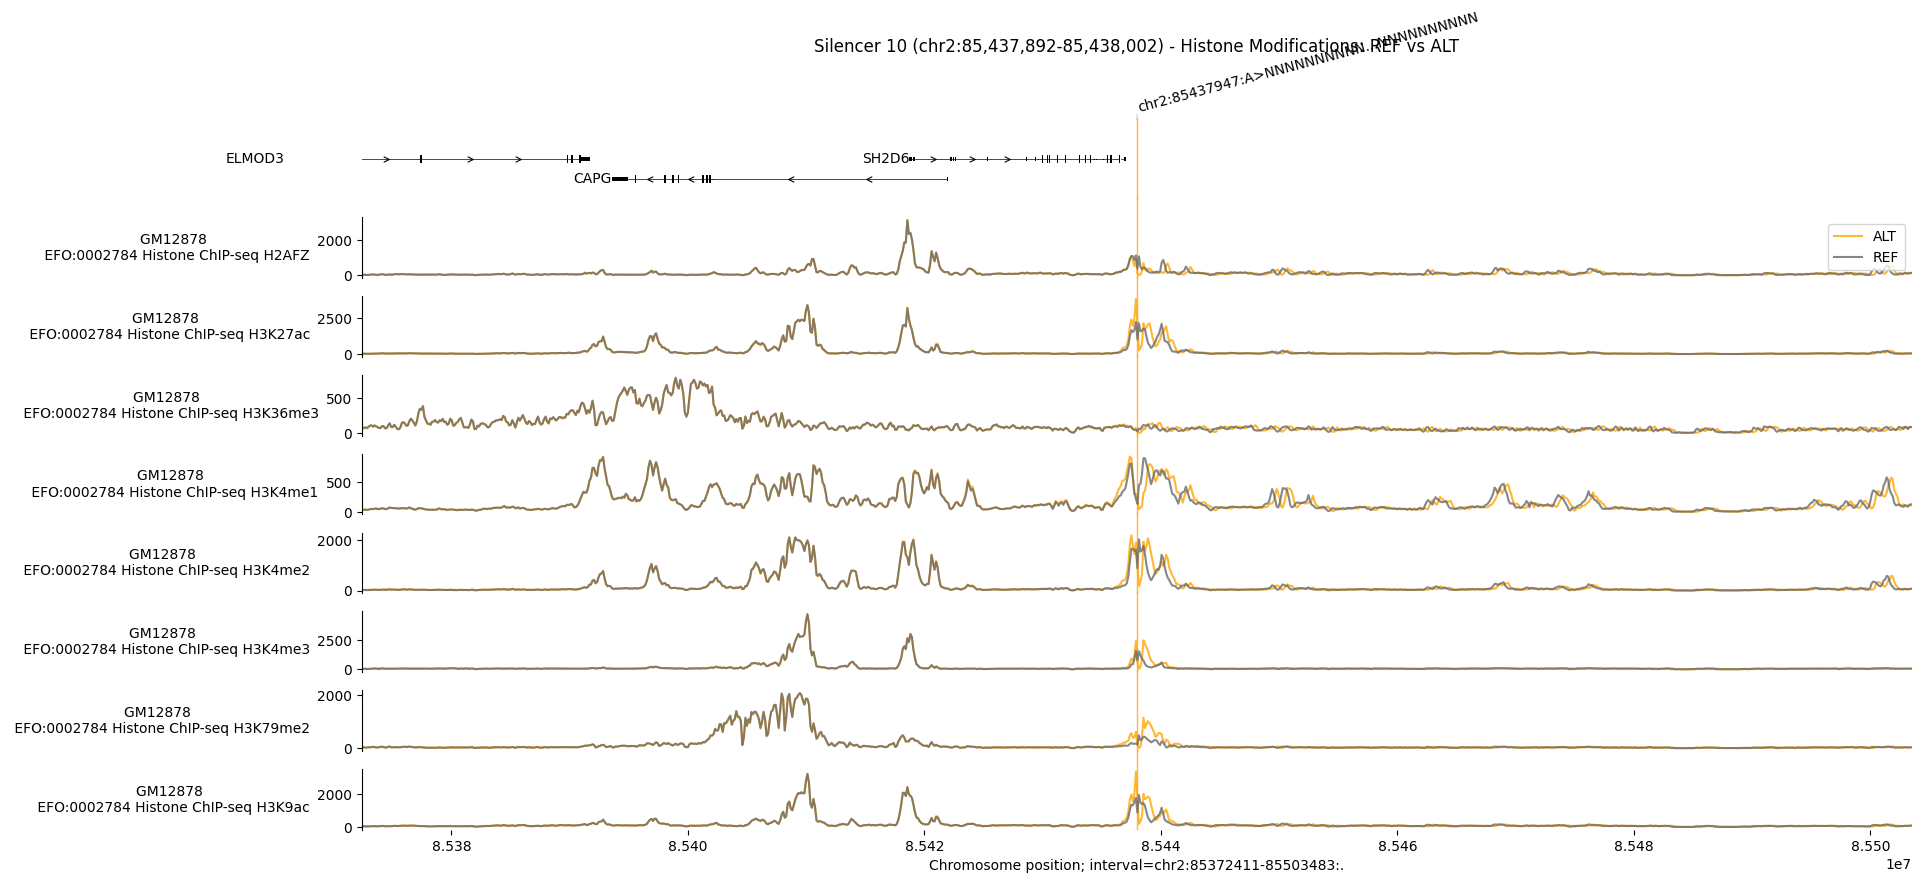

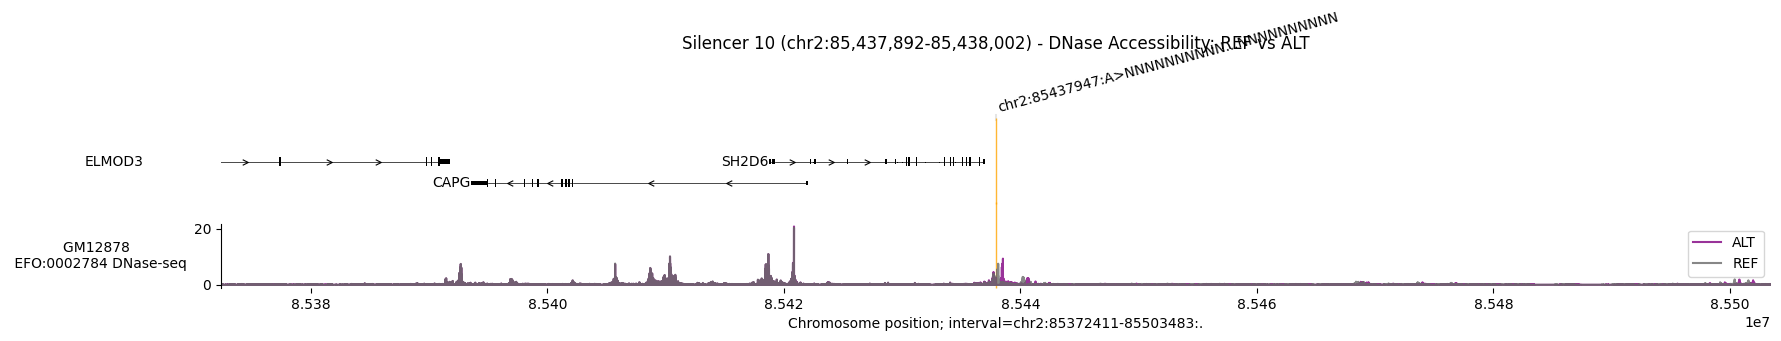

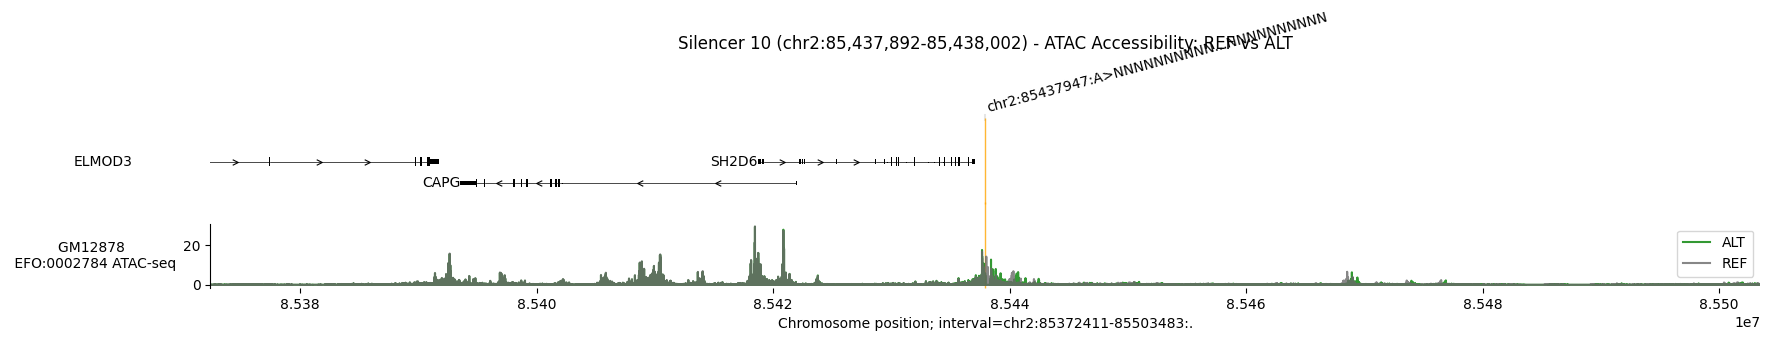

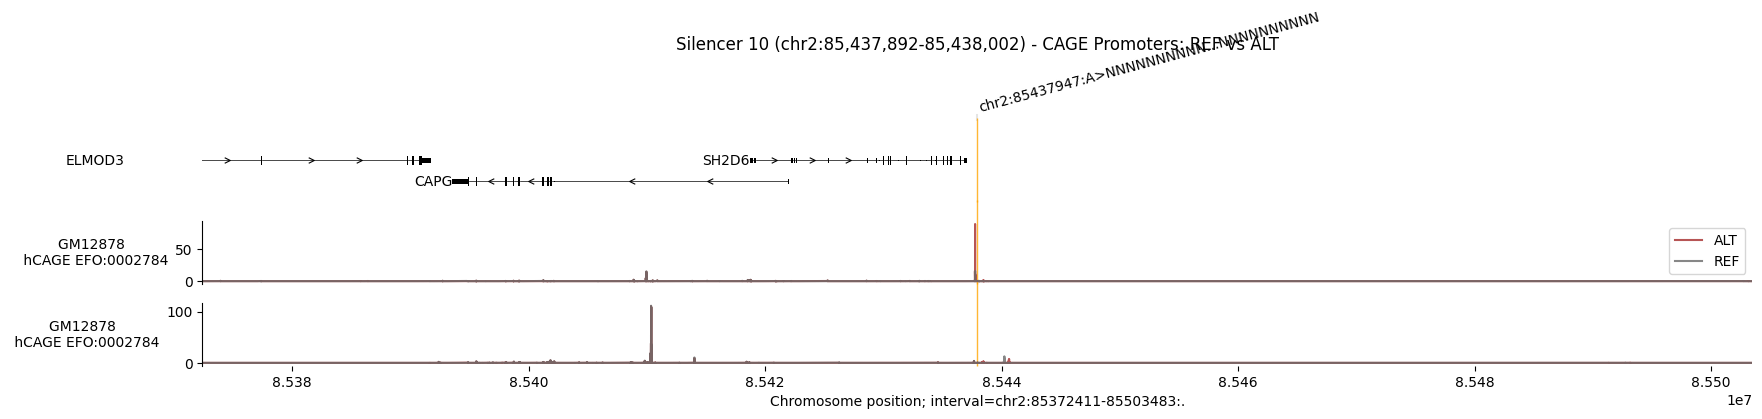

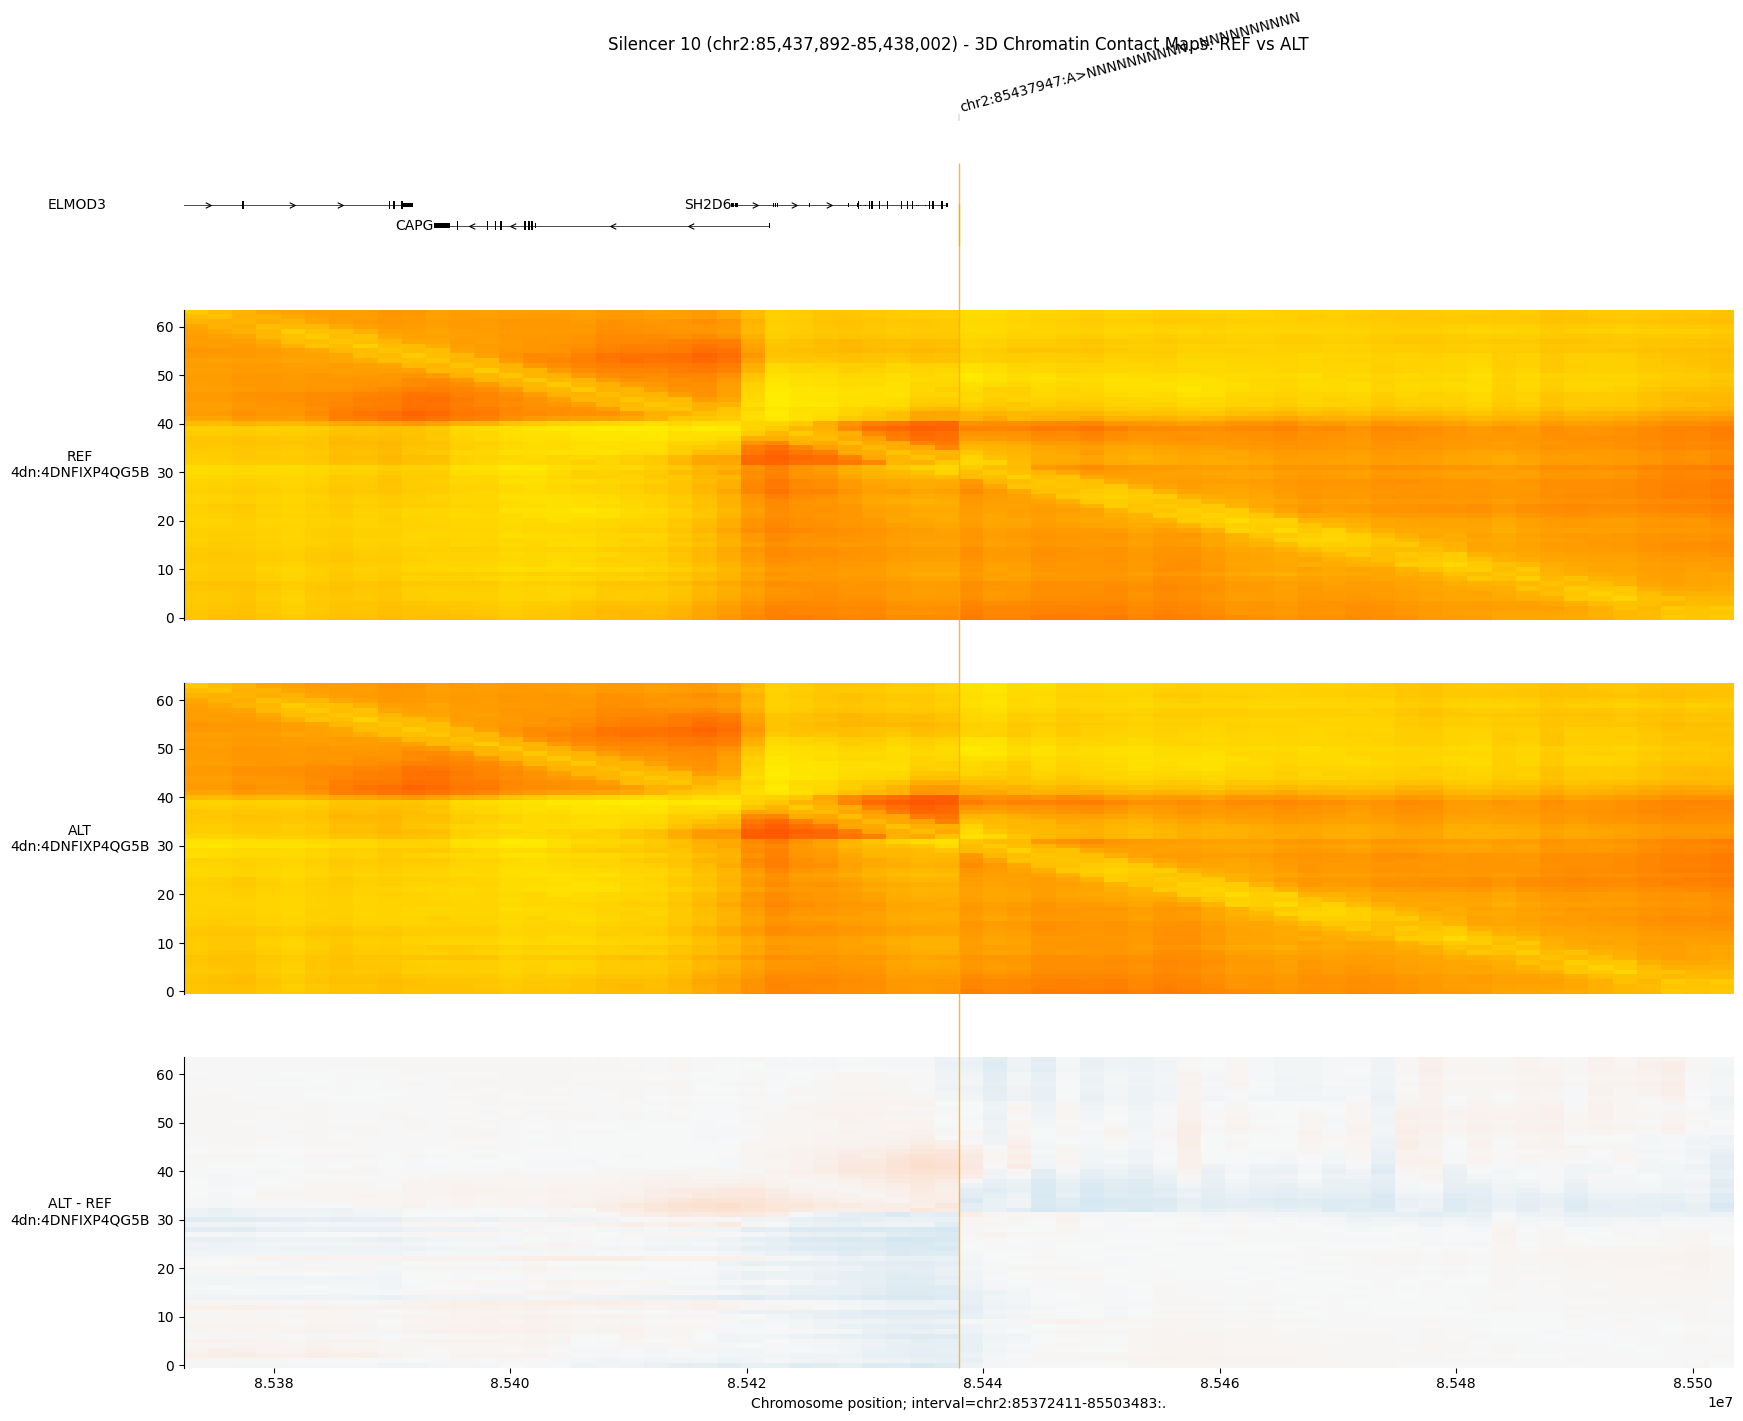

In [8]:
track_plots = [
    ('rna_seq', 'RNA-seq', 'red'),
    ('chip_histone', 'Histone Modifications', 'orange'),
    ('dnase', 'DNase Accessibility', 'purple'),
    ('atac', 'ATAC Accessibility', 'green'),
    ('cage', 'CAGE Promoters', 'brown'),
]


def plot_silencer(rank):
    variant = variants[rank]
    variant_output = variant_outputs[rank]
    transcripts = transcripts_by_rank[rank]
    label = f"Silencer {rank} ({silencers.loc[rank, 'silencer']})"

    for attr, title, color in track_plots:
        ref = getattr(variant_output.reference, attr)
        alt = getattr(variant_output.alternate, attr)
        if ref is None or ref.num_tracks == 0:
            print(f"{label}: no {title} tracks for the selected biosamples")
            continue
        plot_components.plot(
            [
                plot_components.TranscriptAnnotation(transcripts),
                plot_components.OverlaidTracks(
                    tdata={'REF': ref, 'ALT': alt},
                    colors={'REF': 'dimgrey', 'ALT': color},
                    ylabel_template='{biosample_name} \n {name}',
                ),
            ],
            interval=ref.interval,
            annotations=[plot_components.VariantAnnotation([variant], alpha=0.8)],
            title=f'{label} - {title}: REF vs ALT',
        )
        plt.show()

    # Contact maps: REF, ALT and ALT - REF for each track
    ref_cm = variant_output.reference.contact_maps
    alt_cm = variant_output.alternate.contact_maps
    if ref_cm is None or ref_cm.num_tracks == 0:
        print(f"{label}: no contact map tracks for the selected biosamples")
        return
    for i in range(ref_cm.num_tracks):
        ref_i = ref_cm.select_tracks_by_index([i])
        alt_i = alt_cm.select_tracks_by_index([i])
        plot_components.plot(
            [
                plot_components.TranscriptAnnotation(transcripts),
                plot_components.ContactMaps(ref_i, ylabel_template='REF\n{name}', track_height=5),
                plot_components.ContactMaps(alt_i, ylabel_template='ALT\n{name}', track_height=5),
                plot_components.ContactMapsDiff(alt_i - ref_i, ylabel_template='ALT - REF\n{name}', track_height=5),
            ],
            interval=ref_cm.interval,
            annotations=[plot_components.VariantAnnotation([variant], alpha=0.8)],
            title=f'{label} - 3D Chromatin Contact Maps: REF vs ALT',
        )
        plt.show()


for rank in variants:
    plot_silencer(rank)

## Variant scoring (quantile-calibrated)

Scores each silencer variant with the recommended scorers over a 1 Mb window and keeps only GM12878 tracks. `quantile_score` places the effect within the genome-wide reference distribution for that scorer/track (RNA_SEQ quantiles can be negative).

In [9]:
selected_scorers = ["RNA_SEQ", "CHIP_HISTONE_ACTIVE", "ATAC_ACTIVE", "DNASE_ACTIVE", "CAGE_ACTIVE", "CHIP_TF_ACTIVE"]

variant_scores_by_rank = {}
for rank, variant in variants.items():
    variant_scores = model.score_variant(
        interval=variant.reference_interval.resize(dna_client.SEQUENCE_LENGTH_1MB),
        variant=variant,
        variant_scorers=[variant_scorers.RECOMMENDED_VARIANT_SCORERS[name] for name in selected_scorers],
    )
    for name, scores in zip(selected_scorers, variant_scores):
        if "quantiles" not in scores.layers:
            raise RuntimeError(f"{name}: no quantile layer; check calibration_path in organism_settings.")
    variant_scores_by_rank[rank] = variant_scores
    print(f"Silencer {rank} ({silencers.loc[rank, 'silencer']}): scoring complete with quantiles")

Silencer 1 (chr12:111,598,679-111,598,729): scoring complete with quantiles
Silencer 2 (chr12:131,894,291-131,894,341): scoring complete with quantiles
Silencer 3 (chr16:2,538,167-2,538,297): scoring complete with quantiles
Silencer 4 (chr17:81,960,043-81,960,123): scoring complete with quantiles
Silencer 5 (chr14:101,705,882-101,706,002): scoring complete with quantiles
Silencer 6 (chr11:130,002,078-130,002,128): scoring complete with quantiles
Silencer 7 (chr6:1,604,719-1,604,789): scoring complete with quantiles
Silencer 8 (chr8:124,371,723-124,371,773): scoring complete with quantiles
Silencer 9 (chr19:1,446,230-1,446,280): scoring complete with quantiles
Silencer 10 (chr2:85,437,892-85,438,002): scoring complete with quantiles


In [10]:
df_scores = pd.concat(
    [
        variant_scorers.tidy_scores([scores], match_gene_strand=True)
        .assign(rank=rank, silencer=silencers.loc[rank, "silencer"])
        for rank, scores in variant_scores_by_rank.items()
    ],
    ignore_index=True,
)
df_gm = df_scores[df_scores["ontology_curie"].isin(matching_terms.values())].copy()
df_gm["abs_quantile"] = df_gm["quantile_score"].abs()
df_gm = df_gm.sort_values(["rank", "abs_quantile"], ascending=[True, False])

print(f"{len(df_gm)} GM12878 scores (of {len(df_scores)} total)")
# Signed quantile of the strongest GM12878 effect per silencer and output type.
strongest = (
    df_gm.groupby(["rank", "silencer", "output_type"]).head(1)
    .pivot(index=["rank", "silencer"], columns="output_type", values="quantile_score")
)
display(strongest)

with pd.option_context("display.max_columns", None):
    display(df_gm.groupby("rank").head(10))

/data/Dcode/gaetano/projects/AlphaGenome_IvanT/.venv/lib/python3.11/site-packages/alphagenome/models/v1/variant_scorers.py:869: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  concatenated_df = pd.concat(tidied_anndata, axis=0, ignore_index=True)
/data/Dcode/gaetano/projects/AlphaGenome_IvanT/.venv/lib/python3.11/site-packages/alphagenome/models/v1/variant_scorers.py:869: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  concatenated_df = pd.concat(tidied_anndata, axis=0, ignore_index=True)
/data/Dcod

2136 GM12878 scores (of 224123 total)


/data/Dcode/gaetano/projects/AlphaGenome_IvanT/.venv/lib/python3.11/site-packages/alphagenome/models/v1/variant_scorers.py:869: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  concatenated_df = pd.concat(tidied_anndata, axis=0, ignore_index=True)
/data/Dcode/gaetano/projects/AlphaGenome_IvanT/.venv/lib/python3.11/site-packages/alphagenome/models/v1/variant_scorers.py:869: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  concatenated_df = pd.concat(tidied_anndata, axis=0, ignore_index=True)
/data/Dcod

,output_type,ATAC,CAGE,CHIP_HISTONE,CHIP_TF,DNASE,RNA_SEQ
rank,silencer,,,,,,
1,"chr12:111,598,679-111,598,729",0.984170,0.989962,0.999775,0.997793,0.958425,0.999980
2,"chr12:131,894,291-131,894,341",0.989730,0.960225,0.977769,0.995066,0.987952,-0.999844
3,"chr16:2,538,167-2,538,297",0.991829,0.998640,0.986803,0.999764,0.973383,0.999947
4,"chr17:81,960,043-81,960,123",0.975672,0.939662,0.974553,0.999990,0.938341,0.999980
5,"chr14:101,705,882-101,706,002",0.960225,0.876654,0.980143,0.990627,0.899514,0.999918
6,"chr11:130,002,078-130,002,128",0.993351,0.995287,0.999015,0.998815,0.978751,0.999970
7,"chr6:1,604,719-1,604,789",0.983055,0.966706,0.968863,0.999970,0.950415,-0.999938
8,"chr8:124,371,723-124,371,773",0.992713,0.988224,0.994337,0.994834,0.970885,0.999904
9,"chr19:1,446,230-1,446,280",0.947050,0.945881,0.975672,0.996583,0.855269,-0.999769


,variant_id,scored_interval,gene_id,gene_name,gene_type,gene_strand,junction_Start,junction_End,output_type,variant_scorer,track_name,track_strand,Assay title,ontology_curie,biosample_name,biosample_type,biosample_life_stage,gtex_tissue,data_source,endedness,genetically_modified,histone_mark,transcription_factor,raw_score,quantile_score,rank,silencer,abs_quantile
4234,chr12:111598704:C>NNNNNNNNNNNNNNNNNNNNNNNNNNNN...,chr12:111074416-112122992:.,ENSG00000258099,ATXN2-AS,lncRNA,+,None,None,RNA_SEQ,GeneMaskLFCScorer(requested_output=RNA_SEQ),EFO:0002784 polyA plus RNA-seq,.,polyA plus RNA-seq,EFO:0002784,GM12878,cell_line,adult,,encode,paired,False,NaN,NaN,0.324043,0.999980,1,"chr12:111,598,679-111,598,729",0.999980
4266,chr12:111598704:C>NNNNNNNNNNNNNNNNNNNNNNNNNNNN...,chr12:111074416-112122992:.,ENSG00000258099,ATXN2-AS,lncRNA,+,None,None,RNA_SEQ,GeneMaskLFCScorer(requested_output=RNA_SEQ),EFO:0002784 total RNA-seq,.,total RNA-seq,EFO:0002784,GM12878,cell_line,adult,,encode,paired,False,NaN,NaN,0.242835,0.999979,1,"chr12:111,598,679-111,598,729",0.999979
4232,chr12:111598704:C>NNNNNNNNNNNNNNNNNNNNNNNNNNNN...,chr12:111074416-112122992:.,ENSG00000272215,U7,snRNA,-,None,None,RNA_SEQ,GeneMaskLFCScorer(requested_output=RNA_SEQ),EFO:0002784 polyA plus RNA-seq,.,polyA plus RNA-seq,EFO:0002784,GM12878,cell_line,adult,,encode,paired,False,NaN,NaN,0.135588,0.999952,1,"chr12:111,598,679-111,598,729",0.999952
4264,chr12:111598704:C>NNNNNNNNNNNNNNNNNNNNNNNNNNNN...,chr12:111074416-112122992:.,ENSG00000272215,U7,snRNA,-,None,None,RNA_SEQ,GeneMaskLFCScorer(requested_output=RNA_SEQ),EFO:0002784 total RNA-seq,.,total RNA-seq,EFO:0002784,GM12878,cell_line,adult,,encode,paired,False,NaN,NaN,0.074977,0.999887,1,"chr12:111,598,679-111,598,729",0.999887
12322,chr12:111598704:C>NNNNNNNNNNNNNNNNNNNNNNNNNNNN...,chr12:111074416-112122992:.,None,None,None,NaN,None,None,CHIP_HISTONE,CenterMaskScorer(requested_output=CHIP_HISTONE...,EFO:0002784 Histone ChIP-seq H3K4me3,.,Histone ChIP-seq,EFO:0002784,GM12878,cell_line,adult,NaN,encode,single,False,H3K4me3,NaN,67984.000000,0.999775,1,"chr12:111,598,679-111,598,729",0.999775
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
208020,chr2:85437947:A>NNNNNNNNNNNNNNNNNNNNNNNNNNNNNN...,chr2:84913659-85962235:.,ENSG00000152292,SH2D6,protein_coding,+,None,None,RNA_SEQ,GeneMaskLFCScorer(requested_output=RNA_SEQ),EFO:0002784 total RNA-seq,.,total RNA-seq,EFO:0002784,GM12878,cell_line,adult,,encode,paired,False,NaN,NaN,0.091024,0.999879,10,"chr2:85,437,892-85,438,002",0.999879
223771,chr2:85437947:A>NNNNNNNNNNNNNNNNNNNNNNNNNNNNNN...,chr2:84913659-85962235:.,None,None,None,NaN,None,None,CHIP_TF,"CenterMaskScorer(requested_output=CHIP_TF, wid...",EFO:0002784 TF ChIP-seq ZNF687,.,TF ChIP-seq,EFO:0002784,GM12878,cell_line,adult,NaN,encode,paired,False,NaN,ZNF687,1620.750000,0.999689,10,"chr2:85,437,892-85,438,002",0.999689
207967,chr2:85437947:A>NNNNNNNNNNNNNNNNNNNNNNNNNNNNNN...,chr2:84913659-85962235:.,ENSG00000286011,ENSG00000286011,lncRNA,+,None,None,RNA_SEQ,GeneMaskLFCScorer(requested_output=RNA_SEQ),EFO:0002784 polyA plus RNA-seq,.,polyA plus RNA-seq,EFO:0002784,GM12878,cell_line,adult,,encode,paired,False,NaN,NaN,0.042560,0.999580,10,"chr2:85,437,892-85,438,002",0.999580
223675,chr2:85437947:A>NNNNNNNNNNNNNNNNNNNNNNNNNNNNNN...,chr2:84913659-85962235:.,None,None,None,NaN,None,None,CHIP_TF,"CenterMaskScorer(requested_output=CHIP_TF, wid...",EFO:0002784 TF ChIP-seq BACH1,.,TF ChIP-seq,EFO:0002784,GM12878,cell_line,adult,NaN,encode,paired,False,NaN,BACH1,2317.250000,0.999433,10,"chr2:85,437,892-85,438,002",0.999433
